---
title: "Two ways to close gas-solid drag: Syamlal-O'Brien against Ergun, and against the velocity-voidage law it stands in for"
description: "The MFIX Theory Guide names two kinds of data a drag law can be built from and picks one. This page builds both, measures where they agree and where they do not, and tests the closed form against the 1954 index it replaces and against measured minimum-fluidisation velocities."
categories: [sec:A, struct:S3, tier:T1, data:tier2, phase:gas-solid]
date: 2026-08-02
---

# Two ways to close gas-solid drag

**Catalog ID:** `A1.8` · **Structures:** `S3` · **Tier:** T1

Every two-fluid simulation of a fluidised bed contains one scalar function that
decides almost everything the answer does: the drag coefficient $F_{gm}$ linking
the gas and the solids momentum equations. There is no first-principles form for
it, and the MFIX Theory Guide states the reason plainly: there are **two kinds
of experiment** you can build one from, and they do not overlap.

> Two types of experimental data can be used to develop fluid-solids drag
> formulas. One type, valid for high value of the solids volume fractions, is
> packed-bed pressure drop data expressed in the form of a correlation, such as
> the Ergun (1952) equation. Such a correlation must be supplemented with a drag
> correlation for low values of the solids volume fractions (Gidaspow 1986). The
> other type of data is available as correlations for the terminal velocity in
> fluidized or settling beds, expressed as a function of void fraction and
> Reynolds number (Richardson and Zaki 1954).
>
> Syamlal, Rogers and O'Brien (1993), journal page 10

That paragraph is the page. It names three closures (an Ergun-based one, a
terminal-velocity-based one, and the blend rule that patches the first at low
solids fraction). This page builds the two it prints in full, puts numbers on
where they agree and where they do not, and tests each against a measurement.

**Scope, stated before anything else.** The catalogue asks for
Gidaspow / Syamlal-O'Brien / Wen-Yu. The report on disk carries
**Syamlal-O'Brien complete** and **neither of the other two drag closures**: the
strings *"Wen and Yu"* and *"Wen & Yu"* do not occur anywhere in it, and it
prints **no Gidaspow drag law and no blend rule**. Gidaspow (1986) is cited
exactly once in §2.2.1, for the sentence quoted above.

That last sentence is narrower than it looks. Gidaspow is **not** a marginal
presence in this report: the name runs through the introduction, the
ill-posedness discussion, the solids-stress section and the heat-transfer
section, appears as first author on several entries of the reference list, and
the report **adopts a Ding & Gidaspow (1990) expression as its own eq. (88)** for
granular-energy transfer and a Syamlal & Gidaspow (1985) model for solids
conductivity. What is absent is specifically a *drag* closure of that name,
which is the only thing this page needs to be true. Nothing about either missing
closure is written here from memory. What replaces them is the pair the report's
own paragraph points at, both on disk: **Ergun (1952)**, through the published
page [`A1.1`](../A1.1-ergun-pressure-drop/), and **Richardson & Zaki (1954)**,
which is the correlation Syamlal-O'Brien's closed form is a substitute for. The
[Reuse](#reuse) section says exactly what document would complete the
three-way comparison the catalogue names.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "gallery-2026.11.10"  # replaced by the release tag at publication
PYMRM = ">=3.4.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "A1.8-gas-solid-drag-closures"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
# Imports. Packages beyond pymrm and the Colab defaults (numpy, scipy, pandas,
# matplotlib, pyyaml) are installed here with subprocess, not %pip. The only pymrm
# call on this page is find_roots (see "What pymrm adds").
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import colormaps
from IPython.display import Markdown, display
from pymrm.checks import find_roots
from gallery_utils import Claims, cite_data, load_claims, load_data, load_meta

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)
claims = Claims(PAGE.split("-")[0])
PAGE_A11 = "A1.1-ergun-pressure-drop"        # Ergun's constants and his marker file
PAGE_A16 = "A1.6-wen-yu-minimum-fluidisation"  # the same Geldart rows, against Wen and Yu
PAGE_A17 = "A1.7-geldart-classification"     # the measured minimum-fluidisation velocities
BREAK = []   # (injected defect, claim, clean value, broken value, caught)

# Okabe-Ito, assigned in a fixed order and never cycled:
#   0 Ergun (packed-bed route)  1 Syamlal-O'Brien  2 Richardson-Zaki  3 measured
COL = {"ergun": "#0072B2", "so": "#D55E00", "rz": "#009E73", "meas": "#E69F00"}


def brk(row, metric, broken):
    """One injected defect: ``broken`` is what claim ``metric`` becomes with it."""
    caught = claims.breaks(row, metric, broken)
    BREAK.append((row, metric, claims[metric], broken, caught))
    return caught


def brk_all(row, got):
    """Break row for every claim of a group: ``got`` maps claim names to the values the
    helper returns when it is called with the defect injected."""
    for name, v in got.items():
        if name in claims.metrics:
            brk(row, name, v)


def brk_helper(row, helper, names, *args, **kw):
    """Break rows from ``helper(*args, **kw)``. Where the defect leaves no root on the whole
    physical range (the helper's ``find_roots`` scan raises ``ValueError``), every claim in
    ``names`` records nan, and the row says so."""
    try:
        got = helper(*args, **kw)
    except ValueError as exc:
        got = {n: float("nan") for n in names}
        row = f"{row} (no admissible root on the whole range: {exc})"
    return brk_all(row, got)


def say(text, **kw):
    """Put computed numbers into prose: ``@@name@@`` is replaced by ``kw['name']``."""
    for k, v in kw.items():
        text = text.replace(f"@@{k}@@", str(v))
    assert "@@" not in text, "unfilled placeholder"
    display(Markdown(text))


def one_root(f, lo, hi, n=64, log=False, xtol=1e-14):
    """The single root of ``f`` on the physical range ``[lo, hi]`` by pymrm's
    ``find_roots``; raises ``ValueError`` unless exactly one sign change is found."""
    found = find_roots(f, lo, hi, n_scan=n, log=log, xtol=xtol)
    if len(found["roots"]) != 1:
        raise ValueError(f"expected one root on [{lo:.4g}, {hi:.4g}]: {found['message']}")
    return found["roots"][0]


def n_roots(f, lo, hi, want, n=64, log=False, xtol=1e-14):
    """All roots of ``f`` on ``[lo, hi]``; raises unless there are exactly ``want``."""
    found = find_roots(f, lo, hi, n_scan=n, log=log, xtol=xtol)
    if len(found["roots"]) != want:
        raise ValueError(f"expected {want} roots on [{lo:.4g}, {hi:.4g}]: {found['message']}")
    return found["roots"]

## Background

### Where the closure sits

The report's momentum equations, journal pages 7–9, are the standard two-fluid
pair. For the gas (eq. 7) and for the $m$-th solids phase (eq. 8),

$$
\frac{\partial}{\partial t}(\epsilon_g\rho_g\vec v_g) + \nabla\!\cdot(\epsilon_g\rho_g\vec v_g\vec v_g)
= \nabla\!\cdot\overline{S}_g + \epsilon_g\rho_g\vec g - \sum_m \vec I_{gm} + \vec f_g ,
$$

$$
\frac{\partial}{\partial t}(\epsilon_{sm}\rho_{sm}\vec v_{sm}) + \nabla\!\cdot(\epsilon_{sm}\rho_{sm}\vec v_{sm}\vec v_{sm})
= \nabla\!\cdot\overline{S}_{sm} + \epsilon_{sm}\rho_{sm}\vec g + \vec I_{gm} - \sum_{l\neq m} \vec I_{ml} ,
$$

coupled through the interaction force of eq. (9),

$$
\vec I_{gm} = -\epsilon_{sm}\nabla P_g \;-\; F_{gm}(\vec v_{sm}-\vec v_g)
\;+\; R_{0m}\left[\xi_{0m}\vec v_{sm} + \bar\xi_{0m}\vec v_g\right] ,
$$

whose three terms the report labels buoyancy, drag, and momentum transfer
accompanying mass transfer. **Everything on this page is about the single
scalar $F_{gm}$.**

Two consequences of that structure are used throughout, and both are derived
from the equations above rather than assumed.

**In a fixed bed** ($\vec v_{sm}=0$) the gas equation collapses to
$\;(-\mathrm{d}P/\mathrm{d}z)_{\text{friction}} = F_{gm}\,U/\epsilon_g^2$, with
$U$ the superficial velocity. That is what converts a pressure-drop correlation
into a drag coefficient, and it is how Ergun enters this page.

**In a uniformly fluidised or settling bed**, summing the two equations gives
$\mathrm{d}P/\mathrm{d}z = -(\epsilon_g\rho_g + \epsilon_s\rho_s)g$, and
substituting back into the solids equation gives

$$
F_{gm}\,|\vec v_g - \vec v_{sm}| \;=\; \epsilon_s\,\epsilon_g\,(\rho_s-\rho_g)\,g .
$$

Note the $\epsilon_g$ on the right: the buoyancy is on the *mixture* density, not
on the gas density. This relation holds for batch sedimentation and for
fluidisation alike, which is exactly the equivalence Richardson and Zaki
established experimentally, and it is what lets a terminal-velocity correlation
be converted into a drag law at all.

### Why there are two families and not one

A packed-bed pressure-drop correlation is measured where the particles touch. It
is at its best at packed-bed voidage and it has nothing to say about an isolated
particle: as the report notes, it "must be supplemented" at low solids fraction.
A hindered-settling correlation is measured across the whole range from a packed
bed to infinite dilution, but it is fitted to a *velocity*, not to a force, and
the conversion needs a single-sphere drag curve to lean on.

The three closures the catalogue names are three answers:

- **Ergun-based**, extended into the dilute limit by a blend rule (the shape
  attributed to Gidaspow (1994)), and the one this page cannot build.
- **Syamlal-O'Brien**, which converts a hindered-settling correlation, and so
  covers the whole voidage range with one continuous expression and no blend.
- **Wen-Yu**, a single-sphere drag curve with a voidage correction, which is the
  other half of the blend and is also not in the document on disk.

So this page can put the *first two families* against each other over the whole
$(\epsilon_g, Re)$ plane, and against measurement, which is the comparison the
report's own paragraph sets up.

## The published model

### Syamlal-O'Brien, exactly as printed

Section 2.2.1, journal pages 10–11, read on 400 dpi renders, which is the
embedded page images' own native resolution, since they are bilevel CCITT at
400 dpi. **The text layer of this report must not be used for any digit.** It
renders $0.06\,Re$ as `0.O6Re` with a capital letter O, $\epsilon_g^{2.65}$ as
`_g-2'6s`, "Ergun (1952)" as `Ergun (f952)`, and the equation numbers (12) and
(16) as `(121` and `(1''`.

$$
F_{gm} = \frac{3\,\epsilon_{sm}\,\epsilon_g\,\rho_g}{4\,V_{rm}^2\,d_{pm}}\;
C_{Ds}\!\left(\frac{Re_m}{V_{rm}}\right)\,\left|\vec v_{sm}-\vec v_g\right| \tag{11}
$$

$$
V_{rm} = 0.5\left(A - 0.06\,Re_m + \sqrt{(0.06\,Re_m)^2 + 0.12\,Re_m(2B-A) + A^2}\right) \tag{12}
$$

$$
A = \epsilon_g^{4.14} \tag{13}
$$

$$
B = \begin{cases} 0.8\,\epsilon_g^{1.28} & \epsilon_g \le 0.85\\[2pt]
\epsilon_g^{2.65} & \epsilon_g > 0.85\end{cases} \tag{14}
$$

$$
Re_m = \frac{d_{pm}\,|\vec v_{sm}-\vec v_g|\,\rho_g}{\mu_g} \tag{15}
$$

$$
C_{Ds}(Re) = \left(0.63 + \frac{4.8}{\sqrt{Re}}\right)^2 \tag{16}
$$

and the sentence under eq. (16), which is easy to miss and load-bearing: *"To use
this formula in equation (11), note that Re must be replaced with
$Re_m/V_{rm}$."* The eleven constants in these equations are the dataset
`mfix-1993-syamlal-obrien-constants.csv`; the code reads them from it, so the
equations above are the only place they are typed.

**Attribution, as the report gives it**, and it is worth reading its own
reference list rather than the catalogue's. Eq. (12) with (13)–(14) is from
*Garside and Al-Dibouni (1977)*, `I&EC Proc. Des. Dev.` 16, 206–214; eq. (16) is
*Dalla Valle (1948)*, `Micromeritics`, Pitman. Neither is on disk and neither was
consulted; this page reads both from the 1993 report, which prints them in full
with attribution, the reprint route of `AGENTS.md`.

Eq. (11) is a different matter. The report attributes it to *Syamlal and O'Brien
(1987)*, and its reference list gives that as **"A Generalized Drag Correlation
for Multiparticle Systems," Unpublished report**, read on a 400 dpi render of
report page 44. So there is no origin paper to go and get: **this DOE report is
not a convenient source for the conversion, it is the citable published one.**
The catalogue's citation for the case, "Syamlal & O'Brien (1989)", is a
*different* item in the same list, "Computer Simulation of Bubbles in a
Fluidized Bed", AIChE Symposium Series No. 270, 85, 22–31, which is a
bubble-simulation paper, not the drag derivation.

**There is no sphericity anywhere in this closure**, and the report says why. Its
paragraph "Four" on journal page 9 states that these formulations "deal with
uniform, smooth, spherical particles", that real systems do not, and that "there
are no well-accepted ways of treating such effects". That asymmetry against Ergun
matters later and is not a criticism: it is printed.

### Ergun, written as a drag coefficient

From [`A1.1`](../A1.1-ergun-pressure-drop/), Ergun's eq. (13c) with the two
constants that page prints. Substituting the fixed-bed relation above,
$(-\mathrm{d}P/\mathrm{d}z) = F_{gm}U/\epsilon_g^2$, and
$U = \epsilon_g v_{\text{slip}}$,

$$
F_{gm}^{\,\text{Ergun}}
= \frac{k_1\,\mu\,\epsilon_s^2}{\epsilon_g\,d_p^2}
\;+\; \frac{k_2\,\rho_g\,\epsilon_s\,|v_{\text{slip}}|}{d_p} .
$$

This is a *reading* of Ergun as a momentum-exchange coefficient, not something
Ergun wrote; the algebra is one line and is shown above. The constants are loaded
from `A1.1`'s dataset rather than typed.

### Richardson and Zaki, the correlation the closed form replaces

The report says $V_{rm}$ "can be calculated from the Richardson and Zaki (1954)
correlation only numerically; an explicit formula cannot be derived", and adopts
Garside and Al-Dibouni's closed form instead. That makes Richardson and Zaki the
natural reference for eqs. (12)–(14): **not an independent theory, but the thing
the substitution is a substitute for.**

Read from the verbatim Golden Jubilee reprint, `Trans IChemE` 75 (1997) S82–S100,
on 300 dpi renders (again the native resolution of the embedded bilevel images).
Their eq. (29), reprint page S93,

$$
\frac{V_c}{V_i} = \epsilon^{\,n}
$$

with $V_c$ "the falling velocity, relative to a fixed horizontal plane, of a
suspension of voidage $\epsilon$" and $V_i$ its value extrapolated to
$\epsilon = 1$; $V_i \to V_0$, the single-particle terminal velocity, as
$d/D \to 0$. Their Summary and Conclusions states the equivalence the whole thing
rests on:

> It has been shown that the falling velocity of a suspension relative to a fixed
> horizontal plane is equal to the upward velocity of liquid (based on the empty
> tube) required to maintain a suspension at the same concentration.

so $V_c$ is a **superficial** velocity in both processes. Two asymptotes are
printed on reprint page S94: $n = 4.65 + 19.5\,d/D$ for $Re < 0.2$ (their eq. 33)
and $n = 2.39$ for $Re$ above about 500 (their eq. 34); in between, their
Table VI tabulates $n_0$, the index extrapolated to $d/D = 0$, at eighteen
Reynolds numbers. That table is shipped with this page, and the two asymptotic
values at $d/D = 0$ are the constants `RZ_N_VISCOUS` and `RZ_N_INERTIAL` below.

**The bridge between the two notations is one line, and it is not $V_{rm} =
\epsilon^n$.** Richardson and Zaki's $V_c$ is superficial, so
$V_c = \epsilon_g v_{\text{slip}}$; the force balance above shows (and the
Validation section proves numerically) that Syamlal-O'Brien's $V_{rm}$ is the
*slip* velocity ratio $v_{\text{slip}}/v_t$. Hence

$$
\epsilon_g\,V_{rm}(\epsilon_g, Re) \;\longleftrightarrow\; \epsilon_g^{\,n},
\qquad\text{i.e.}\qquad
n_{\text{implied}} = \frac{\ln\!\left(\epsilon_g V_{rm}\right)}{\ln \epsilon_g} .
$$

Getting that factor of $\epsilon_g$ wrong shifts every index on this page by
exactly 1, an error the same size as the whole effect being measured, so it is
derived rather than asserted, and the derivation is checked in
[Validation](#validation).

## Parameters and assumptions

The closures themselves take no parameters: they are dimensionless functions of
$\epsilon_g$ and $Re$ with printed constants. Everything numerical enters through
the two measured datasets and the handful of inputs below.

**Assumptions carried from the sources.** Steady, isothermal, single solids
phase, no mass transfer, no solids stress, uniform spheres of one size, and a bed
deep enough that the distributor and the free surface do not matter. The drag
comparison assumes the two closures are being asked the same question, a drag
force per unit volume at a given $(\epsilon_g, v_{\text{slip}})$, which is
exactly what the two-fluid equations ask of them, and is *not* the same as
comparing a pressure drop with a settling velocity.

**One asymmetry that cannot be assumed away.** The Ergun form written in the
surface/volume diameter is exactly sphericity-free (`A1.6` demonstrates this),
while Syamlal-O'Brien is a sphere closure with no shape factor at all. So on any
non-spherical powder the two are not being given the same information, and this
page therefore takes its headline on Geldart's spherical cuts only.

| input | value and source |
|---|---|
| Ergun's constants $k_1$, $k_2$ | loaded from `A1.1`'s parameter file |
| gas properties for the $u_{mf}$ test | Geldart's own, as recorded in `A1.7`'s sidecar: $\mu$ and $g$ in `GEL` below |
| gas density for that test | `GEL["rho"]`, air at room conditions. **Geldart prints no gas density**; this is an assumption, and the break table measures what it is worth |
| sphericity | $\phi_s = 1$ on the eight Diakon cuts, read off Geldart's phrase "a plastic moulding powder having spherical particles". See the asymmetry above |
| voidage at minimum fluidisation | $\epsilon_0 = 1 - (1-\epsilon_{MB})H_{MB}/H_0$, the quantity `A1.7` derives from Geldart's two reported columns. Both that and $\epsilon_{MB}$ itself are reported on the page |
| Richardson and Zaki's asymptotes | `RZ_N_VISCOUS` and `RZ_N_INERTIAL`: their eqs. (33) and (34) at $d/D = 0$ |

In [3]:
# Richardson and Zaki (1954), reprint page S94: the two asymptotic indices at d/D = 0
# (eq. 33 at Re < 0.2 with d/D = 0, eq. 34 above Re about 500).
RZ_N_VISCOUS, RZ_N_INERTIAL = 4.65, 2.39
# Illustration only: the closures depend on Re_m alone, this particle in air just turns
# Re_m into a slip velocity. 300 um particle, air at 1.2 kg/m3 and 1.8e-5 Pa s.
D_ILLUS, RHO_ILLUS, MU_ILLUS = 300e-6, 1.2, 1.8e-5
# Check 2: (d_p in m, rho_s in kg/m3, gas voidage) for four decades of size, three voidages
CASES = [(50e-6, 2500.0, 0.40), (300e-6, 2500.0, 0.60), (3e-3, 2500.0, 0.90), (1e-3, 1200.0, 0.50)]
AIR_SI = dict(rho=1.2, mu=1.8e-5, g=9.81)           # kg/m3, Pa s, m/s2
# Check 4, cgs as Geldart gives it: g and mu are his own (A1.7's sidecar); rho is ASSUMED
GEL = dict(g=981.0, mu=1.8e-4, rho=1.2e-3)          # cm/s2, poise, g/cm3

## The data

Four datasets. Two are shipped with this page, two are borrowed, and borrowing
means reading the page that owns them, so what each of those pages has already
established about these exact rows is listed below and reconciled against this
page's own numbers where they overlap.

### 1. The eleven printed constants of eqs. (11)-(16), shipped here

`mfix-1993-syamlal-obrien-constants.csv`. Not data in any evidential sense: they
are the coefficients of a correlation, and reproducing the correlation from them
would be reproduction, not validation. They are a dataset so that every constant
on this page has a single provenance record saying which equation it came from
and that it was read off an image rather than a text layer.

### 2. Richardson and Zaki's Table VI, shipped here

`richardson-zaki-1954-table6.csv`: the velocity-voidage index $n_0$ at
Reynolds numbers from the bottom to the top of the table, extrapolated to zero
wall effect, plus the paper's own two $\log_{10}$ columns.

**This is tier 2 but it is one step from a raw measurement, and the page says so
wherever it is used.** Each $n_0$ is a slope of $\log V_c$ against $\log\epsilon$
fitted by the authors to a run of measurements, and then extrapolated along a
*second* fitted line to $d/D = 0$. Two further limits: the runs are liquid-solid
while the report is a gas-solid code (nothing in eq. 29 is phase-specific, but
the data are not gas-fluidisation data); and the table states no voidage range,
so the window over which an index is compared is a choice made here, with its
sensitivity printed.

**And the two correlations are not independent witnesses.** Garside and
Al-Dibouni fitted their velocity-voidage relation to the same literature
Richardson and Zaki drew on. Comparing them measures **what the substitution the
report makes costs**, which is a real and falsifiable thing, and not "two
independent routes agreeing".

### 3. Ergun's constants and his marker file, borrowed from `A1.1`

What `A1.1` establishes about these exact rows, and whether it bears here:

- **The printed constants are $k_1$, $k_2$ in `ergun-1952-parameters.csv`.** They
  are printed below from that file and never typed into this page's prose.
  *Bears directly: they set the Ergun curve everywhere.*
- **Refitting the two constants to the recovered markers gives a different
  pair**, with a stated $1/f_v$ weighting; unweighted the fit is dominated by a
  handful of high-Reynolds points and returns something else again. That refit is
  **recomputed here from the marker file** with the same weighting, and printed
  beside `A1.1`'s published value. *Bears: it bounds how much of any Ergun /
  Syamlal-O'Brien gap could be Ergun's own constants.*
- **The recovered markers are not all of Ergun's measurements**; the dataset
  carries incomplete recall as a stated limitation. *Does not bear: nothing here
  counts Ergun's measurements, and scattered misses do not move a fit.*
- **`A1.1` measures Ergun's own equation against those markers at a small bias
  and a single-digit mean absolute deviation.** *Bears as context: that is the
  scatter of the correlation on its own data, and it is far smaller than the
  disagreements this page reports.*
- **Eisfeld and Schnitzlein's refit differs from Ergun mostly in the turbulent
  constant, not the famous 150.** *Bears as context: it is not used on this
  page.*

### 4. Geldart's Table 1: measured minimum-fluidisation velocities, borrowed from `A1.7`

What `A1.7` and `A1.6` establish about these exact rows:

- **`U_0` and `U_MB` are measurements; $\epsilon_{MB}$ and $H_{MB}/H_0$ are
  *reported*, method unstated.** `A1.7`'s sidecar forbids calling the latter two
  measurements and this page does not. *Bears directly: the voidage this page
  needs comes from those two columns.*
- **`A1.7` derives $\epsilon_0 = 1-(1-\epsilon_{MB})H_{MB}/H_0$ from a solids
  balance and reports the range it takes over all rows.** This page uses that
  derived quantity, recomputes it, and prints its own range beside `A1.7`'s
  reported one. *Bears directly.*
- **`A1.6` reports the unapproximated Ergun balance as strongly biased at the
  voidage Geldart himself reports on the eight spherical cuts, and calls it
  "worse than the correlation it is being used to judge".** That number is
  **recomputed independently here** and printed beside `A1.6`'s. *Bears directly:
  it is the reason this page does not present Ergun as a reference standard.*
- **`A1.6` reports Wen and Yu's eq. (1) on those same eight rows.** Also
  recomputed here, as a yardstick. *Bears as context.*
- **The one missing `U_0` is an em dash in the printed table**; every other row
  carries one. *Bears: the row counts on this page.*
- **All rows are group A or borderline A/B powders**, with small bed Reynolds
  numbers at minimum fluidisation (the Check 4 table prints them). *Bears heavily:
  the inertial half of every closure here is essentially untested by this
  dataset, and the page says so rather than implying otherwise.*

In [4]:
# ---- shipped with this page ------------------------------------------------
so_const = load_data("mfix-1993-syamlal-obrien-constants.csv", page=PAGE)
so_meta = load_meta("mfix-1993-syamlal-obrien-constants.csv", page=PAGE)
rz = load_data("richardson-zaki-1954-table6.csv", page=PAGE)
rz_meta = load_meta("richardson-zaki-1954-table6.csv", page=PAGE)

# ---- borrowed --------------------------------------------------------------
erg_par = load_data("ergun-1952-parameters.csv", page=PAGE_A11)
erg_mk = load_data("ergun-1952-fig7-markers.csv", page=PAGE_A11)
gd = load_data("geldart_1973_table1.csv", page=PAGE_A17)
gd_meta = load_meta("geldart_1973_table1.csv", page=PAGE_A17)
A11, A16, A17 = load_claims(PAGE_A11), load_claims(PAGE_A16), load_claims(PAGE_A17)

print("Syamlal-O'Brien: the eleven printed constants of eqs. (11)-(16)")
print(so_const.to_string(index=False))
print(f"\n{cite_data(so_meta)}")
print("\n\nRichardson & Zaki (1954) Table VI: the index the closed form stands in for")
print(rz.to_string(index=False))
print(f"\n{cite_data(rz_meta)}")

# every constant is taken from the CSV, never retyped
C = {r.symbol: float(r.value) for r in so_const.itertuples()}
E = {r.quantity: float(r.value) for r in erg_par.itertuples()}
K1_PRINT, K2_PRINT = E["k1_viscous_constant"], E["k2_kinetic_constant"]
print(f"\n\nErgun's printed constants, read out of A1.1's parameter file: "
      f"k1 = {K1_PRINT:g}, k2 = {K2_PRINT:g}")

# half a unit of the last printed digit of each constant, read from the column as strings
so_str = load_data("mfix-1993-syamlal-obrien-constants.csv", page=PAGE, dtype=str)
HALF_UNIT = {r.symbol: 0.5 * 10.0 ** (-len(r.value.partition(".")[2])) for r in so_str.itertuples()}

# the page's one constants dictionary: every closure function takes it, so a break row
# is one call with one entry changed
P0 = dict(pref=C["eq11_prefactor"], half=C["Vrm_half"], lin=C["Vrm_linear"],
          cross=C["Vrm_cross"], aexp=C["A_exponent"], bco=C["B_coefficient"],
          bde=C["B_exponent_dense"], bdi=C["B_exponent_dilute"],
          bsw=C["B_switch_voidage"], cd0=C["CD_offset"], cd1=C["CD_slope"],
          k1=K1_PRINT, k2=K2_PRINT)

# ---- A1.1's refit of Ergun's constants, recomputed from A1.1's marker file ----
def ergun_refit(mk=erg_mk, weighted=True):
    """Least-squares fit of f_v = k1 + k2 x to Ergun's recovered markers, with equal
    relative weight (1/f_v) as A1.1 does when ``weighted``; the unweighted fit is
    dominated by the top decade."""
    x, fv = mk.Re_over_one_minus_eps.to_numpy(), mk.f_v.to_numpy()
    w = 1.0 / fv if weighted else np.ones_like(fv)
    return np.linalg.lstsq(np.vstack([np.ones_like(x), x]).T * w[:, None], fv * w, rcond=None)[0]


def refit_claims(mk=erg_mk, weighted=True, a11=A11):
    k1, k2 = ergun_refit(mk, weighted)
    return {"refit_vs_A11_k1_gap": abs(k1 / a11["k1_refit_all_points"] - 1),
            "refit_vs_A11_k2_gap": abs(k2 / a11["k2_refit_all_points"] - 1),
            "ergun_refit_k1_shift_pct": 100 * (k1 / K1_PRINT - 1),
            "ergun_refit_k2_shift_pct": 100 * (k2 / K2_PRINT - 1)}


K1_REFIT, K2_REFIT = ergun_refit()
RF = refit_claims()
for name in ("refit_vs_A11_k1_gap", "refit_vs_A11_k2_gap"):
    claims.bound(name, RF[name], max=1e-9, basis="chosen",
                 note="the same weighted least-squares problem as A1.1's refit, solved by "
                      "different code: round-off between two solves")
for name in ("ergun_refit_k1_shift_pct", "ergun_refit_k2_shift_pct"):
    claims.value(name, RF[name], rtol=1e-6, note="arithmetic on the printed constants and the marker file")
claims.exact("ergun_markers_rows", len(erg_mk), note="rows of A1.1's marker file")
say("""**Reconciliation with `A1.1`.** Refitting Ergun's two constants to the
@@n@@ markers in its dataset, with its stated $1/f_v$ weighting, gives
$k_1 = @@k1@@$ and $k_2 = @@k2@@$ against the printed $k_1 = @@k1p@@$ and
$k_2 = @@k2p@@$ read out of the same page's parameter file, i.e. **@@s1@@ %** and
**@@s2@@ %**. `A1.1` publishes @@a1@@ and @@a2@@ for these (its stored claims, read with
`load_claims`); the two agree to a relative gap of at most @@gap@@ (here @@g1@@ and @@g2@@),
the round-off of two solves of one least-squares problem, which confirms that this page
reads that page's dataset the way that page did.""",
    n=len(erg_mk), k1=f"{K1_REFIT:.5f}", k2=f"{K2_REFIT:.7f}", k1p=f"{K1_PRINT:g}",
    k2p=f"{K2_PRINT:g}", s1=f"{RF['ergun_refit_k1_shift_pct']:+.2f}",
    s2=f"{RF['ergun_refit_k2_shift_pct']:+.2f}", a1=f"{A11['k1_refit_all_points']:.1f}",
    a2=f"{A11['k2_refit_all_points']:.3f}", gap="1e-9", g1=f"{RF['refit_vs_A11_k1_gap']:.0e}",
    g2=f"{RF['refit_vs_A11_k2_gap']:.0e}")
brk_all("unweighted fit (the top decade dominates)", refit_claims(weighted=False))
brk_all("first marker dropped", refit_claims(erg_mk.iloc[1:]))
brk("one marker row dropped from the file", "ergun_markers_rows", len(erg_mk.iloc[1:]))
brk_all("A1.1's refit claims read for a different fit (k1 off by 1 %)",
        refit_claims(a11=dict(A11, k1_refit_all_points=A11["k1_refit_all_points"] * 1.01)))

# ---- Geldart, with A1.7's derived voidage ----------------------------------
def geldart_voidage(t=gd, eps_mb="eps_MB", h_ratio="H_MB_over_H_0"):
    """The solids-balance voidage eps_0 = 1 - (1 - eps_MB) H_MB/H_0 of A1.7, per row."""
    return 1.0 - (1.0 - t[eps_mb]) * t[h_ratio]


def voidage_claims(t=gd, e0=None):
    e0 = geldart_voidage(t) if e0 is None else e0
    dia_rows = (t.powder == "Diakon").to_numpy()
    d = e0[dia_rows]
    return {"geldart_rows": len(t), "geldart_rows_with_U0": int(t.U_0.notna().sum()),
            "geldart_diakon_rows": int(dia_rows.sum()),
            "eps0_all_min": float(e0.min()), "eps0_all_max": float(e0.max()),
            "eps0_diakon_min": float(d.min()), "eps0_diakon_max": float(d.max()),
            "eps0_two_coarsest_diakon": float(d.iloc[-1]),
            "eps0_all_min_vs_A17_gap": abs(float(e0.min()) - A17["eps0_inferred_min"]),
            "eps0_all_max_vs_A17_gap": abs(float(e0.max()) - A17["eps0_inferred_max"])}


gd["eps_0"] = geldart_voidage(gd)
meas = gd.dropna(subset=["U_0"]).copy()
dia = meas[meas.powder == "Diakon"].copy()
VC = voidage_claims()
for name in ("geldart_rows", "geldart_rows_with_U0", "geldart_diakon_rows"):
    claims.exact(name, VC[name], note="rows of A1.7's Geldart table")
for name in ("eps0_all_min", "eps0_all_max", "eps0_diakon_min", "eps0_diakon_max",
             "eps0_two_coarsest_diakon"):
    claims.value(name, VC[name], rtol=1e-6, note="arithmetic on the printed columns")
claims.bound("eps0_all_min_vs_A17_gap", VC["eps0_all_min_vs_A17_gap"], max=1e-12,
             basis="chosen", note="A1.7's stored range of the same quantity, same arithmetic")
claims.bound("eps0_all_max_vs_A17_gap", VC["eps0_all_max_vs_A17_gap"], max=1e-12,
             basis="chosen", note="A1.7's stored range of the same quantity, same arithmetic")
say("""**Reconciliation with `A1.7`.** Geldart's table has **@@n@@** rows,
**@@nm@@** with a measured $U_0$, of which **@@nd@@** are the spherical
Diakon cuts. Recomputing `A1.7`'s solids-balance voidage
$\\epsilon_0 = 1-(1-\\epsilon_{MB})H_{MB}/H_0$ over all rows gives
**@@lo@@ to @@hi@@**, and `A1.7` stores @@alo@@ to @@ahi@@ for the same
quantity (the gaps are the bounds above). On Diakon alone it is **@@dlo@@ to @@dhi@@**,
and on the two coarsest cuts, where Geldart prints $H_{MB}/H_0 = 1.000$ and
$U_{MB} = U_0$, it equals the reported $\\epsilon_{MB}$ itself with no inference
at all: **@@e2@@**.""",
    n=VC["geldart_rows"], nm=VC["geldart_rows_with_U0"], nd=VC["geldart_diakon_rows"],
    lo=f"{VC['eps0_all_min']:.3f}", hi=f"{VC['eps0_all_max']:.3f}",
    alo=f"{A17['eps0_inferred_min']:.3f}", ahi=f"{A17['eps0_inferred_max']:.3f}",
    dlo=f"{VC['eps0_diakon_min']:.3f}", dhi=f"{VC['eps0_diakon_max']:.3f}",
    e2=f"{VC['eps0_two_coarsest_diakon']:.3f}")
print(f"\n{cite_data(gd_meta)}")
brk_all("H_MB/H_0 column ignored (eps_0 := eps_MB)",
        voidage_claims(e0=gd.eps_MB))
brk_all("eps_0 from H_0/H_MB instead of H_MB/H_0",
        voidage_claims(e0=1.0 - (1.0 - gd.eps_MB) / gd.H_MB_over_H_0))
brk_all("last Geldart row dropped", voidage_claims(gd.iloc[:-1]))
brk_all("first Geldart row dropped", voidage_claims(gd.iloc[1:]))
brk_all("U_0 column shifted one row", voidage_claims(gd.assign(U_0=gd.U_0.shift(1))))
brk_all("H_MB/H_0 column read 0.05 high",
        voidage_claims(e0=geldart_voidage(gd.assign(H_MB_over_H_0=gd.H_MB_over_H_0 + 0.05))))

Syamlal-O'Brien: the eleven printed constants of eqs. (11)-(16)
           symbol  value  equation                                                                          role
   eq11_prefactor   0.75        11                        the 3/4 multiplying eps_sm eps_g rho_g / (V_rm^2 d_pm)
         Vrm_half   0.50        12                            outer factor of the Garside-Al-Dibouni closed form
       Vrm_linear   0.06        12 coefficient of Re_m in the linear term, and inside the square in the radicand
        Vrm_cross   0.12        12                                  coefficient of Re_m (2B - A) in the radicand
       A_exponent   4.14        13                                                         voidage exponent of A
    B_coefficient   0.80        14                                            prefactor of the dense branch of B
 B_exponent_dense   1.28        14                      voidage exponent of the dense branch of B, eps_g <= 0.85
B_exponent_dilute   2.65        

**Reconciliation with `A1.1`.** Refitting Ergun's two constants to the
244 markers in its dataset, with its stated $1/f_v$ weighting, gives
$k_1 = 151.93654$ and $k_2 = 1.6967056$ against the printed $k_1 = 150$ and
$k_2 = 1.75$ read out of the same page's parameter file, i.e. **+1.29 %** and
**-3.05 %**. `A1.1` publishes 151.9 and 1.697 for these (its stored claims, read with
`load_claims`); the two agree to a relative gap of at most 1e-9 (here 0e+00 and 0e+00),
the round-off of two solves of one least-squares problem, which confirms that this page
reads that page's dataset the way that page did.

**Reconciliation with `A1.7`.** Geldart's table has **22** rows,
**21** with a measured $U_0$, of which **8** are the spherical
Diakon cuts. Recomputing `A1.7`'s solids-balance voidage
$\epsilon_0 = 1-(1-\epsilon_{MB})H_{MB}/H_0$ over all rows gives
**0.441 to 0.570**, and `A1.7` stores 0.441 to 0.570 for the same
quantity (the gaps are the bounds above). On Diakon alone it is **0.441 to 0.498**,
and on the two coarsest cuts, where Geldart prints $H_{MB}/H_0 = 1.000$ and
$U_{MB} = U_0$, it equals the reported $\epsilon_{MB}$ itself with no inference
at all: **0.444**.


Geldart, D. (1973) — Powder Technology 7(5) 285-292 — doi:10.1016/0032-5910(73)80037-3 — table


## PyMRM implementation

**No pymrm operator appears on this page, and inventing one would obscure the
comparison rather than sharpen it.** Both closures are algebraic functions of
$(\epsilon_g, Re)$; the two comparisons against measurement are roots of scalar
equations; the limits are closed forms. There is no field to discretise. That is
the same call [`A1.1`](../A1.1-ergun-pressure-drop/) and
[`A1.6`](../A1.6-wen-yu-minimum-fluidisation/) make, and it is stated here where
a reader would look for a solver. The one pymrm call is `pymrm.checks.find_roots`:
every crossing, threshold and extremum on this page (a terminal velocity, the
slip ratio at a force balance, where two closures cross, where a ratio has its
minimum, the voidage that erases a bias) is a root of a scalar function on its
physical range, found by scanning the whole range and refining each sign change,
and each call raises unless it finds exactly the number of roots the page
claims.

Where the closures do meet pymrm is one level up: $F_{gm}$ is the coefficient
that couples two momentum equations, so it is the term a two-fluid `S7`/`S10`
model carries. The [Reuse](#reuse) section says which pages that is, and the
functions below are written to be lifted straight into one: vectorised over
$(\epsilon_g, v_{\text{slip}})$ arrays, taking every constant from the
dictionary `P0`, so that a defect can be injected without editing the model.

In [5]:
# ---------------------------------------------------------------------------
# The closures. Every constant comes from the dictionary P0 (built from the CSVs),
# so the break tables below can perturb one and nothing else.
# ---------------------------------------------------------------------------
def C_Ds(Re, p=P0):
    """Dalla Valle single-sphere drag function, eq. (16)."""
    return (p["cd0"] + p["cd1"] / np.sqrt(Re)) ** 2


def A_of(eps_g, p=P0):
    """Eq. (13)."""
    return eps_g ** p["aexp"]


def B_of(eps_g, p=P0):
    """Eq. (14), two branches, switching at the voidage p['bsw']."""
    return np.where(eps_g <= p["bsw"], p["bco"] * eps_g ** p["bde"], eps_g ** p["bdi"])


def V_rm(eps_g, Re_m, p=P0):
    """Garside & Al-Dibouni closed form, eq. (12). Re_m is built on the ACTUAL
    slip velocity, eq. (15), not on the terminal velocity."""
    A, B = A_of(eps_g, p), B_of(eps_g, p)
    return p["half"] * (A - p["lin"] * Re_m
                        + np.sqrt((p["lin"] * Re_m) ** 2
                                  + p["cross"] * Re_m * (2 * B - A) + A * A))


def F_syamlal_obrien(eps_g, v_slip, d_p, rho_g, mu_g, p=P0):
    """Eq. (11), with Re replaced by Re_m/V_rm in C_Ds as the report instructs."""
    Re_m = d_p * v_slip * rho_g / mu_g                    # eq. (15)
    Vr = V_rm(eps_g, Re_m, p)
    return p["pref"] * (1 - eps_g) * eps_g * rho_g / (Vr ** 2 * d_p) \
        * C_Ds(Re_m / Vr, p) * v_slip


def F_ergun(eps_g, v_slip, d_p, rho_g, mu_g, p=P0):
    """Ergun's eq. (13c) read as a momentum-exchange coefficient. See the
    derivation in 'The published model': (-dP/dz) = F U / eps_g^2, U = eps_g v."""
    eps_s = 1 - eps_g
    return p["k1"] * mu_g * eps_s ** 2 / (eps_g * d_p ** 2) \
        + p["k2"] * rho_g * eps_s * v_slip / d_p


def v_terminal(d_p, drho, rho_g, mu_g, g, p=P0):
    """Single-sphere terminal velocity on the SAME drag curve, eq. (16): the unique
    root of the force balance, found on a log scan of 1e-14 to 1e6 in the caller's
    velocity unit (the left side increases with v, so one sign change)."""
    f = lambda v: 0.75 * rho_g / d_p * C_Ds(d_p * v * rho_g / mu_g, p) * v * v - drho * g
    return one_root(f, 1e-14, 1e6, n=80, log=True, xtol=1e-18)


def V_rm_at_balance(eps_g, Re_t, p=P0):
    """V_rm at the force balance. Implicit, because eq. (12) reads Re_m, which
    is built on the slip velocity, and the slip velocity is V_rm * v_t. The root
    of x - V_rm(eps_g, Re_t x) on x in (0, 10]: the left side is -A below zero
    and positive at the top of the range, so there is at least one root."""
    return one_root(lambda x: x - V_rm(eps_g, Re_t * x, p), 1e-12, 10.0, n=64, log=True,
                    xtol=1e-16)


print("closures defined; constants taken from the CSVs:")
for k, v in P0.items():
    print(f"   {k:6s} = {v:g}")

closures defined; constants taken from the CSVs:
   pref   = 0.75
   half   = 0.5
   lin    = 0.06
   cross  = 0.12
   aexp   = 4.14
   bco    = 0.8
   bde    = 1.28
   bdi    = 2.65
   bsw    = 0.85
   cd0    = 0.63
   cd1    = 4.8
   k1     = 150
   k2     = 1.75


In [6]:
# Both closures reduce to F d_p^2 / mu as a function of (eps_g, Re_m) alone.
def F_so_star(eps_g, Re_m, p=P0):
    """Syamlal-O'Brien, eq. (11) divided by mu / d_p^2."""
    Vr = V_rm(eps_g, Re_m, p)
    return p["pref"] * (1 - eps_g) * eps_g / Vr ** 2 * C_Ds(Re_m / Vr, p) * Re_m


def F_er_star(eps_g, Re_m, p=P0):
    """Ergun, eq. (13c) read as a drag coefficient, divided by mu / d_p^2."""
    return p["k1"] * (1 - eps_g) ** 2 / eps_g + p["k2"] * (1 - eps_g) * Re_m


def ratio_viscous(eps_g, p=P0):
    """F_so/F_ergun as Re_m -> 0, in closed form: V_rm -> A = eps^aexp and
    C_Ds -> cd1^2 V_rm / Re_m, so the ratio is pref cd1^2 eps^(2-aexp) / (k1 (1-eps))."""
    return p["pref"] * p["cd1"] ** 2 / p["k1"] * eps_g ** (2 - p["aexp"]) / (1 - eps_g)


def ratio_inertial(eps_g, p=P0):
    """F_so/F_ergun as Re_m -> infinity, in closed form: V_rm -> B and C_Ds -> cd0^2."""
    return p["pref"] * p["cd0"] ** 2 / p["k2"] * eps_g / B_of(eps_g, p) ** 2


def _dip_terms(Re_m, eps_g, p=P0):
    """G, dG/dRe, F_er* and dF_er*/dRe, where F_so* = pref eps_s eps_g G^2 and
    G = cd0 sqrt(Re)/V + cd1/sqrt(V). That form follows from C_Ds(Re/V) Re =
    (cd0 sqrt(Re) + cd1 sqrt(V))^2 / V. V' = (-lin + (lin^2 Re + cross (2B - A)/2) / R) / 2,
    with R the square root of eq. (12)."""
    A, B = A_of(eps_g, p), B_of(eps_g, p)
    L, K = p["lin"], p["cross"]
    R = np.sqrt((L * Re_m) ** 2 + K * Re_m * (2 * B - A) + A * A)
    V = 0.5 * (A - L * Re_m + R)
    dV = 0.5 * (-L + (L * L * Re_m + 0.5 * K * (2 * B - A)) / R)
    G = p["cd0"] * np.sqrt(Re_m) / V + p["cd1"] / np.sqrt(V)
    dG = p["cd0"] * (0.5 / np.sqrt(Re_m) / V - np.sqrt(Re_m) * dV / V ** 2) \
        - 0.5 * p["cd1"] * V ** -1.5 * dV
    es = 1 - eps_g
    return G, dG, p["k1"] * es ** 2 / eps_g + p["k2"] * es * Re_m, p["k2"] * es


def dlnratio_dlnRe(Re_m, eps_g, p=P0):
    """Analytic d ln(F_so*/F_er*) / d ln Re_m."""
    G, dG, F, dF = _dip_terms(Re_m, eps_g, p)
    return Re_m * (2 * dG / G - dF / F)


def dip_numerator(Re_m, eps_g, p=P0):
    """The derivative of ln(F_so*/F_er*) with respect to Re_m with its positive factor
    1/(G F_er*) multiplied out, 2 G' F_er* - G F_er*'. The factor pref eps_s eps_g of
    F_so* is common to numerator and denominator of the ratio, and nothing here has a
    pole, so a sign change of this function is a stationary point of the ratio."""
    G, dG, F, dF = _dip_terms(Re_m, eps_g, p)
    return 2 * dG * F - G * dF


RE_WIN = (1e-8, 1e8)     # Re_m window of the derivative scans: 16 decades, log scan of 800 points


def dip_points(eps_g, p=P0, p_deriv=None):
    """Stationary points of F_so*/F_er* in Re_m on RE_WIN, by ``find_roots`` on the analytic
    derivative. A minimum is a sign change of the derivative from - to +. Returns
    (minima, maxima). Raises when there is more than one minimum."""
    pd_ = p if p_deriv is None else p_deriv
    f = lambda x: dip_numerator(x, eps_g, pd_)
    roots = find_roots(f, *RE_WIN, n_scan=800, log=True, xtol=1e-12)["roots"]
    lo, hi = [], []
    for x in roots:
        (lo if f(x / 1.05) < 0.0 < f(x * 1.05) else hi).append(float(x))
    if len(lo) > 1:
        raise ValueError(f"{len(lo)} minima of the ratio at eps_g = {eps_g}")
    return lo, hi

## Results

### 1. What each closure reduces to

Both closures have closed asymptotes, and writing them out is what makes the
comparison legible. For Syamlal-O'Brien:

In [7]:
RE_LIMITS = (1e-9, 1e7)      # the Re_m at which "the limit" is evaluated numerically
EPS_PROBE = np.array([0.35, 0.40, 0.45, 0.50, 0.60, 0.70, 0.80, 0.85, 0.90, 0.95, 0.99])
EPS_RANGE = (1e-3, 1.0 - 1e-9)    # the voidage range of a crossing scan: everything but the ends


def limit_gap(p=P0, p_closed=None):
    """Largest relative gap between the closed-form limit ratios and the full expressions
    evaluated at RE_LIMITS, over EPS_PROBE. ``p_closed`` is what the closed forms are
    derived from (the full expressions always use ``p``)."""
    pc = p if p_closed is None else p_closed
    g = [abs(ratio_viscous(e, pc) / (F_so_star(e, RE_LIMITS[0], p) / F_er_star(e, RE_LIMITS[0], p)) - 1)
         for e in EPS_PROBE]
    g += [abs(ratio_inertial(e, pc) / (F_so_star(e, RE_LIMITS[1], p) / F_er_star(e, RE_LIMITS[1], p)) - 1)
          for e in EPS_PROBE]
    return float(max(g))


def limit_claims(p=P0, p_closed=None):
    """Claims of Results 1: the limits, where the closures cross in each, and the minimum of the
    viscous-limit ratio (a root of its analytic derivative)."""
    pc = p if p_closed is None else p_closed
    xv = n_roots(lambda e: ratio_viscous(e, pc) - 1.0, *EPS_RANGE, want=2, n=2000)
    xi = one_root(lambda e: ratio_inertial(e, pc) - 1.0, *EPS_RANGE, n=2000)
    # d/d eps ln[eps^(2-aexp)/(1-eps)] = (2-aexp)/eps + 1/(1-eps), times eps (1-eps):
    emin = one_root(lambda e: (2 - pc["aexp"]) * (1 - e) + e, *EPS_RANGE, n=64)
    # ratio_inertial = c eps / B(eps)^2 falls with eps on either branch iff both
    # exponents exceed 1/2 (d ln/d eps = (1 - 2 b)/eps on a branch of B = eps^b)
    falling = bool(2 * pc["bde"] > 1 and 2 * pc["bdi"] > 1)
    return {"limit_closed_form_gap": limit_gap(p, p_closed),
            "dalla_valle_vs_stokes_pct": 100 * (p["cd1"] ** 2 / 24.0 - 1),
            "cross_viscous_lower_eps": float(xv[0]), "cross_viscous_upper_eps": float(xv[1]),
            "cross_inertial_eps": float(xi),
            "viscous_ratio_minimum_eps": float(emin),
            "viscous_ratio_minimum": float(ratio_viscous(emin, pc)),
            "inertial_ratio_falls_beyond_crossing": falling,
            "inertial_ratio_at_eps099": float(ratio_inertial(0.99, pc))}


LIM = limit_claims()
claims.bound("limit_closed_form_gap", LIM["limit_closed_form_gap"], max=1e-2, basis="theory",
             note="the first correction to the limits, of order Re^(1/2) and Re^(-1/2), at the "
                  "probe Reynolds numbers 1e-9 and 1e7; not agreement between two routes")
claims.value("dalla_valle_vs_stokes_pct", LIM["dalla_valle_vs_stokes_pct"], rtol=1e-6,
             note="closed form: cd1^2 / 24 - 1")
for name in ("cross_viscous_lower_eps", "cross_viscous_upper_eps", "cross_inertial_eps",
             "viscous_ratio_minimum_eps", "viscous_ratio_minimum", "inertial_ratio_at_eps099"):
    claims.value(name, LIM[name], rtol=1e-6, note="root or closed form on the printed constants")
claims.exact("inertial_ratio_falls_beyond_crossing", LIM["inertial_ratio_falls_beyond_crossing"],
             note="both exponents of eq. (14) exceed 1/2, so the inertial ratio falls with voidage")

TABLE_LIM = pd.DataFrame({"eps_g": EPS_PROBE})
TABLE_LIM["viscous, closed form"] = ratio_viscous(EPS_PROBE)
TABLE_LIM["viscous, numeric"] = [F_so_star(e, RE_LIMITS[0]) / F_er_star(e, RE_LIMITS[0]) for e in EPS_PROBE]
TABLE_LIM["inertial, closed form"] = ratio_inertial(EPS_PROBE)
TABLE_LIM["inertial, numeric"] = [F_so_star(e, RE_LIMITS[1]) / F_er_star(e, RE_LIMITS[1]) for e in EPS_PROBE]
print("F(Syamlal-O'Brien) / F(Ergun) in the two limits")
print(TABLE_LIM.round(4).to_string(index=False))

say(r"""- **Viscous, $Re_m \to 0$.** $C_{Ds} \to c_1^2/(Re_m/V_{rm})$ with $c_1 = @@cd1@@$ and
  $V_{rm} \to A = \epsilon_g^{@@aexp@@}$, so
  $F \to \tfrac{3}{4}\,c_1^2\,\epsilon_s\,\epsilon_g^{@@vexp@@}\,\mu/d_p^2$.
- **Inertial, $Re_m \to \infty$.** $C_{Ds} \to c_0^2 = @@cd0sq@@$ with $c_0 = @@cd0@@$ and
  $V_{rm} \to B$, so $F \to \tfrac34 c_0^2\,\epsilon_s\epsilon_g\rho_g v_{\text{slip}}/(B^2 d_p)$.
  The $V_{rm}\to B$ limit is not obvious from eq. (12) and is checked numerically in
  the table below.
- **Dilute, $\epsilon_g \to 1$.** $A = B = 1$, so $V_{rm} = 1$ *exactly, at every
  Reynolds number* (the radicand becomes a perfect square), and eq. (11)
  collapses to the isolated-sphere drag times the number density. That is the
  correct dilute limit by construction, and it is the property the Ergun route
  lacks.

For Ergun the two limits are its own two terms. The ratio of the two closures in
each limit is therefore a closed function of voidage alone, printed below.""",
    cd1=f"{P0['cd1']:g}", cd0=f"{P0['cd0']:g}", cd0sq=f"{P0['cd0'] ** 2:.4f}",
    aexp=f"{P0['aexp']:g}", vexp=f"{1 - P0['aexp']:.2f}")
say(r"""**The single-sphere curve is not Stokes, and by a known amount.** Eq. (16) gives
$C_{Ds}Re \to c_1^2 = @@c1sq@@$ as $Re \to 0$, against Stokes' 24, which is
**@@dv@@ %**, so every terminal velocity on this page is @@vt@@ % above the Stokes value.
In the other limit it gives $C_{Ds} \to @@cd0sq@@$. Both are consequences of two printed
constants and neither is an error; they are stated because the @@vt1@@ % propagates into
every number in Check 4.

The closed forms above reproduce the full expression evaluated at
$Re_m = 10^{-9}$ and $10^{7}$ to **@@gap@@ %** at worst (the bound `limit_closed_form_gap`),
the residual of not having taken the limit exactly and not agreement between two routes.""",
    c1sq=f"{P0['cd1'] ** 2:g}", dv=f"{LIM['dalla_valle_vs_stokes_pct']:+.2f}",
    vt=f"{100 * (24.0 / P0['cd1'] ** 2 - 1):+.2f}", vt1=f"{100 * (24.0 / P0['cd1'] ** 2 - 1):.1f}",
    cd0sq=f"{P0['cd0'] ** 2:.4f}", gap=f"{100 * LIM['limit_closed_form_gap']:.3f}")
say(r"""Where the limits cross: every crossing below is a root on the whole voidage range
(@@lo@@ to 1), the two viscous ones exactly two roots and the inertial one exactly one.
In the **viscous** limit the two closures cross at $\epsilon_g = @@x1@@$ and again at
$@@x2@@$, with Syamlal-O'Brien below Ergun in between (worst @@rmin@@ at
$\epsilon_g = @@emin@@$, the root of the analytic derivative
$(2-a)(1-\epsilon)+\epsilon$ with $a$ the exponent of eq. (13)) and above it outside.
In the **inertial** limit they cross once, at $\epsilon_g = @@xi@@$, and after that
Syamlal-O'Brien falls away monotonically (both exponents of eq. (14) exceed 1/2, so the
closed-form ratio has a negative derivative on either branch): it is @@r99@@ of Ergun at
$\epsilon_g = 0.99$.""",
    lo=f"{EPS_RANGE[0]:g}", x1=f"{LIM['cross_viscous_lower_eps']:.4f}",
    x2=f"{LIM['cross_viscous_upper_eps']:.4f}", rmin=f"{LIM['viscous_ratio_minimum']:.3f}",
    emin=f"{LIM['viscous_ratio_minimum_eps']:.3f}", xi=f"{LIM['cross_inertial_eps']:.4f}",
    r99=f"{LIM['inertial_ratio_at_eps099']:.3f}")

DEFECTS = [("A exponent 4.14 -> 4.65", dict(aexp=4.65)),
           ("dense B exponent 1.28 -> 0.40", dict(bde=0.40)),
           ("dense B exponent 1.28 -> 1.39", dict(bde=1.39)),
           ("dilute B exponent 2.65 -> 0.45", dict(bdi=0.45)),
           ("B prefactor 0.8 -> 1.0", dict(bco=1.0)),
           ("switch voidage 0.85 -> 0.995", dict(bsw=0.995)),
           ("3/4 -> 1", dict(pref=1.0)),
           ("C_D offset 0.63 -> 0.44", dict(cd0=0.44)),
           ("C_D slope 4.8 -> 4.0", dict(cd1=4.0)),
           ("outer 0.5 -> 0.55", dict(half=0.55)),
           ("0.06 and 0.12 a decimal place out", dict(lin=0.6, cross=1.2)),
           ("Ergun on A1.1's refitted constants", dict(k1=K1_REFIT, k2=K2_REFIT)),
           ("Ergun k1 150 -> 180", dict(k1=180.0)),
           ("Ergun k2 1.75 -> 1.40", dict(k2=1.40))]
for row, mods in DEFECTS:
    brk_helper(row, limit_claims, list(LIM), dict(P0, **mods))
for row, mods in [("closed forms derived with the exponent of A one too high", dict(aexp=P0["aexp"] + 1)),
                  ("closed forms derived with 3/4 read as 1", dict(pref=1.0)),
                  ("closed forms derived with C_D offset 0.44", dict(cd0=0.44))]:
    brk_all(row, {"limit_closed_form_gap": limit_gap(P0, p_closed=dict(P0, **mods))})

F(Syamlal-O'Brien) / F(Ergun) in the two limits
 eps_g  viscous, closed form  viscous, numeric  inertial, closed form  inertial, numeric
  0.35                1.6758            1.6760                 1.3670             1.3700
  0.40                1.3642            1.3643                 1.1100             1.1126
  0.45                1.1567            1.1567                 0.9237             0.9260
  0.50                1.0155            1.0156                 0.7837             0.7858
  0.60                0.8593            0.8593                 0.5897             0.5915
  0.70                0.8238            0.8238                 0.4636             0.4652
  0.80                0.9286            0.9286                 0.3764             0.3779
  0.85                1.0874            1.0875                 0.3425             0.3438
  0.90                1.4434            1.4434                 0.2676             0.2687
  0.95                2.5713            2.5713                

- **Viscous, $Re_m \to 0$.** $C_{Ds} \to c_1^2/(Re_m/V_{rm})$ with $c_1 = 4.8$ and
  $V_{rm} \to A = \epsilon_g^{4.14}$, so
  $F \to \tfrac{3}{4}\,c_1^2\,\epsilon_s\,\epsilon_g^{-3.14}\,\mu/d_p^2$.
- **Inertial, $Re_m \to \infty$.** $C_{Ds} \to c_0^2 = 0.3969$ with $c_0 = 0.63$ and
  $V_{rm} \to B$, so $F \to \tfrac34 c_0^2\,\epsilon_s\epsilon_g\rho_g v_{\text{slip}}/(B^2 d_p)$.
  The $V_{rm}\to B$ limit is not obvious from eq. (12) and is checked numerically in
  the table below.
- **Dilute, $\epsilon_g \to 1$.** $A = B = 1$, so $V_{rm} = 1$ *exactly, at every
  Reynolds number* (the radicand becomes a perfect square), and eq. (11)
  collapses to the isolated-sphere drag times the number density. That is the
  correct dilute limit by construction, and it is the property the Ergun route
  lacks.

For Ergun the two limits are its own two terms. The ratio of the two closures in
each limit is therefore a closed function of voidage alone, printed below.

**The single-sphere curve is not Stokes, and by a known amount.** Eq. (16) gives
$C_{Ds}Re \to c_1^2 = 23.04$ as $Re \to 0$, against Stokes' 24, which is
**-4.00 %**, so every terminal velocity on this page is +4.17 % above the Stokes value.
In the other limit it gives $C_{Ds} \to 0.3969$. Both are consequences of two printed
constants and neither is an error; they are stated because the 4.2 % propagates into
every number in Check 4.

The closed forms above reproduce the full expression evaluated at
$Re_m = 10^{-9}$ and $10^{7}$ to **0.474 %** at worst (the bound `limit_closed_form_gap`),
the residual of not having taken the limit exactly and not agreement between two routes.

Where the limits cross: every crossing below is a root on the whole voidage range
(0.001 to 1), the two viscous ones exactly two roots and the inertial one exactly one.
In the **viscous** limit the two closures cross at $\epsilon_g = 0.5069$ and again at
$0.8270$, with Syamlal-O'Brien below Ergun in between (worst 0.822 at
$\epsilon_g = 0.682$, the root of the analytic derivative
$(2-a)(1-\epsilon)+\epsilon$ with $a$ the exponent of eq. (13)) and above it outside.
In the **inertial** limit they cross once, at $\epsilon_g = 0.4277$, and after that
Syamlal-O'Brien falls away monotonically (both exponents of eq. (14) exceed 1/2, so the
closed-form ratio has a negative derivative on either branch): it is 0.178 of Ergun at
$\epsilon_g = 0.99$.

### 2. Where they agree, where they diverge, and by how much

The limits are the easy part. The question a simulation actually asks is what the
two closures do *in between*, and the answer is the least comfortable number on
this page. The ratio of the two closures is a function of $Re_m$ at fixed
voidage; its worst point is a **root of the analytic derivative** of that ratio
with respect to $Re_m$ (a sign change from falling to rising), found by
`find_roots` on a scan of 16 decades of $Re_m$, never read off a plotting grid. The
first cell checks the analytic derivative against a central difference of the
ratio itself.

In [8]:
def derivative_gap(p=P0, p_deriv=None):
    """Largest |analytic - central difference| of d ln ratio / d ln Re_m over a grid of
    voidages and Reynolds numbers (step 1e-4 in ln Re). ``p_deriv`` is what the analytic
    derivative is built from; the ratio itself always uses ``p``."""
    pd_ = p if p_deriv is None else p_deriv
    h = 1e-4
    gaps = []
    for e in (0.30, 0.44, 0.60, 0.80, 0.95):
        for Re in np.logspace(-4, 6, 21):
            r = lambda lre: np.log(F_so_star(e, np.exp(lre), p) / F_er_star(e, np.exp(lre), p))
            fd = (r(np.log(Re) + h) - r(np.log(Re) - h)) / (2 * h)
            gaps.append(abs(dlnratio_dlnRe(Re, e, pd_) - fd))
    return float(max(gaps))


claims.bound("dip_derivative_vs_finite_difference", derivative_gap(), max=1e-6, basis="tolerance",
             note="central difference of the ratio, step 1e-4 in ln Re: truncation of order 1e-8")
say("""The analytic derivative of the ratio agrees with a central difference of the ratio itself
to @@g@@ in $\\mathrm{d}\\ln(\\text{ratio})/\\mathrm{d}\\ln Re_m$ over the grid of voidages and
Reynolds numbers of the check (bound 1e-6, here @@g@@).""", g=f"{derivative_gap():.1e}")
brk("derivative built for a different drag constant (C_D slope 4.0)", "dip_derivative_vs_finite_difference",
    derivative_gap(p_deriv=dict(P0, cd1=4.0)))
brk("derivative built with the exponent of A read as 4.65", "dip_derivative_vs_finite_difference",
    derivative_gap(p_deriv=dict(P0, aexp=4.65)))

The analytic derivative of the ratio agrees with a central difference of the ratio itself
to 2.5e-07 in $\mathrm{d}\ln(\text{ratio})/\mathrm{d}\ln Re_m$ over the grid of voidages and
Reynolds numbers of the check (bound 1e-6, here 2.5e-07).

True

In [9]:
EPS_FAM = [0.40, 0.44, 0.50, 0.60, 0.70, 0.80]


def dip_table(eps_list=EPS_FAM, p=P0):
    """Per voidage: the limits, and the interior minimum of the ratio (a root of the analytic
    derivative) with its Re_m. NaN where the ratio has no interior minimum."""
    rows = []
    for e in eps_list:
        mins, maxs = dip_points(e, p)
        if mins:
            x = mins[0]
            rows.append((e, ratio_viscous(e, p), ratio_inertial(e, p),
                         float(F_so_star(e, x, p) / F_er_star(e, x, p)), x, len(maxs)))
        else:
            rows.append((e, ratio_viscous(e, p), ratio_inertial(e, p), np.nan, np.nan, len(maxs)))
    t = pd.DataFrame(rows, columns=["eps_g", "viscous limit", "inertial limit",
                                    "interior minimum", "at Re_m", "interior maxima"])
    t["minimum below inertial limit"] = t["interior minimum"] < t["inertial limit"]
    return t


def dip_fold(p=P0):
    """The voidage above which the interior minimum is no longer the lowest point of the ratio
    (the lowest value is then the inertial limit at Re_m -> infinity): the root of
    ratio_inertial - interior minimum on the voidage range 0.1 to 0.9, where the ratio has an
    interior minimum on the whole of the dense side. Exactly one root, or it raises."""
    def delta(e):
        mins, _ = dip_points(e, p)
        if len(mins) != 1:
            raise ValueError(f"no interior minimum at eps_g = {e:.3f}")
        return ratio_inertial(e, p) - F_so_star(e, mins[0], p) / F_er_star(e, mins[0], p)
    return one_root(delta, 0.1, 0.9, n=41, xtol=1e-10)


def dip_claims(p=P0, mk=erg_mk, p_deriv=None):
    """Claims of Results 2: the table of six voidages, the headline at eps_g = 0.44 and 0.50, and
    where the headline sits on Ergun's own abscissa Re/(1 - eps_g)."""
    t = dip_table(EPS_FAM, p)
    row = {e: dip_points(e, p) for e in (0.44, 0.50)}
    out = {}
    for e, tag in ((0.44, "eps044"), (0.50, "eps050")):
        x = row[e][0][0]
        out[f"dip_abscissa_ergun_{tag}"] = float(x / (1 - e))
        if tag == "eps044":
            r = float(F_so_star(e, x, p) / F_er_star(e, x, p))
            out.update({"ratio_viscous_limit_eps044": float(ratio_viscous(e, p)),
                        "ratio_inertial_limit_eps044": float(ratio_inertial(e, p)),
                        "limit_gap_viscous_pct_eps044": float(100 * abs(ratio_viscous(e, p) - 1)),
                        "limit_gap_inertial_pct_eps044": float(100 * abs(ratio_inertial(e, p) - 1)),
                        "worst_ratio_SO_over_Ergun_at_eps044": r,
                        "dip_Re_m_eps044": float(x), "disagreement_factor_eps044": 1.0 / r,
                        "dip_slip_velocity_300um_air": float(x * MU_ILLUS / (D_ILLUS * RHO_ILLUS))})
    xm = mk.Re_over_one_minus_eps.to_numpy()
    out["ergun_markers_abscissa_min"] = float(xm.min())
    out["ergun_markers_abscissa_max"] = float(xm.max())
    out["dip_below_markers_pct_eps044"] = float(100 * (xm.min() / out["dip_abscissa_ergun_eps044"] - 1))
    x50 = out["dip_abscissa_ergun_eps050"]
    out["dip_inside_markers_eps050"] = bool(xm.min() < x50 < xm.max())
    out["_margin_inside_eps050"] = float(min(x50 - xm.min(), xm.max() - x50) / x50)
    out["dip_voidages_with_interior_minimum"] = int(t["interior minimum"].notna().sum())
    gap = (t["inertial limit"] - t["interior minimum"]).fillna(-1.0)
    out["_gap_below_inertial"] = gap
    out["dip_voidages_where_minimum_is_lowest"] = int((gap > 0).sum())
    out["dip_stops_being_lowest_eps"] = float(dip_fold(p))
    return out


DIP = dip_claims()
TAB = dip_table()
print(TAB.round(4).to_string(index=False))
NOT_VALUES = {"dip_voidages_with_interior_minimum", "dip_voidages_where_minimum_is_lowest",
              "dip_inside_markers_eps050"}
for name, v in DIP.items():
    if not name.startswith("_") and name not in NOT_VALUES:
        claims.value(name, v, rtol=1e-6,
                     note="root of an analytic derivative, or arithmetic on the marker file")
claims.exact("dip_voidages_with_interior_minimum", DIP["dip_voidages_with_interior_minimum"],
             note="of the six tabulated voidages: those at which the ratio has an interior minimum")
claims.count("dip_voidages_where_minimum_is_lowest", DIP["_gap_below_inertial"], 0.0, min_margin=0.02,
             relative=False, note="the interior minimum lies below the inertial limit; voidages "
             "with no interior minimum count as no")
claims.exact("dip_inside_markers_eps050", DIP["dip_inside_markers_eps050"],
             margin=DIP["_margin_inside_eps050"], min_margin=0.05,
             note="margin: distance of the abscissa to the nearer end of the marker span, "
                  "relative to the abscissa")

DIP_NAMES = [n for n in DIP if not n.startswith("_")]
DIP_DEFECTS = [(row, mods) for row, mods in DEFECTS if row != "dense B exponent 1.28 -> 0.40"]
for row, mods in DIP_DEFECTS:
    brk_helper(row, dip_claims, DIP_NAMES, dict(P0, **mods))
brk_helper("marker file without its lowest-abscissa marker", dip_claims, DIP_NAMES,
           mk=erg_mk.drop(erg_mk.Re_over_one_minus_eps.idxmin()))
brk_helper("marker abscissa mis-scaled by 2 (a different Reynolds number definition)", dip_claims,
           DIP_NAMES, mk=erg_mk.assign(Re_over_one_minus_eps=2 * erg_mk.Re_over_one_minus_eps))
brk_helper("marker abscissa mis-scaled by 0.5", dip_claims, DIP_NAMES,
           mk=erg_mk.assign(Re_over_one_minus_eps=0.5 * erg_mk.Re_over_one_minus_eps))

 eps_g  viscous limit  inertial limit  interior minimum  at Re_m  interior maxima  minimum below inertial limit
  0.40         1.3642          1.1100            0.5188   3.6732                2                          True
  0.44         1.1920          0.9566            0.5786   4.1055                2                          True
  0.50         1.0155          0.7837            0.6730   4.7446                2                          True
  0.60         0.8593          0.5897            0.8435   5.9000                2                         False
  0.70         0.8238          0.4636               NaN      NaN                1                         False
  0.80         0.9286          0.3764               NaN      NaN                1                         False


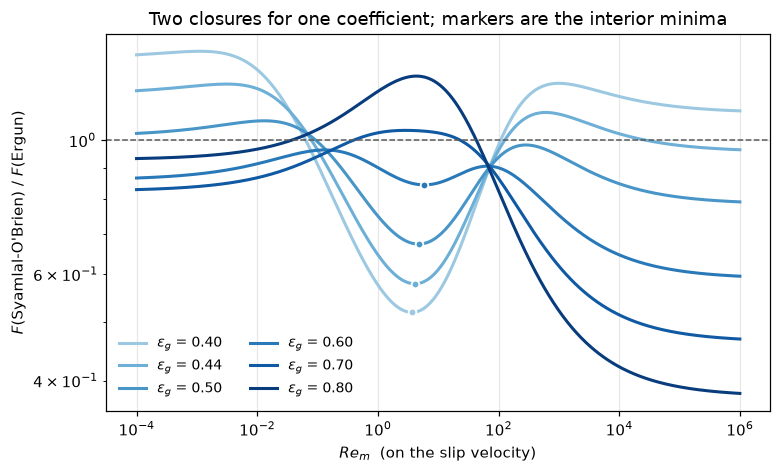

**The headline.** At $\epsilon_g = 0.44$ the two closures agree in the viscous limit to
**19 %** (the ratio is 1.192) and in the inertial limit to **4 %** (0.957), and
disagree by a factor **1.73** in between: the ratio bottoms out at **0.579** at
$Re_m = 4.11$, the root of its analytic derivative, which for a 300 µm particle in air
is a slip velocity of 0.21 m s$^{-1}$, not an exotic corner but the middle of a bubbling
bed. Agreement in both limits is therefore **not** evidence that two closures agree, and
a page that reported only the limits would have said the opposite of the truth.

The table above lists, for six voidages, the stationary points of the ratio. At 4 of
the six it has an interior **minimum** (the derivative changes sign from falling to
rising); that minimum is the lowest value of the ratio at 3 of them, and the voidage
above which it stops being the lowest (the inertial limit is lower from there on) is the
root 0.528 of ratio-of-limits minus minimum. At the voidages without an interior minimum
the derivative has one sign change only, and the ratio falls to its inertial limit.

**And the qualification that belongs beside the headline, not in a footnote.** Ergun plots
against $Re/(1-\epsilon_g)$, and on that abscissa the $\epsilon_g = 0.44$ dip sits at
**7.33**. The **244** markers recovered from his Figure 7 (the ones this page loads,
refits and quotes) span **7.45 to 1820**. So *every one of Ergun's own recovered data
points lies above the point where this page reports a factor 1.73 disagreement*, though
only just: the markers start 1.6 % above it. At $\epsilon_g = 0.50$ the dip moves to
9.49 and is comfortably inside the data. The obvious objection (*of course they disagree, you
have left the range Ergun measured*) is therefore live at 0.44 and answered at 0.50, and the
honest reading is that the disagreement is real where Ergun has data and is an
extrapolation of his correlation, by a whisker, at the worst point. **No validity range for
eq. (12) is available on disk either**: the report gives none and Garside & Al-Dibouni (1977)
is not here.

In [10]:
Re_grid = np.logspace(-4, 6, 400)      # the plotting grid only; every number comes from the roots
shades = colormaps["Blues"](np.linspace(0.38, 0.95, len(EPS_FAM)))  # sequential: voidage IS a magnitude

fig, ax = plt.subplots(figsize=(7.2, 4.4))
for e, c, (_, mn) in zip(EPS_FAM, shades, TAB.iterrows()):
    ax.plot(Re_grid, F_so_star(e, Re_grid) / F_er_star(e, Re_grid), color=c, lw=2,
            label=rf"$\epsilon_g$ = {e:.2f}")
    if np.isfinite(mn["interior minimum"]):
        ax.plot(mn["at Re_m"], mn["interior minimum"], "o", ms=5, color=c, mec="white", mew=1.2)
ax.axhline(1.0, color="0.35", lw=1, ls="--")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("$Re_m$  (on the slip velocity)")
ax.set_ylabel("$F$(Syamlal-O'Brien) / $F$(Ergun)")
ax.set_title("Two closures for one coefficient; markers are the interior minima")
ax.legend(frameon=False, ncol=2, fontsize=9)
plt.tight_layout(); plt.show()

say(r"""**The headline.** At $\epsilon_g = 0.44$ the two closures agree in the viscous limit to
**@@gv@@ %** (the ratio is @@rv@@) and in the inertial limit to **@@gi@@ %** (@@ri@@), and
disagree by a factor **@@fac@@** in between: the ratio bottoms out at **@@rmin@@** at
$Re_m = @@x@@$, the root of its analytic derivative, which for a 300 µm particle in air
is a slip velocity of @@v@@ m s$^{-1}$, not an exotic corner but the middle of a bubbling
bed. Agreement in both limits is therefore **not** evidence that two closures agree, and
a page that reported only the limits would have said the opposite of the truth.

The table above lists, for six voidages, the stationary points of the ratio. At @@n_min@@ of
the six it has an interior **minimum** (the derivative changes sign from falling to
rising); that minimum is the lowest value of the ratio at @@n_low@@ of them, and the voidage
above which it stops being the lowest (the inertial limit is lower from there on) is the
root @@fold@@ of ratio-of-limits minus minimum. At the voidages without an interior minimum
the derivative has one sign change only, and the ratio falls to its inertial limit.

**And the qualification that belongs beside the headline, not in a footnote.** Ergun plots
against $Re/(1-\epsilon_g)$, and on that abscissa the $\epsilon_g = 0.44$ dip sits at
**@@xd@@**. The **@@nm@@** markers recovered from his Figure 7 (the ones this page loads,
refits and quotes) span **@@xlo@@ to @@xhi@@**. So *every one of Ergun's own recovered data
points lies above the point where this page reports a factor @@fac@@ disagreement*, though
only just: the markers start @@gapm@@ % above it. At $\epsilon_g = 0.50$ the dip moves to
@@xd50@@ and is @@inside@@ the data. The obvious objection (*of course they disagree, you
have left the range Ergun measured*) is therefore live at 0.44 and answered at 0.50, and the
honest reading is that the disagreement is real where Ergun has data and is an
extrapolation of his correlation, by a whisker, at the worst point. **No validity range for
eq. (12) is available on disk either**: the report gives none and Garside & Al-Dibouni (1977)
is not here.""",
    gv=f"{DIP['limit_gap_viscous_pct_eps044']:.0f}", rv=f"{DIP['ratio_viscous_limit_eps044']:.3f}",
    gi=f"{DIP['limit_gap_inertial_pct_eps044']:.0f}", ri=f"{DIP['ratio_inertial_limit_eps044']:.3f}",
    fac=f"{DIP['disagreement_factor_eps044']:.2f}", rmin=f"{DIP['worst_ratio_SO_over_Ergun_at_eps044']:.3f}",
    x=f"{DIP['dip_Re_m_eps044']:.2f}", v=f"{DIP['dip_slip_velocity_300um_air']:.2f}",
    n_min=DIP["dip_voidages_with_interior_minimum"], n_low=DIP["dip_voidages_where_minimum_is_lowest"],
    fold=f"{DIP['dip_stops_being_lowest_eps']:.3f}", xd=f"{DIP['dip_abscissa_ergun_eps044']:.2f}",
    nm=claims["ergun_markers_rows"], xlo=f"{DIP['ergun_markers_abscissa_min']:.2f}",
    xhi=f"{DIP['ergun_markers_abscissa_max']:.0f}", gapm=f"{DIP['dip_below_markers_pct_eps044']:.1f}",
    xd50=f"{DIP['dip_abscissa_ergun_eps050']:.2f}",
    inside="comfortably inside" if DIP["dip_inside_markers_eps050"] else "outside")

### 3. The dilute limit: why the report says the Ergun route "must be supplemented"

That sentence is usually paraphrased as "Ergun is not valid in dilute flow",
which is true but not quantitative. It has a closed form. As $\epsilon_s \to 0$
the Ergun viscous term vanishes like $\epsilon_s^2$ while the drag on an isolated
sphere does not vanish at all, so the ratio of the Ergun drag *per particle* to
the isolated-sphere drag tends to $k_2/(\tfrac34 C_{Ds}(Re))$, which goes to
zero in the Stokes regime and to a finite number above it.

In [11]:
RE_DIL = np.array([1e-3, 1e-2, 0.1, 1.0, 10.0, 100.0, 1e3, 1e4, 1e6])
EPS_DILUTE = 1 - 1e-4


def ergun_over_sphere(Re, p=P0):
    """Ergun drag per particle over the isolated-sphere drag as eps_s -> 0 (closed form)."""
    return p["k2"] / (p["pref"] * C_Ds(Re, p))


def dilute_claims(p=P0):
    """Claims of Results 3. The crossover Reynolds number, above which the Ergun form
    overshoots the isolated sphere, is the root of ergun_over_sphere - 1 on 1e-3 to 1e8."""
    closed = ergun_over_sphere(RE_DIL, p)
    full = np.array([F_er_star(EPS_DILUTE, r, p) / F_so_star(EPS_DILUTE, r, p) for r in RE_DIL])
    visc = p["k1"] * (1 - EPS_DILUTE) ** 2 / EPS_DILUTE
    share = 100 * visc / (visc + p["k2"] * (1 - EPS_DILUTE) * RE_DIL)
    i1, i2, i3 = list(RE_DIL).index(1.0), list(RE_DIL).index(1e-2), list(RE_DIL).index(1e-3)
    return {"ergun_isolated_Re1_pct": float(100 * closed[i1]),
            "ergun_isolated_Re0p01_pct": float(100 * closed[i2]),
            "ergun_isolated_Re1e6_ratio": float(closed[-1]),
            "ergun_isolated_crossover_Re": float(one_root(lambda r: ergun_over_sphere(r, p) - 1.0,
                                                          1e-3, 1e8, n=64, log=True, xtol=1e-9)),
            "dilute_viscous_share_Re1em3_pct": float(share[i3]),
            "dilute_full_over_closed_Re1em3": float(full[i3] / closed[i3]),
            "dilute_full_over_closed_Re1": float(full[i1] / closed[i1])}, closed, full, share


DIL, _closed, _full, _share = dilute_claims()
TABLE_DIL = pd.DataFrame({"Re": RE_DIL, "Ergun / isolated sphere": _closed,
                          "full expression, eps_s = 1e-4": _full,
                          "Ergun viscous term, % of its total": _share})
print("How badly the packed-bed route does where it was never measured")
print(TABLE_DIL.round(5).to_string(index=False))
for name, v in DIL.items():
    claims.value(name, v, rtol=1e-6, note="closed form on the printed constants, or a root")
DIL_NAMES = list(DIL)
say(r"""**The two columns are not the same quantity at the dense-viscous corner, and the
third column says why.** The closed form is the $\epsilon_s\to0$ limit, in which
Ergun's viscous term has already vanished like $\epsilon_s^2$; at a finite
$\epsilon_s = 10^{-4}$ it has not, and at $Re = 10^{-3}$ it is still
**@@share@@ %** of Ergun's total, which is
why the second column sits **@@gap3@@×** above the first there. The two converge
as the viscous share dies: @@gap0@@× by $Re = 1$. The prose below quotes the **closed
form**, i.e. the true dilute limit.

At $Re = 1$ the Ergun form gives **@@p1@@ %** of the
drag on an isolated sphere; at $Re = 10^{-2}$ it gives
**@@p2@@ %**, and the shortfall is unbounded as
$Re \to 0$. Above $Re \approx @@rx@@$
it overshoots instead, reaching **@@r6@@×** at high
Reynolds number. **That two-sided failure is the whole reason a blend rule exists**,
and it is the piece of the catalogue's three-way comparison this page cannot supply:
the blend attributed to Gidaspow (1994) is in a monograph that is not on disk. The
Syamlal-O'Brien column needs no blend: by construction $V_{rm}(1) = 1$ and eq. (11)
becomes the isolated-sphere drag exactly, which is Check 1 below.""",
    share=f"{DIL['dilute_viscous_share_Re1em3_pct']:.0f}", gap3=f"{DIL['dilute_full_over_closed_Re1em3']:.1f}",
    gap0=f"{DIL['dilute_full_over_closed_Re1']:.2f}", p1=f"{DIL['ergun_isolated_Re1_pct']:.1f}",
    p2=f"{DIL['ergun_isolated_Re0p01_pct']:.2f}", rx=f"{DIL['ergun_isolated_crossover_Re']:.0f}",
    r6=f"{DIL['ergun_isolated_Re1e6_ratio']:.2f}")
for row, mods in DEFECTS:
    brk_helper(row, lambda p: dilute_claims(p)[0], DIL_NAMES, dict(P0, **mods))

How badly the packed-bed route does where it was never measured
         Re  Ergun / isolated sphere  full expression, eps_s = 1e-4  Ergun viscous term, % of its total
      0.001                  0.00010                        0.00096                            89.55317
      0.010                  0.00099                        0.00183                            46.15633
      0.100                  0.00934                        0.01013                             7.89546
      1.000                  0.07914                        0.07979                             0.84994
     10.000                  0.50577                        0.50602                             0.08565
    100.000                  1.89379                        1.89329                             0.00857
   1000.000                  3.81766                        3.81623                             0.00086
  10000.000                  5.07595                        5.07387                             0.00009


**The two columns are not the same quantity at the dense-viscous corner, and the
third column says why.** The closed form is the $\epsilon_s\to0$ limit, in which
Ergun's viscous term has already vanished like $\epsilon_s^2$; at a finite
$\epsilon_s = 10^{-4}$ it has not, and at $Re = 10^{-3}$ it is still
**90 %** of Ergun's total, which is
why the second column sits **9.6×** above the first there. The two converge
as the viscous share dies: 1.01× by $Re = 1$. The prose below quotes the **closed
form**, i.e. the true dilute limit.

At $Re = 1$ the Ergun form gives **7.9 %** of the
drag on an isolated sphere; at $Re = 10^{-2}$ it gives
**0.10 %**, and the shortfall is unbounded as
$Re \to 0$. Above $Re \approx 29$
it overshoots instead, reaching **5.79×** at high
Reynolds number. **That two-sided failure is the whole reason a blend rule exists**,
and it is the piece of the catalogue's three-way comparison this page cannot supply:
the blend attributed to Gidaspow (1994) is in a monograph that is not on disk. The
Syamlal-O'Brien column needs no blend: by construction $V_{rm}(1) = 1$ and eq. (11)
becomes the isolated-sphere drag exactly, which is Check 1 below.

### 4. The switch at eps_g = 0.85

Eq. (14) is a two-branch definition, so the obvious question is how big the jump
is. It is worth asking precisely because the blend rule this page cannot build,
the one attributed to Gidaspow, is *known for* switching discontinuously, and it
would be easy to assume the same of any branched closure.

In [12]:
def V_rm_given_B(eps_g, Re_m, B, p=P0):
    """Eq. (12) with B supplied, so that both one-sided limits at the switch are exact."""
    A = A_of(eps_g, p)
    return p["half"] * (A - p["lin"] * Re_m
                        + np.sqrt((p["lin"] * Re_m) ** 2 + p["cross"] * Re_m * (2 * B - A) + A * A))


def switch_claims(p=P0, re_max=1e8, hu=HALF_UNIT["B_exponent_dilute"]):
    """Claims of Results 4: the jump in B at the switch in closed form (and in half-units of the
    last printed digit of the dilute exponent, ``hu`` being that half-unit), and the jump in V_rm over
    Re_m from 1e-6 to ``re_max``. V_rm tends to B at large Re_m (closed form), so the jump in V_rm
    rises to the jump in B; the claims record how often it falls on the scan."""
    sw = p["bsw"]
    B_lo, B_hi = p["bco"] * sw ** p["bde"], sw ** p["bdi"]      # the two one-sided limits
    jump_B = 100 * (B_hi / B_lo - 1)
    Re = np.logspace(-6, np.log10(re_max), 57)
    jumps = 100 * (V_rm_given_B(sw, Re, B_hi, p) / V_rm_given_B(sw, Re, B_lo, p) - 1)
    half_unit_effect = 100 * (sw ** (-hu) - 1)       # B above the switch moves this much per half-unit
    return {"B_branch_jump_pct_at_switch": float(jump_B),
            "B_half_unit_effect_pct": float(half_unit_effect),
            "B_jump_in_half_units_of_dilute_exponent": float(abs(jump_B) / half_unit_effect),
            "Vrm_branch_jump_max_pct": float(np.abs(jumps).max()),
            "Vrm_branch_jump_falls_with_Re": int(np.sum(np.diff(np.abs(jumps)) < -1e-6)),
            "Vrm_branch_jump_gap_to_B_jump": float(abs(np.abs(jumps).max() - abs(jump_B)) / abs(jump_B))}, \
        (B_lo, B_hi, Re, jumps)


SWC, (B_LO, B_HI, RE_SW, JUMPS) = switch_claims()
print(f"B just below the switch : {B_LO:.8f}   (= {P0['bco']:g} * {P0['bsw']:g}^{P0['bde']:g})")
print(f"B just above the switch : {B_HI:.8f}   (= {P0['bsw']:g}^{P0['bdi']:g})")
print(f"relative jump in B      : {SWC['B_branch_jump_pct_at_switch']:+.5f} %\n")
print("relative jump in V_rm across the switch, by Reynolds number:")
for r, j in list(zip(RE_SW, JUMPS))[::8]:
    print(f"   Re_m = {r:9.0e}   {j:+.6f} %")
claims.value("B_branch_jump_pct_at_switch", SWC["B_branch_jump_pct_at_switch"], rtol=1e-6,
             note="closed form on the printed constants")
claims.value("B_half_unit_effect_pct", SWC["B_half_unit_effect_pct"], rtol=1e-6,
             note="B above the switch moves this much per half-unit of the dilute exponent")
claims.value("B_jump_in_half_units_of_dilute_exponent", SWC["B_jump_in_half_units_of_dilute_exponent"],
             rtol=1e-6, note="the half-unit is read from the CSV column as a string")
claims.value("Vrm_branch_jump_max_pct", SWC["Vrm_branch_jump_max_pct"], rtol=1e-6,
             note="largest jump of V_rm over Re_m from 1e-6 to 1e8, both one-sided limits exact")
claims.exact("Vrm_branch_jump_falls_with_Re", SWC["Vrm_branch_jump_falls_with_Re"],
             note="number of decreases of |jump| along the Re_m scan")
claims.bound("Vrm_branch_jump_gap_to_B_jump", SWC["Vrm_branch_jump_gap_to_B_jump"], max=1e-3,
             basis="theory", note="V_rm tends to B as Re_m grows, so the largest jump of V_rm is the "
                                  "jump of B up to the first correction of order 1/Re_m")
say(r"""**It is a branch, not a discontinuity.** The two expressions meet at
$\epsilon_g = @@sw@@$ to **@@jb@@ %** in $B$, and the largest jump this
produces in $V_{rm}$ anywhere in Reynolds number (the scan rises with $Re_m$ to the
jump in $B$ and falls at @@nf@@ of its steps) is **@@jv@@ %**. The jump in $B$ is
**@@hu@@** half-units of the last printed digit of the dilute exponent (a half-unit of
that exponent moves $B$ just above the switch by @@hue@@ %), that is, the two branches meet to
within the rounding of the printed exponents, so eq. (14) is a change of functional form
and not a step. **This page therefore makes no claim about
any discontinuous drag closure**: the one the catalogue names switches at
$\epsilon_g = 0.8$, is in a monograph that is not on disk, and the size of its jump
cannot be computed here.""",
    sw=f"{P0['bsw']:g}", jb=f"{SWC['B_branch_jump_pct_at_switch']:+.3f}",
    jv=f"{SWC['Vrm_branch_jump_max_pct']:.3f}", nf=SWC["Vrm_branch_jump_falls_with_Re"],
    hu=f"{SWC['B_jump_in_half_units_of_dilute_exponent']:.2f}",
    hue=f"{SWC['B_half_unit_effect_pct']:.3f}")
SW_NAMES = list(SWC)
for row, mods in DEFECTS:
    brk_helper(row, lambda p: switch_claims(p)[0], SW_NAMES, dict(P0, **mods))
brk_helper("scan to Re_m = 1e14, where the radicand cancels", lambda: switch_claims(re_max=1e14)[0], SW_NAMES)
brk_helper("scan cut at Re_m = 1e2", lambda: switch_claims(re_max=1e2)[0], SW_NAMES)
brk_helper("dilute exponent read with one digit fewer", lambda: switch_claims(hu=0.05)[0], SW_NAMES)

B just below the switch : 0.64974989   (= 0.8 * 0.85^1.28)
B just above the switch : 0.65007004   (= 0.85^2.65)
relative jump in B      : +0.04927 %

relative jump in V_rm across the switch, by Reynolds number:
   Re_m =     1e-06   +0.000000 %
   Re_m =     1e-04   +0.000001 %
   Re_m =     1e-02   +0.000074 %
   Re_m =     1e+00   +0.006114 %
   Re_m =     1e+02   +0.044635 %
   Re_m =     1e+04   +0.049221 %
   Re_m =     1e+06   +0.049273 %
   Re_m =     1e+08   +0.049274 %


**It is a branch, not a discontinuity.** The two expressions meet at
$\epsilon_g = 0.85$ to **+0.049 %** in $B$, and the largest jump this
produces in $V_{rm}$ anywhere in Reynolds number (the scan rises with $Re_m$ to the
jump in $B$ and falls at 0 of its steps) is **0.049 %**. The jump in $B$ is
**0.61** half-units of the last printed digit of the dilute exponent (a half-unit of
that exponent moves $B$ just above the switch by 0.081 %), that is, the two branches meet to
within the rounding of the printed exponents, so eq. (14) is a change of functional form
and not a step. **This page therefore makes no claim about
any discontinuous drag closure**: the one the catalogue names switches at
$\epsilon_g = 0.8$, is in a monograph that is not on disk, and the size of its jump
cannot be computed here.

## Validation

Four checks and a transcription round trip, in the order of
`docs/agent-brief.md`: the two identities first because they are what licenses
the transcription, then the two that can actually fail.

**Read the first two as what they are.** They are algebraic identities of the
printed equations. They cannot fail for a correct transcription, and their value
is entirely in *which mis-readings they do and do not catch*, so each is
published with the break table that measures that, and each says explicitly what
it is blind to. Neither is evidence that the closure describes anything.

### Check 1: V_rm(eps_g = 1) = 1 at every Reynolds number

At $\epsilon_g = 1$ eqs. (13) and (14) both give 1, the radicand of eq. (12)
becomes $(0.06\,Re_m + 1)^2$, and $V_{rm}$ collapses to exactly 1. This is the
property that makes the closure need no blend rule, and it holds only for a
particular reading of the coefficients.

In [13]:
# Re_m up to 1e6 only: above that the perfect square (0.06 Re + 1)^2 loses the +1 to
# double-precision cancellation, which is arithmetic, not physics
RE_ID = np.logspace(-8, 6, 80)
TOL_ID = 1e-9         # the identity's bound: a reading is "seen" when it exceeds it (round-off of the
                      # cancellation reaches 3e-11 when 0.06 and 0.12 are both scaled up, the smallest real catch is 8e-2)


def check1(p=P0, eps_eval=1.0, re_max=1e6):
    """max |V_rm(eps_eval) - 1| over Re_m; eps_eval = 1 is the identity."""
    return float(np.max(np.abs(V_rm(eps_eval, np.logspace(-8, np.log10(re_max), 80), p) - 1.0)))


def V_rm_split_lin(eps_g, Re_m, lin_outer, lin_sq):
    """eq. (12) with the two appearances of 0.06 read differently."""
    A, B = A_of(eps_g), B_of(eps_g)
    return 0.5 * (A - lin_outer * Re_m
                  + np.sqrt((lin_sq * Re_m) ** 2 + 0.12 * Re_m * (2 * B - A) + A * A))


def V_rm_b_prefactor_both(eps_g, Re_m):
    """eq. (14) mis-read as carrying the 0.8 on BOTH branches."""
    A = A_of(eps_g)
    B = np.where(eps_g <= P0["bsw"], P0["bco"] * eps_g ** P0["bde"], P0["bco"] * eps_g ** P0["bdi"])
    return 0.5 * (A - 0.06 * Re_m + np.sqrt((0.06 * Re_m) ** 2 + 0.12 * Re_m * (2 * B - A) + A * A))


def check1_table(eps_eval=1.0, re_max=1e6):
    """The mis-readings of eqs. (12)-(14), each with its residual, and whether it is a
    voidage constant (which is 1^x = 1 at eps_g = 1) or not."""
    f = lambda **mods: check1(dict(P0, **mods), eps_eval, re_max)
    return [("outer 0.5 -> 0.55", f(half=0.55), False),
            ("0.12 -> 0.10 in the cross term", f(cross=0.10), False),
            ("0.06 read as 0.05 in the linear term only",
             float(np.max(np.abs(V_rm_split_lin(eps_eval, RE_ID, 0.05, 0.06) - 1))), False),
            ("the 0.8 prefactor put on the dilute branch too",
             float(np.max(np.abs(V_rm_b_prefactor_both(eps_eval, RE_ID) - 1))), False),
            ("both 0.06 and 0.12 read a decimal place out", f(lin=0.6, cross=1.2), False),
            ("A exponent 4.14 -> 4.65", f(aexp=4.65), True),
            ("dense B exponent 1.28 -> 2.28", f(bde=2.28), True),
            ("dilute B exponent 2.65 -> 2.39", f(bdi=2.39), True),
            ("B prefactor 0.8 -> 0.7", f(bco=0.7), True),
            ("switch voidage 0.85 -> 0.80", f(bsw=0.80), True)]


def check1_claims(eps_eval=1.0, re_max=1e6):
    t = check1_table(eps_eval, re_max)
    vals = np.array([v for _, v, _ in t])
    volt = np.array([vc for _, _, vc in t])
    return {"check1_Vrm_unity_identity": check1(P0, eps_eval, re_max),
            "check1_readings_seen": int(np.sum(vals > TOL_ID)),
            "check1_voidage_constants_seen": int(np.sum(vals[volt] > TOL_ID))}, t


C1, T1 = check1_claims()
claims.bound("check1_Vrm_unity_identity", C1["check1_Vrm_unity_identity"], max=TOL_ID, basis="identity",
             note="the radicand is a perfect square; what is left is double-precision cancellation "
                  "at the top of the Reynolds range")
_v1 = np.array([v for _, v, _ in T1])
_m1 = float(np.min(np.abs(_v1 - TOL_ID) / TOL_ID))
claims.exact("check1_readings_seen", C1["check1_readings_seen"], margin=_m1, min_margin=0.5,
             note="mis-readings of eqs. (12)-(14) whose residual exceeds the identity's bound")
claims.exact("check1_voidage_constants_seen", C1["check1_voidage_constants_seen"], margin=_m1, min_margin=0.5,
             note="of the five voidage constants (three exponents, the 0.8, the switch), those seen")
print(pd.DataFrame([(n, v) for n, v, _ in T1], columns=["reading", "max |V_rm(1) - 1| over Re"])
      .to_string(index=False, float_format=lambda v: f"{v:.3e}"))
say("""**Result: @@r@@ (bound @@tol@@).** The radicand really is a perfect square, so the identity is
exact in exact arithmetic; what is left is the double-precision cancellation of
$(0.06Re+1)$ against $0.06Re$ at the top of the Reynolds range. A reading counts as seen when
its residual exceeds the bound.

**What it catches:** @@seen@@ of the @@n@@ mis-readings above are seen: the outer 0.5, the
pairing of the two 0.06's, the 0.12, and a spurious prefactor on the dilute branch of eq. (14),
the last of which is precisely the mis-reading the mangled text layer invites, since it renders
that branch as `_g-2'6s`.

**What it is blind to, measured:** @@blind@@ of the @@n@@ are not seen, among them **every voidage
exponent** and the 0.8 itself and the switch voidage (@@vseen@@ of those five constants are seen).
All are invisible for the same trivial reason: $1^x = 1$, so eqs. (13) and (14) return 1 at
$\\epsilon_g = 1$ whatever their exponents are. A decimal-place slip that scales 0.06 and 0.12
*together* is blind too, because the perfect square survives any common scaling of the pair
(its residual is the same cancellation at a larger scale, below the bound).
**The exponents are settled by Check 3 and by the page image, not by this.**""",
    r=f"{C1['check1_Vrm_unity_identity']:.1e}", tol=f"{TOL_ID:.0e}", seen=C1["check1_readings_seen"],
    n=len(T1), blind=len(T1) - C1["check1_readings_seen"], vseen=C1["check1_voidage_constants_seen"])
for row, v, _ in T1:
    brk(row, "check1_Vrm_unity_identity", v)
brk_helper("identity evaluated at eps_g = 0.9999", lambda: check1_claims(eps_eval=0.9999)[0],
           list(C1))
brk_helper("Reynolds range extended to 1e10", lambda: check1_claims(re_max=1e10)[0], list(C1))

                                       reading  max |V_rm(1) - 1| over Re
                             outer 0.5 -> 0.55                  1.000e-01
                0.12 -> 0.10 in the cross term                  8.333e-02
     0.06 read as 0.05 in the linear term only                  5.000e+03
the 0.8 prefactor put on the dilute branch too                  2.000e-01
   both 0.06 and 0.12 read a decimal place out                  2.910e-11
                       A exponent 4.14 -> 4.65                  2.220e-16
                 dense B exponent 1.28 -> 2.28                  2.220e-16
                dilute B exponent 2.65 -> 2.39                  2.220e-16
                        B prefactor 0.8 -> 0.7                  2.220e-16
                   switch voidage 0.85 -> 0.80                  2.220e-16


**Result: 2.2e-16 (bound 1e-09).** The radicand really is a perfect square, so the identity is
exact in exact arithmetic; what is left is the double-precision cancellation of
$(0.06Re+1)$ against $0.06Re$ at the top of the Reynolds range. A reading counts as seen when
its residual exceeds the bound.

**What it catches:** 4 of the 10 mis-readings above are seen: the outer 0.5, the
pairing of the two 0.06's, the 0.12, and a spurious prefactor on the dilute branch of eq. (14),
the last of which is precisely the mis-reading the mangled text layer invites, since it renders
that branch as `_g-2'6s`.

**What it is blind to, measured:** 6 of the 10 are not seen, among them **every voidage
exponent** and the 0.8 itself and the switch voidage (0 of those five constants are seen).
All are invisible for the same trivial reason: $1^x = 1$, so eqs. (13) and (14) return 1 at
$\epsilon_g = 1$ whatever their exponents are. A decimal-place slip that scales 0.06 and 0.12
*together* is blind too, because the perfect square survives any common scaling of the pair
(its residual is the same cancellation at a larger scale, below the bound).
**The exponents are settled by Check 3 and by the page image, not by this.**

### Check 2: the force balance returns v_slip = V_rm v_t

This is the design property of eq. (11) and the reason $V_{rm}$ is called a
terminal-velocity ratio, but the report does not state it. Substituting eq. (11)
into the balance $F_{gm}v_{\text{slip}} = \epsilon_s\epsilon_g(\rho_s-\rho_g)g$
derived in the Background, the $\epsilon_s\epsilon_g$ cancels, $V_{rm}^2$ absorbs
$v_{\text{slip}}^2$, and what remains is the single-sphere terminal-velocity
equation in $v_{\text{slip}}/V_{rm}$.

**It is an algebraic identity of eq. (11), it does not test any constant inside
eq. (12) or eq. (16), and it is here because the $V_{rm}^2$ and the
$Re_m/V_{rm}$ argument are the two things in that equation most likely to be
mis-transcribed.**

In [14]:
def check2(F=F_syamlal_obrien, p=P0, p_target=None):
    """Worst relative gap between the slip velocity that the force balance gives (a root of
    F(eps, v) v = eps_s eps_g drho g on 1e-16 to 1e6 m/s, increasing in v) and V_rm v_t.
    ``p_target`` builds the right-hand side from another dictionary than the force."""
    pt = p if p_target is None else p_target
    worst = 0.0
    for d_p, rho_s, e in CASES:
        drho = rho_s - AIR_SI["rho"]
        vt = v_terminal(d_p, drho, AIR_SI["rho"], AIR_SI["mu"], AIR_SI["g"], pt)
        v_bal = one_root(lambda v: F(e, v, d_p, AIR_SI["rho"], AIR_SI["mu"], p) * v
                         - (1 - e) * e * drho * AIR_SI["g"], 1e-16, 1e6, n=80, log=True, xtol=1e-18)
        target = V_rm_at_balance(e, d_p * vt * AIR_SI["rho"] / AIR_SI["mu"], pt) * vt
        worst = max(worst, abs(v_bal - target) / target)
    return float(worst)


def _mk(power=2, cd_arg="ratio", pref=None, drop_eps_g=False):
    """Eq. (11) with one structural mis-reading."""
    def F(eps_g, v, d_p, rho, mu, p=P0):
        pf = p["pref"] if pref is None else pref
        Re = d_p * v * rho / mu
        Vr = V_rm(eps_g, Re, p)
        arg = Re / Vr if cd_arg == "ratio" else Re
        eg = 1.0 if drop_eps_g else eps_g
        return pf * (1 - eps_g) * eg * rho / (Vr ** power * d_p) * C_Ds(arg, p) * v
    return F


STRUCT2 = [("V_rm^2 -> V_rm in eq. (11)", dict(power=1)), ("V_rm^2 -> V_rm^3", dict(power=3)),
           ("C_Ds argument Re_m/V_rm -> Re_m", dict(cd_arg="plain")), ("3/4 -> 1", dict(pref=1.0)),
           ("eps_g dropped from eq. (11)", dict(drop_eps_g=True))]
CONST2 = [("A exponent 4.14 -> 4.65", dict(aexp=4.65)), ("C_D slope 4.8 -> 4.0", dict(cd1=4.0)),
          ("C_D offset 0.63 -> 0.44", dict(cd0=0.44)), ("outer 0.5 -> 0.55", dict(half=0.55))]
TOL_FB = 1e-9


def check2_claims(fixed_target=False, struct=STRUCT2, tol=TOL_FB):
    """The identity's residual; the residuals of five structural mis-readings of eq. (11) and four
    mis-read constants of eqs. (12) and (16). ``fixed_target`` builds the right-hand side from the
    printed constants while the force carries the mis-read constant (the identity then compares two
    different readings)."""
    s = [check2(_mk(**kw)) for _, kw in struct]
    c = [check2(p=dict(P0, **m), p_target=P0 if fixed_target else None) for _, m in CONST2]
    return {"check2_force_balance_identity": check2(),
            "check2_structural_readings_seen": int(np.sum(np.array(s) > tol)),
            "check2_smallest_structural_residual": float(min(s)),
            "check2_largest_structural_residual": float(max(s)),
            "check2_constant_readings_seen": int(np.sum(np.array(c) > tol))}, s, c


C2, S2, K2 = check2_claims()
claims.bound("check2_force_balance_identity", C2["check2_force_balance_identity"], max=TOL_FB,
             basis="tolerance",
             note="the identity is exact; what is left is the tolerance of the two root finds")
_m2 = float(np.min(np.abs(np.array(S2 + K2) - TOL_FB) / TOL_FB))
claims.exact("check2_structural_readings_seen", C2["check2_structural_readings_seen"], margin=_m2,
             min_margin=0.5, note="of five mis-readings of eq. (11), those whose residual exceeds the bound")
claims.exact("check2_constant_readings_seen", C2["check2_constant_readings_seen"], margin=_m2,
             min_margin=0.5, note="of four mis-read constants of eqs. (12) and (16), those seen")
claims.value("check2_smallest_structural_residual", C2["check2_smallest_structural_residual"], rtol=1e-3,
             note="relative gap of the slip velocity, smallest of the five structural mis-readings")
claims.value("check2_largest_structural_residual", C2["check2_largest_structural_residual"], rtol=1e-3,
             note="relative gap of the slip velocity, largest of the five structural mis-readings")
print(pd.DataFrame([("as printed", C2["check2_force_balance_identity"])]
                   + [(n, v) for (n, _), v in zip(STRUCT2 + CONST2, S2 + K2)],
                   columns=["reading", "worst relative residual"])
      .to_string(index=False, float_format=lambda v: f"{v:.3e}"))
say("""**Result: @@r@@ over four decades of particle size and three voidages (bound @@tol@@).**

**What it catches, measured:** @@ns@@ of the @@nst@@ structural mis-readings of eq. (11) (the exponent
on $V_{rm}$ read as 1 or as 3, the argument of $C_{Ds}$, the 3/4 and the $\\epsilon_g$) are seen,
their residuals running from **@@lo@@** to **@@hi@@** (relative gap of the slip velocity).

**What it is blind to, measured:** @@nc@@ of the @@nct@@ mis-read constants inside eq. (12) and
eq. (16) are seen. They cancel because the identity uses the *same* $C_{Ds}$ on both sides and
the *same* $V_{rm}$ on both sides. **A page that presented this residual as evidence that the
drag law is right would be claiming something it cannot see.**""",
    r=f"{C2['check2_force_balance_identity']:.1e}", tol=f"{TOL_FB:.0e}", ns=C2["check2_structural_readings_seen"],
    nst=len(STRUCT2), lo=f"{C2['check2_smallest_structural_residual']:.2f}",
    hi=f"{C2['check2_largest_structural_residual']:.1f}", nc=C2["check2_constant_readings_seen"],
    nct=len(CONST2))
for (row, _), v in zip(STRUCT2, S2):
    brk(row, "check2_force_balance_identity", v)
for (row, _), v in zip(CONST2, K2):
    brk(row + " (right-hand side from the printed constants)", "check2_force_balance_identity",
        check2(p=dict(P0, **dict(CONST2)[row]), p_target=P0))
brk_helper("constants read differently on the two sides", lambda: check2_claims(fixed_target=True)[0], list(C2))
brk_helper("bound on the identity read as 1e3", lambda: check2_claims(tol=1e3)[0], list(C2))
for row, repl in [("exponent of V_rm in eq. (11) read as 1.5 where the table has 1", (0, dict(power=1.5))),
                  ("3/4 in eq. (11) read as 0.9 where the table has 1 in its place", (3, dict(pref=0.9)))]:
    st = list(STRUCT2)
    st[repl[0]] = (row, repl[1])
    brk_helper(row, lambda s=st: check2_claims(struct=s)[0], list(C2))

                        reading  worst relative residual
                     as printed                1.133e-15
     V_rm^2 -> V_rm in eq. (11)                2.309e+01
               V_rm^2 -> V_rm^3                9.797e-01
C_Ds argument Re_m/V_rm -> Re_m                9.792e-01
                       3/4 -> 1                2.752e-01
    eps_g dropped from eq. (11)                6.323e-01
        A exponent 4.14 -> 4.65                3.298e-16
           C_D slope 4.8 -> 4.0                2.460e-16
        C_D offset 0.63 -> 0.44                5.033e-16
              outer 0.5 -> 0.55                1.717e-16


**Result: 1.1e-15 over four decades of particle size and three voidages (bound 1e-09).**

**What it catches, measured:** 5 of the 5 structural mis-readings of eq. (11) (the exponent
on $V_{rm}$ read as 1 or as 3, the argument of $C_{Ds}$, the 3/4 and the $\epsilon_g$) are seen,
their residuals running from **0.28** to **23.1** (relative gap of the slip velocity).

**What it is blind to, measured:** 0 of the 4 mis-read constants inside eq. (12) and
eq. (16) are seen. They cancel because the identity uses the *same* $C_{Ds}$ on both sides and
the *same* $V_{rm}$ on both sides. **A page that presented this residual as evidence that the
drag law is right would be claiming something it cannot see.**

### Check 3: against the velocity-voidage index the closed form replaces

This one can fail, and the report itself sets it up: eq. (12) is adopted
*because* Richardson and Zaki's correlation "can be calculated only numerically".
So the question with a number attached is **what the substitution costs**.

Using the bridge derived in *The published model*, the index implied by
Syamlal-O'Brien is $n_{\text{implied}} = \ln(\epsilon_g V_{rm})/\ln\epsilon_g$,
evaluated at the single-particle Reynolds number Table VI is indexed by. Two
honest complications are handled rather than hidden. First, eq. (12) is **not** a
power law, so its implied index depends on voidage: the table below reports it
at several, and the spread *is* part of the answer. Second, the two correlations
were fitted to overlapping literature, so this is not two independent witnesses;
it is the cost of one closed form standing in for another. A mean bias is
reported with its standard error over the 18 rows (the standard deviation of the
row deviations over the square root of their number); the rows run over a
range of Reynolds numbers, so the standard error is a statement about this table
and not about a population of beds.

Richardson & Zaki's index, and the index eq. (12) implies
    Re  n_0 (tabulated)  n at eps=0.45  n at eps=0.50  n at eps=0.60  n at eps=0.70  n at eps=0.85  n at eps=0.95
  0.39             4.52          4.958          4.990          5.033          5.063          5.102          5.105
  0.49             4.45          4.916          4.954          5.008          5.044          5.092          5.096
  0.76             4.42          4.813          4.865          4.941          4.995          5.067          5.073
  1.23             4.33          4.657          4.728          4.836          4.914          5.025          5.034
  2.02             4.17          4.446          4.536          4.680          4.793          4.961          4.973
  2.35             4.14          4.372          4.467          4.623          4.747          4.936          4.950
  2.75             4.02          4.291          4.391          4.557          4.694          4.906          4.922
  6.53             3.76       

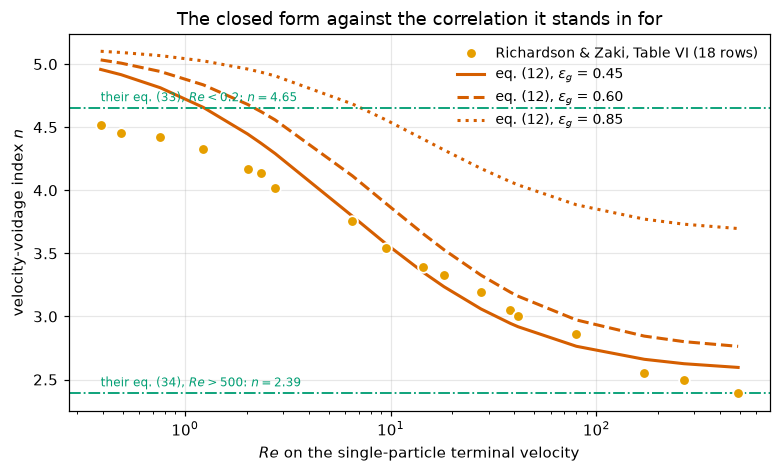

**Result, stated the way the numbers actually fall.** The mean bias over the 18 rows is
**+3.2 %** (standard error 1.2 %) at $\epsilon_g = 0.45$, **+5.4 %** (1.1 %) at 0.50 and
**+29.2 %** (2.9 %) at 0.95, so the means sit 2.6, 4.9 and 9.9 standard errors from zero, and the bias
**grows monotonically with voidage** (it falls over 0 of the five steps between
the tabulated voidages), which it must, because eq. (12) is not a power law and
Richardson and Zaki's relation is. That drift is the structural cost of the substitution and the
report does not mention it.

But the sign is **not** uniform at the dense end, and saying otherwise would misdescribe the
table. At $\epsilon_g = 0.45$ the implied index is above the tabulated one on 12 of the
18 rows and below it on 6, running from -4.1 % to +10.5 % (a
15-point spread), i.e. a **shape** mismatch as much as an offset. Row by row the sign
becomes uniform at the voidage above which the implied index exceeds every tabulated one, found
as the largest per-row crossing: **0.527**, so all 18 rows are above at
$\epsilon_g = 0.95$ (18 of 18).

In the viscous limit the arithmetic is a one-liner: eq. (13) gives
$\epsilon_gV_{rm} \to \epsilon_g^{4.14+1}$, so eq. (12) implies $n = 5.14$ where their eq. (33)
gives 4.65 at $d/D = 0$, i.e. **+10.5 %**, with no fitting and no window choice anywhere
in it. **Read the next cell before using that number**: the report's own prose and its own
eq. (11) put it one factor of $\epsilon_g$ apart, and the other reading reverses its sign.

In [15]:
EPS_PROBE3 = [0.45, 0.50, 0.60, 0.70, 0.85, 0.95]


def implied_index(eps_g, Re_t, p=P0):
    """n = ln(eps V_rm) / ln eps at the force balance: the slip reading, which eq. (11) forces."""
    return np.log(eps_g * V_rm_at_balance(eps_g, Re_t, p)) / np.log(eps_g)


def alt_index(eps_g, Re_t, p=P0):
    """The index under the SUPERFICIAL reading, n = ln(V_rm) / ln eps, no eps_g in the bridge."""
    return np.log(V_rm_at_balance(eps_g, Re_t, p)) / np.log(eps_g)


def index_deviations(eps_g, p=P0, tab=rz, reading="slip"):
    """(n - n_0) / n_0 in per cent over the rows of Table VI."""
    f = implied_index if reading == "slip" else alt_index
    n = np.array([f(eps_g, r, p) for r in tab.Re])
    return 100 * (n - tab.n_0.to_numpy()) / tab.n_0.to_numpy()


def rows_all_above_from(p=P0, tab=rz):
    """The voidage above which every row of Table VI lies below the implied index: for each row the
    root of n_implied - n_0 on 0.2 to 0.99 (at most one), and the largest of them. Raises if a row is
    still below at 0.99."""
    flips = []
    for r, n0 in zip(tab.Re, tab.n_0):
        f = lambda e: implied_index(e, r, p) - n0
        if f(0.99) <= 0:
            raise ValueError(f"the implied index is below n_0 = {n0} at eps_g = 0.99")
        roots = find_roots(f, 0.2, 0.99, n_scan=24, xtol=1e-10)["roots"]
        if len(roots) > 1:
            raise ValueError(f"{len(roots)} crossings of n_0 = {n0}")
        flips.append(roots[0] if roots else 0.2)
    return float(max(flips))


def check3_claims(p=P0, tab=rz):
    """The claims of Check 3: biases with standard errors under both readings of V_rm, the
    viscous-limit index, the rows above, and where the sign becomes uniform."""
    n = len(tab)
    dev = {e: index_deviations(e, p, tab) for e in EPS_PROBE3}
    alt = {e: index_deviations(e, p, tab, "alt") for e in (0.45, 0.50, 0.85, 0.95)}
    bias = {e: float(d.mean()) for e, d in dev.items()}
    out = {}
    for e in (0.45, 0.50, 0.95):
        k = f"{round(100 * e):03d}"
        out[f"check3_index_bias_pct_eps{k}"] = bias[e]
        out[f"check3_index_bias_se_pct_eps{k}"] = float(dev[e].std(ddof=1) / np.sqrt(n))
        out[f"check3_bias_over_se_eps{k}"] = out[f"check3_index_bias_pct_eps{k}"] / out[f"check3_index_bias_se_pct_eps{k}"]
        out[f"check3_alt_reading_bias_pct_eps{k}"] = float(alt[e].mean())
    out["check3_alt_reading_bias_pct_eps085"] = float(alt[0.85].mean())
    out["check3_viscous_index_vs_RZ_pct"] = 100 * ((p["aexp"] + 1) / RZ_N_VISCOUS - 1)
    out["check3_alt_reading_viscous_index_vs_RZ_pct"] = 100 * (p["aexp"] / RZ_N_VISCOUS - 1)
    out["check3_row_spread_pts_eps045"] = float(dev[0.45].max() - dev[0.45].min())
    out["check3_rows_above_eps045"] = int((dev[0.45] > 0).sum())
    out["check3_rows_above_eps095"] = int((dev[0.95] > 0).sum())
    b = [bias[e] for e in EPS_PROBE3]
    out["check3_bias_falls_between_voidages"] = int(np.sum(np.diff(b) < 0))
    out["check3_all_rows_above_from_eps"] = rows_all_above_from(p, tab)
    out["check3_readings_one_unit_apart"] = float(max(
        abs(implied_index(e, r, p) - alt_index(e, r, p) - 1.0) for e in (0.45, 0.95) for r in tab.Re))
    out["_dev"], out["_bias"] = dev, bias
    return out


C3 = check3_claims()
for name, v in C3.items():
    if name.startswith("_") or name in ("check3_rows_above_eps045", "check3_rows_above_eps095",
                                        "check3_bias_falls_between_voidages",
                                        "check3_readings_one_unit_apart"):
        continue
    claims.value(name, v, rtol=1e-6, note="mean of the 18 row deviations, or a closed-form index")
_m3 = float(min(np.abs(C3["_dev"][0.45]).min(), np.abs(C3["_dev"][0.95]).min()))
claims.exact("check3_rows_above_eps045", C3["check3_rows_above_eps045"], margin=_m3, min_margin=0.05,
             note="rows of Table VI below the implied index; margin: smallest |deviation| in points")
claims.exact("check3_rows_above_eps095", C3["check3_rows_above_eps095"], margin=_m3, min_margin=0.05,
             note="rows of Table VI below the implied index; margin: smallest |deviation| in points")
claims.exact("check3_bias_falls_between_voidages", C3["check3_bias_falls_between_voidages"],
             note="decreases of the mean bias along the six voidages (it grows with voidage)")
claims.bound("check3_readings_one_unit_apart", C3["check3_readings_one_unit_apart"], max=1e-12,
             basis="identity", note="the slip and superficial indices differ by exactly one: "
                                    "ln(eps V)/ln eps - ln V/ln eps = 1")

TAB3 = pd.DataFrame({"Re": rz.Re.to_numpy(), "n_0 (tabulated)": rz.n_0.to_numpy()})
for e in EPS_PROBE3:
    TAB3[f"n at eps={e:.2f}"] = [implied_index(e, r) for r in rz.Re]
print("Richardson & Zaki's index, and the index eq. (12) implies")
print(TAB3.round(3).to_string(index=False))
SUM3 = pd.DataFrame({"eps_g": EPS_PROBE3})
SUM3["bias %"] = [C3["_bias"][e] for e in EPS_PROBE3]
SUM3["SE %"] = [C3["_dev"][e].std(ddof=1) / np.sqrt(len(rz)) for e in EPS_PROBE3]
SUM3["MAD %"] = [np.abs(C3["_dev"][e]).mean() for e in EPS_PROBE3]
SUM3["rows above tabulated"] = [int((C3["_dev"][e] > 0).sum()) for e in EPS_PROBE3]
print("\n" + SUM3.round(2).to_string(index=False) + f"\n(rows: {len(rz)}; SE = sd / sqrt(rows))")

fig, ax = plt.subplots(figsize=(7.2, 4.4))
ax.plot(rz.Re, rz.n_0, "o", ms=7, color=COL["meas"], mec="white", mew=1.2,
        label=f"Richardson & Zaki, Table VI ({len(rz)} rows)", zorder=5)
for e, ls in zip([0.45, 0.60, 0.85], ["-", "--", ":"]):
    ax.plot(rz.Re, [implied_index(e, r) for r in rz.Re], ls, lw=2, color=COL["so"],
            label=rf"eq. (12), $\epsilon_g$ = {e:.2f}")
ax.axhline(RZ_N_VISCOUS, color=COL["rz"], lw=1.2, ls="-.")
ax.text(rz.Re.min(), RZ_N_VISCOUS + 0.05, rf"their eq. (33), $Re<0.2$: $n={RZ_N_VISCOUS:g}$", fontsize=8,
        color=COL["rz"])
ax.axhline(RZ_N_INERTIAL, color=COL["rz"], lw=1.2, ls="-.")
ax.text(rz.Re.min(), RZ_N_INERTIAL + 0.05, rf"their eq. (34), $Re>500$: $n={RZ_N_INERTIAL:g}$", fontsize=8,
        color=COL["rz"])
ax.set_xscale("log"); ax.set_xlabel("$Re$ on the single-particle terminal velocity")
ax.set_ylabel("velocity-voidage index $n$")
ax.set_title("The closed form against the correlation it stands in for")
ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

d45 = C3["_dev"][0.45]
say("""**Result, stated the way the numbers actually fall.** The mean bias over the @@n@@ rows is
**@@b45@@ %** (standard error @@s45@@ %) at $\\epsilon_g = 0.45$, **@@b50@@ %** (@@s50@@ %) at 0.50 and
**@@b95@@ %** (@@s95@@ %) at 0.95, so the means sit @@z45@@, @@z50@@ and @@z95@@ standard errors from zero, and the bias
**grows monotonically with voidage** (it falls over @@nfall@@ of the five steps between
the tabulated voidages), which it must, because eq. (12) is not a power law and
Richardson and Zaki's relation is. That drift is the structural cost of the substitution and the
report does not mention it.

But the sign is **not** uniform at the dense end, and saying otherwise would misdescribe the
table. At $\\epsilon_g = 0.45$ the implied index is above the tabulated one on @@a45@@ of the
@@n@@ rows and below it on @@b45n@@, running from @@dmin@@ % to @@dmax@@ % (a
@@spread@@-point spread), i.e. a **shape** mismatch as much as an offset. Row by row the sign
becomes uniform at the voidage above which the implied index exceeds every tabulated one, found
as the largest per-row crossing: **@@from@@**, so all @@n@@ rows are above at
$\\epsilon_g = 0.95$ (@@a95@@ of @@n@@).

In the viscous limit the arithmetic is a one-liner: eq. (13) gives
$\\epsilon_gV_{rm} \\to \\epsilon_g^{@@aexp@@+1}$, so eq. (12) implies $n = @@nvis@@$ where their eq. (33)
gives @@rzn@@ at $d/D = 0$, i.e. **@@vis@@ %**, with no fitting and no window choice anywhere
in it. **Read the next cell before using that number**: the report's own prose and its own
eq. (11) put it one factor of $\\epsilon_g$ apart, and the other reading reverses its sign.""",
    n=len(rz), b45=f"{C3['check3_index_bias_pct_eps045']:+.1f}", s45=f"{C3['check3_index_bias_se_pct_eps045']:.1f}",
    b50=f"{C3['check3_index_bias_pct_eps050']:+.1f}", s50=f"{C3['check3_index_bias_se_pct_eps050']:.1f}",
    b95=f"{C3['check3_index_bias_pct_eps095']:+.1f}", s95=f"{C3['check3_index_bias_se_pct_eps095']:.1f}",
    z45=f"{C3['check3_bias_over_se_eps045']:.1f}", z50=f"{C3['check3_bias_over_se_eps050']:.1f}",
    z95=f"{C3['check3_bias_over_se_eps095']:.1f}", nfall=C3["check3_bias_falls_between_voidages"], a45=C3["check3_rows_above_eps045"],
    b45n=len(rz) - C3["check3_rows_above_eps045"], dmin=f"{d45.min():+.1f}", dmax=f"{d45.max():+.1f}",
    spread=f"{C3['check3_row_spread_pts_eps045']:.0f}", **{"from": f"{C3['check3_all_rows_above_from_eps']:.3f}"},
    a95=C3["check3_rows_above_eps095"], aexp=f"{P0['aexp']:g}", nvis=f"{P0['aexp'] + 1:g}",
    rzn=f"{RZ_N_VISCOUS:g}", vis=f"{C3['check3_viscous_index_vs_RZ_pct']:+.1f}")

#### The one identification this rests on, and the reading that reverses its sign

Every number in Check 3 depends on a single question, **what is $V_{rm}$ a ratio
of?**, and the report answers it twice, inconsistently.

- **Eq. (11) answers it unambiguously.** Substituting it into the force balance
  gives $v_{\text{slip}} = V_{rm}v_t$ and nothing else; Check 2 measures that to
  machine precision. So *as implemented*, $V_{rm}$ is a **slip**-velocity ratio,
  Richardson and Zaki's superficial $V_c = \epsilon_g v_{\text{slip}}$, and the
  bridge carries the factor $\epsilon_g$: $n = \ln(\epsilon_g V_{rm})/\ln\epsilon_g$.
- **The report's prose answers it the other way.** It says $V_{rm}$ "can be
  calculated from the Richardson and Zaki (1954) correlation only numerically",
  and *their* correlation is $V_c/V_i = \epsilon^n$ in the **superficial**
  velocity, which their own Summary states explicitly and this page's sidecar
  records in capitals. Read that way $V_{rm}$ *is* $\epsilon^n$, with no
  $\epsilon_g$ in the bridge and $n = \ln V_{rm}/\ln\epsilon_g$.

The two differ by exactly one unit of index, which is the error the *Published
model* section already names as "the same size as the whole effect being
measured". Nothing on disk settles it: Garside and Al-Dibouni (1977), whose
$V_r$ it actually is, is not here, and the report never writes down what its own
$V_{rm}$ is a ratio of. **So both are printed, and the page says which one it
adopts and why.**

In [16]:
both = pd.DataFrame({"eps_g": EPS_PROBE3})
both["bias %, slip reading"] = [C3["_bias"][e] for e in EPS_PROBE3]
both["bias %, superficial reading"] = [index_deviations(e, reading="alt").mean() for e in EPS_PROBE3]
print("Bias against Table VI's rows, under both readings of V_rm")
print(both.round(2).to_string(index=False))
brk("alternative bridge with a wrong power of eps_g (eps^2 V)", "check3_readings_one_unit_apart",
    max(abs(np.log(e ** 2 * V_rm_at_balance(e, r)) / np.log(e) - alt_index(e, r) - 1.0)
        for e in (0.45, 0.95) for r in rz.Re))
say("""**The two readings differ by exactly one unit of index** (verified to @@unit@@ over the table,
the bound `check3_readings_one_unit_apart`), so they are a rigid offset of
$\\overline{1/n_0}$ in per cent, and every *sensitivity* measured in the break table below is
identical under both. What is not identical is **the sign of the answer**:

| | slip reading (adopted) | superficial reading |
|---|---|---|
| bias vs Table VI at $\\epsilon_g = 0.45$ | **@@b45@@ %** | @@a45@@ % |
| at $\\epsilon_g = 0.50$ | **@@b50@@ %** | @@a50@@ % |
| at $\\epsilon_g = 0.95$ | **@@b95@@ %** | @@a95@@ % |
| viscous limit vs their tabulated @@rzn@@ | **@@nv@@, @@vp@@ %** | @@na@@, @@va@@ % |

**Which this page adopts, and why.** The slip reading, because it is the one
**eq. (11) implements**: it is forced by the equation MFIX actually evaluates, and
Check 2 proves it rather than assuming it. Everything Check 3 reports is therefore *the
index this closure imposes on a simulation*, which is the quantity a modeller needs.

**What the page does not claim.** That this is the index Garside and Al-Dibouni
*fitted*. The evidence there points the other way and is worth stating against the
page's own result: under the superficial reading the closed form lands within
**@@a95abs@@ %** of Table VI at $\\epsilon_g = 0.95$ and within **@@a85abs@@ %** at 0.85,
near-exact agreement in exactly the dilute regime where a hindered-settling
correlation is best founded and where they would have fitted. That is suggestive, not
conclusive, and it cannot be settled without their 1977 paper.

**So the honest statement is conditional, and the conclusion depends on the reading.**
If eq. (11) means what it says, the substitution costs a systematically *larger* index,
growing with voidage. If instead Garside and Al-Dibouni's $V_r$ is the superficial ratio,
then their correlation reproduces Table VI well and **MFIX's eq. (11) is the thing that
carries the spare factor of $\\epsilon_g$**: a claim about the code, not about the
correlation, and one this page has no document to support. Both columns above are
CI-tracked so that neither can drift.""",
    unit=f"{C3['check3_readings_one_unit_apart']:.0e}", b45=f"{C3['check3_index_bias_pct_eps045']:+.2f}",
    a45=f"{C3['check3_alt_reading_bias_pct_eps045']:+.2f}", b50=f"{C3['check3_index_bias_pct_eps050']:+.2f}",
    a50=f"{C3['check3_alt_reading_bias_pct_eps050']:+.2f}", b95=f"{C3['check3_index_bias_pct_eps095']:+.2f}",
    a95=f"{C3['check3_alt_reading_bias_pct_eps095']:+.2f}", rzn=f"{RZ_N_VISCOUS:g}",
    nv=f"{P0['aexp'] + 1:g}", vp=f"{C3['check3_viscous_index_vs_RZ_pct']:+.1f}", na=f"{P0['aexp']:g}",
    va=f"{C3['check3_alt_reading_viscous_index_vs_RZ_pct']:+.1f}",
    a95abs=f"{abs(C3['check3_alt_reading_bias_pct_eps095']):.2f}",
    a85abs=f"{abs(C3['check3_alt_reading_bias_pct_eps085']):.2f}")

Bias against Table VI's rows, under both readings of V_rm
 eps_g  bias %, slip reading  bias %, superficial reading
  0.45                  3.21                       -26.30
  0.50                  5.35                       -24.16
  0.60                  9.74                       -19.77
  0.70                 14.85                       -14.66
  0.85                 28.77                        -0.74
  0.95                 29.20                        -0.31


**The two readings differ by exactly one unit of index** (verified to 1e-15 over the table,
the bound `check3_readings_one_unit_apart`), so they are a rigid offset of
$\overline{1/n_0}$ in per cent, and every *sensitivity* measured in the break table below is
identical under both. What is not identical is **the sign of the answer**:

| | slip reading (adopted) | superficial reading |
|---|---|---|
| bias vs Table VI at $\epsilon_g = 0.45$ | **+3.21 %** | -26.30 % |
| at $\epsilon_g = 0.50$ | **+5.35 %** | -24.16 % |
| at $\epsilon_g = 0.95$ | **+29.20 %** | -0.31 % |
| viscous limit vs their tabulated 4.65 | **5.14, +10.5 %** | 4.14, -11.0 % |

**Which this page adopts, and why.** The slip reading, because it is the one
**eq. (11) implements**: it is forced by the equation MFIX actually evaluates, and
Check 2 proves it rather than assuming it. Everything Check 3 reports is therefore *the
index this closure imposes on a simulation*, which is the quantity a modeller needs.

**What the page does not claim.** That this is the index Garside and Al-Dibouni
*fitted*. The evidence there points the other way and is worth stating against the
page's own result: under the superficial reading the closed form lands within
**0.31 %** of Table VI at $\epsilon_g = 0.95$ and within **0.74 %** at 0.85,
near-exact agreement in exactly the dilute regime where a hindered-settling
correlation is best founded and where they would have fitted. That is suggestive, not
conclusive, and it cannot be settled without their 1977 paper.

**So the honest statement is conditional, and the conclusion depends on the reading.**
If eq. (11) means what it says, the substitution costs a systematically *larger* index,
growing with voidage. If instead Garside and Al-Dibouni's $V_r$ is the superficial ratio,
then their correlation reproduces Table VI well and **MFIX's eq. (11) is the thing that
carries the spare factor of $\epsilon_g$**: a claim about the code, not about the
correlation, and one this page has no document to support. Both columns above are
CI-tracked so that neither can drift.

#### The break table

**eq. (14) is branched, so the voidage at which a check is evaluated decides which of
its constants are even live.** At $\epsilon_g = 0.50$ the dilute branch is never reached, so
the exponent 2.65 and the switch 0.85 could be set to anything at all and the table at that
voidage would not twitch. Nor would any other check move: Check 1 sits at $\epsilon_g = 1$,
where $1^x = 1$; Check 2 is an algebraic identity of eq. (11) that never reads eq. (14); and
Check 4's Geldart voidages lie on the dense branch. A table at one voidage therefore cannot
exercise every constant, and the table below is swept over the evaluation voidage instead. The
column headings are the evaluation voidage; the entries are the *change* in the mean bias, in
points, against the as-printed row, each the difference of two evaluations that differ only by
the injected reading.

In [17]:
READINGS3 = [("A exponent 4.14 -> 4.65", dict(aexp=4.65)),
             ("A exponent 4.14 -> 4.00", dict(aexp=4.00)),
             ("dense B exponent 1.28 -> 1.39", dict(bde=1.39)),
             ("B prefactor 0.8 -> 1.0", dict(bco=1.0)),
             ("dilute B exponent 2.65 -> 2.39", dict(bdi=2.39)),
             ("dilute B exponent 2.65 -> 1.65", dict(bdi=1.65)),
             ("dilute branch deleted (B = 1 above the switch)", dict(bdi=0.0)),
             ("switch voidage 0.85 -> 0.80", dict(bsw=0.80)),
             ("switch voidage 0.85 -> 0.55", dict(bsw=0.55)),
             ("switch voidage 0.85 -> 0.95", dict(bsw=0.95)),
             ("both formerly unexercised constants: 2.65 -> 1.0 and 0.85 -> 0.55", dict(bdi=1.0, bsw=0.55)),
             ("outer 0.5 -> 0.55", dict(half=0.55)),
             ("0.06 and 0.12 a decimal place out", dict(lin=0.6, cross=1.2)),
             ("C_D offset 0.63 -> 0.44", dict(cd0=0.44)),
             ("C_D slope 4.8 -> 4.0", dict(cd1=4.0))]
TOL3 = 0.01          # points: below this the check saw nothing


def bias3(p=P0, eps_g=0.50, tab=rz):
    return float(index_deviations(eps_g, p, tab).mean())


def effect3(mods, eps_g, p_base=P0, tab=rz):
    """Change of the mean bias, in points, when ``mods`` are injected into ``p_base``."""
    return bias3(dict(p_base, **mods), eps_g, tab) - bias3(p_base, eps_g, tab)


def sweep3(p_base=P0, tab=rz):
    """The sweep and its claims: the effect of every reading at every voidage, the counts of readings
    invisible at 0.50 and never seen, and the effects the page quotes."""
    eff = pd.DataFrame([dict(reading=n, **{f"{e:.2f}": effect3(m, e, p_base, tab) for e in EPS_PROBE3})
                        for n, m in READINGS3])
    cols = [f"{e:.2f}" for e in EPS_PROBE3]
    a = eff[cols].abs()
    at50, anywhere = a["0.50"] > TOL3, a.max(axis=1) > TOL3
    row = lambda s: eff[eff.reading.str.contains(s, regex=False)].iloc[0]
    margin = float(np.min(np.abs(np.concatenate([a["0.50"].to_numpy(), a.max(axis=1).to_numpy()]) - TOL3)
                          / TOL3))
    out = {"check3_readings_invisible_at_eps050": int((anywhere & ~at50).sum()),
           "check3_readings_never_seen": int((~anywhere).sum()),
           "check3_break_dilute_exponent_2p65_to_1p65_pts_at_eps095": float(row("2.65 -> 1.65")["0.95"]),
           "check3_break_dilute_branch_deleted_pts_at_eps095": float(row("deleted")["0.95"]),
           "check3_break_switch_0p85_to_0p55_pts_at_eps060": float(row("0.85 -> 0.55")["0.60"]),
           "check3_break_switch_0p85_to_0p95_pts_at_eps095": float(row("0.85 -> 0.95")["0.95"]),
           "check3_break_switch_small_displacement_max_pts": float(a[eff.reading == "switch voidage 0.85 -> 0.80"]
                                                                 .max(axis=1).iloc[0]),
           "check3_break_joint_max_pts": float(a[eff.reading.str.startswith("both")].max(axis=1).iloc[0]),
           "check3_break_aexp_one_unit_pts_eps050": abs(bias3(dict(p_base, aexp=p_base["aexp"] + 1), 0.50, tab)
                                                       - bias3(p_base, 0.50, tab)),
           "check3_break_aexp_4p00_pts_eps050": float(abs(row("4.00")["0.50"])),
           "check3_eq16_constants_max_pts": float(a[eff.reading.str.startswith("C_D")].to_numpy().max())}
    return out, eff, margin, list(eff.reading[~anywhere])


SW3, EFF3, MARGIN3, NEVER3 = sweep3()
print("as printed, bias vs Table VI in %:  " + "   ".join(f"eps={e:.2f}: {bias3(P0, e):+.2f}" for e in EPS_PROBE3))
print("\nchange in that bias, in points, under each mis-reading:")
print(EFF3.to_string(index=False, float_format=lambda v: f"{v:+8.2f}"))
for name in ("check3_readings_invisible_at_eps050", "check3_readings_never_seen"):
    claims.exact(name, SW3[name], margin=MARGIN3, min_margin=0.2,
                 note=f"readings of the sweep, decided against a threshold of {TOL3} points")
for name, v in SW3.items():
    if name in ("check3_readings_invisible_at_eps050", "check3_readings_never_seen",
                "check3_eq16_constants_max_pts"):
        continue
    claims.value(name, v, rtol=1e-4, note="difference of two evaluations of the mean bias")
claims.bound("check3_eq16_constants_max_pts", SW3["check3_eq16_constants_max_pts"], max=1e-9,
             basis="identity", structural=True,
             note="the single-sphere drag curve cancels out of an index that compares two hindered "
                  "velocities to the same terminal velocity: the tabulated Re_t is an input")
SW3_NAMES = list(SW3)
say("""**What the sweep recovers.** **@@missed@@** of the @@nr@@ mis-readings are invisible in the
$\\epsilon_g = 0.50$ column and visible somewhere else, and @@never@@ are seen nowhere (the
last two rows, the constants of eq. (16); see below). The dilute exponent is exercised once
the table is swept: 2.65 → 1.65 moves the 0.95 column by **@@d165@@** points and deleting the
dilute branch outright by **@@ddel@@**. The switch voidage is exercised too, though only when
the mis-read switch **crosses an evaluation voidage**: 0.85 → 0.55 moves the 0.60 column by
**@@s055@@** points and 0.85 → 0.95 moves the 0.95 column by **@@s095@@**. The joint defect that
a single-voidage table cannot see, both formerly unexercised constants injected at once, moves
the table by up to **@@joint@@** points.

**What is still barely seen, and why that is a property of the closure rather than a gap in the
check.** A *small* displacement of the switch, 0.85 → 0.80, is worth at most @@s080@@ points
anywhere in the table. It cannot be more: the two branches of eq. (14) meet at 0.85 to
**@@jb@@ %** (Results 4), so a switch moved a little way inside the region where they nearly
coincide is bounded by that continuity, whatever voidage you evaluate at. The bound is
measured, not assumed, and it is the honest reason this one constant is left to the page image.

**And the check is exactly blind to eq. (16)**, at every voidage: the last two rows move by
**less than @@cdb@@** points (here @@cd@@; the structural bound `check3_eq16_constants_max_pts`), because the
single-sphere drag curve cancels out of an index comparing two hindered velocities to the same
terminal velocity. Those two constants are tested by Check 4 and by nothing else on this page.
So the statement of joint sufficiency is: **every printed constant of the closure is exercised
by Check 3 or Check 4 except the switch voidage, whose effect is bounded by the @@jb@@ %
continuity measured directly.**

**Resolving power, modest.** One whole unit on the A exponent is worth @@unit@@ points at
$\\epsilon_g = 0.50$; a 0.14 change in it is worth @@a14@@ points, against a row-to-row spread of
@@spread@@ points in the deviations themselves. This check could not settle 4.14 against 4.00,
and does not try to. The exponents are settled by the page image; this measures the closure,
not the transcription.""",
    missed=SW3["check3_readings_invisible_at_eps050"], nr=len(READINGS3), never=SW3["check3_readings_never_seen"],
    d165=f"{SW3['check3_break_dilute_exponent_2p65_to_1p65_pts_at_eps095']:+.2f}",
    ddel=f"{SW3['check3_break_dilute_branch_deleted_pts_at_eps095']:+.2f}",
    s055=f"{SW3['check3_break_switch_0p85_to_0p55_pts_at_eps060']:+.2f}",
    s095=f"{SW3['check3_break_switch_0p85_to_0p95_pts_at_eps095']:+.2f}",
    joint=f"{SW3['check3_break_joint_max_pts']:.1f}",
    s080=f"{SW3['check3_break_switch_small_displacement_max_pts']:.3f}",
    jb=f"{SWC['B_branch_jump_pct_at_switch']:+.3f}", cd=f"{SW3['check3_eq16_constants_max_pts']:.0e}", cdb="1e-9",
    unit=f"{SW3['check3_break_aexp_one_unit_pts_eps050']:.1f}",
    a14=f"{SW3['check3_break_aexp_4p00_pts_eps050']:.2f}", spread=f"{C3['check3_row_spread_pts_eps045']:.0f}")
print("readings seen nowhere:", NEVER3)

# ---- break rows: every claim of Check 3 -------------------------------------
C3_NAMES = [n for n in C3 if not n.startswith("_")]
for row, mods in READINGS3:
    if row.startswith(("C_D", "0.06 and")) or "formerly" in row:
        continue
    brk_helper(row, check3_claims, C3_NAMES, dict(P0, **mods))
brk_helper("C_D offset 0.63 -> 0.44", check3_claims, C3_NAMES, dict(P0, cd0=0.44))
brk_helper("0.06 and 0.12 a decimal place out", check3_claims, C3_NAMES, dict(P0, lin=0.6, cross=1.2))
brk_helper("Table VI: n_0 of the fifth row read 41.7 instead of 4.17", check3_claims, C3_NAMES,
           tab=rz.assign(n_0=np.where(np.arange(len(rz)) == 4, 41.7, rz.n_0)))
brk_helper("Table VI: Re column of the eleventh row read 1.82 instead of 18.2", check3_claims, C3_NAMES,
           tab=rz.assign(Re=np.where(np.arange(len(rz)) == 10, 1.82, rz.Re)))
brk_helper("Table VI: the n_0 column read one row low", check3_claims, C3_NAMES,
           tab=rz.assign(n_0=rz.n_0.shift(1).fillna(rz.n_0.iloc[0])))
brk_helper("Richardson-Zaki viscous asymptote read as 4.50", lambda: {
    "check3_viscous_index_vs_RZ_pct": 100 * ((P0["aexp"] + 1) / 4.50 - 1),
    "check3_alt_reading_viscous_index_vs_RZ_pct": 100 * (P0["aexp"] / 4.50 - 1)}, C3_NAMES)
for row, p_base in [("effects measured against a baseline with the A exponent 4.65", dict(P0, aexp=4.65)),
                    ("effects measured against a baseline with the outer 0.5 -> 0.55", dict(P0, half=0.55)),
                    ("effects measured against a baseline with the dilute exponent 2.39", dict(P0, bdi=2.39))]:
    brk_helper(row, lambda pb: sweep3(pb)[0], SW3_NAMES, p_base)
brk_helper("effects measured on a Table VI with its n_0 column read one row low", lambda: sweep3(
    tab=rz.assign(n_0=rz.n_0.shift(1).fillna(rz.n_0.iloc[0])))[0], SW3_NAMES)

as printed, bias vs Table VI in %:  eps=0.45: +3.21   eps=0.50: +5.35   eps=0.60: +9.74   eps=0.70: +14.85   eps=0.85: +28.77   eps=0.95: +29.20

change in that bias, in points, under each mis-reading:
                                                          reading     0.45     0.50     0.60     0.70     0.85     0.95
                                          A exponent 4.14 -> 4.65    +3.33    +3.86    +4.82    +5.70    +6.87    +7.25
                                          A exponent 4.14 -> 4.00    -1.03    -1.16    -1.41    -1.62    -1.91    -2.00
                                    dense B exponent 1.28 -> 1.39    +2.44    +2.34    +2.14    +1.97    +1.74    +0.00
                                           B prefactor 0.8 -> 1.0    -6.34    -7.00    -8.73   -11.52   -22.40    +0.00
                                   dilute B exponent 2.65 -> 2.39    +0.00    +0.00    +0.00    +0.00    +0.00    -3.97
                                   dilute B exponent 2.65 -> 1.65    +0.00    

**What the sweep recovers.** **7** of the 15 mis-readings are invisible in the
$\epsilon_g = 0.50$ column and visible somewhere else, and 2 are seen nowhere (the
last two rows, the constants of eq. (16); see below). The dilute exponent is exercised once
the table is swept: 2.65 → 1.65 moves the 0.95 column by **-15.34** points and deleting the
dilute branch outright by **-41.09**. The switch voidage is exercised too, though only when
the mis-read switch **crosses an evaluation voidage**: 0.85 → 0.55 moves the 0.60 column by
**+17.49** points and 0.85 → 0.95 moves the 0.95 column by **+44.52**. The joint defect that
a single-voidage table cannot see, both formerly unexercised constants injected at once, moves
the table by up to **27.1** points.

**What is still barely seen, and why that is a property of the closure rather than a gap in the
check.** A *small* displacement of the switch, 0.85 → 0.80, is worth at most 0.048 points
anywhere in the table. It cannot be more: the two branches of eq. (14) meet at 0.85 to
**+0.049 %** (Results 4), so a switch moved a little way inside the region where they nearly
coincide is bounded by that continuity, whatever voidage you evaluate at. The bound is
measured, not assumed, and it is the honest reason this one constant is left to the page image.

**And the check is exactly blind to eq. (16)**, at every voidage: the last two rows move by
**less than 1e-9** points (here 0e+00; the structural bound `check3_eq16_constants_max_pts`), because the
single-sphere drag curve cancels out of an index comparing two hindered velocities to the same
terminal velocity. Those two constants are tested by Check 4 and by nothing else on this page.
So the statement of joint sufficiency is: **every printed constant of the closure is exercised
by Check 3 or Check 4 except the switch voidage, whose effect is bounded by the +0.049 %
continuity measured directly.**

**Resolving power, modest.** One whole unit on the A exponent is worth 7.0 points at
$\epsilon_g = 0.50$; a 0.14 change in it is worth 1.16 points, against a row-to-row spread of
15 points in the deviations themselves. This check could not settle 4.14 against 4.00,
and does not try to. The exponents are settled by the page image; this measures the closure,
not the transcription.

readings seen nowhere: ['C_D offset 0.63 -> 0.44', 'C_D slope 4.8 -> 4.0']


In [18]:
say("""### Check 4: three closures against measured minimum-fluidisation velocities

The strongest thing available: a measurement none of these closures ever saw.
Geldart fluidised **@@n@@** sieved cuts of three powders in 1973 and read $U_0$ off the
pressure-drop/velocity curve; **@@nm@@** rows carry one.

At incipient fluidisation the force balance derived in the Background holds
exactly, so each closure gives a $u_{mf}$ with **no fitting of any kind**:

- **Ergun:** the positive root of its own two-term balance in $d_{sv}$, which is
  exactly sphericity-free (demonstrated on `A1.6`).
- **Syamlal-O'Brien:** $U_{mf} = \\epsilon_{mf}\\,V_{rm}\\,v_t$, with $V_{rm}$ from
  the implicit balance and $v_t$ on the same eq. (16) curve.
- **Richardson-Zaki:** $U_{mf} = \\epsilon_{mf}^{\\,n_0(Re_t)}\\,v_t$, with $n_0$
  interpolated in $\\log Re$ from Table VI.

The headline is taken on the **@@nd@@ Diakon cuts**: they are the only rows with a
sphericity (Geldart calls the powder spherical) and the only rows whose particle
density is printed exactly. That is `A1.6`'s choice and it is made for the same
reasons, one of which is sharper here: Syamlal-O'Brien has no shape factor at
all, so on a non-spherical powder it is not being asked a fair question. A mean bias
below is reported with its standard error over those @@nd@@ rows, and the rows are
one powder, so it is a statement about this powder.""",
    n=claims["geldart_rows"], nm=claims["geldart_rows_with_U0"], nd=claims["geldart_diakon_rows"])

### Check 4: three closures against measured minimum-fluidisation velocities

The strongest thing available: a measurement none of these closures ever saw.
Geldart fluidised **22** sieved cuts of three powders in 1973 and read $U_0$ off the
pressure-drop/velocity curve; **21** rows carry one.

At incipient fluidisation the force balance derived in the Background holds
exactly, so each closure gives a $u_{mf}$ with **no fitting of any kind**:

- **Ergun:** the positive root of its own two-term balance in $d_{sv}$, which is
  exactly sphericity-free (demonstrated on `A1.6`).
- **Syamlal-O'Brien:** $U_{mf} = \epsilon_{mf}\,V_{rm}\,v_t$, with $V_{rm}$ from
  the implicit balance and $v_t$ on the same eq. (16) curve.
- **Richardson-Zaki:** $U_{mf} = \epsilon_{mf}^{\,n_0(Re_t)}\,v_t$, with $n_0$
  interpolated in $\log Re$ from Table VI.

The headline is taken on the **8 Diakon cuts**: they are the only rows with a
sphericity (Geldart calls the powder spherical) and the only rows whose particle
density is printed exactly. That is `A1.6`'s choice and it is made for the same
reasons, one of which is sharper here: Syamlal-O'Brien has no shape factor at
all, so on a non-spherical powder it is not being asked a fair question. A mean bias
below is reported with its standard error over those 8 rows, and the rows are
one powder, so it is a statement about this powder.

In [19]:
CLOSURES = ["Ergun", "Syamlal-O'Brien", "Richardson-Zaki"]
SHORT = {"Ergun": "ergun", "Syamlal-O'Brien": "syamlal_obrien", "Richardson-Zaki": "richardson_zaki"}


def u_mf_ergun(eps, d_sv, drho, p=P0, gel=GEL):
    """Positive root of Ergun's balance in d_sv (cgs): a u^2 + b u - (1 - eps) drho g = 0."""
    a = p["k2"] * gel["rho"] * (1 - eps) / (eps ** 3 * d_sv)
    b = p["k1"] * gel["mu"] * (1 - eps) ** 2 / (eps ** 3 * d_sv ** 2)
    c = -(1 - eps) * drho * gel["g"]
    return (-b + np.sqrt(b * b - 4 * a * c)) / (2 * a)


def n_table6(Re, tab=rz):
    """Table VI, interpolated linearly in log Re, and held constant outside its own range (the
    clipping is declared where the rows are counted). A table lookup, not a root."""
    return float(np.interp(np.log10(np.clip(Re, tab.Re.min(), tab.Re.max())),
                           np.log10(tab.Re.to_numpy()), tab.n_0.to_numpy()))


def geldart_predict(sub, eps_col="eps_0", eps_all=None, p=P0, gel=GEL, dscale=1e-4, tab=rz, vt=None):
    """The three closures' u_mf for the rows of ``sub`` (cgs), against the measured U_0.
    ``eps_all`` puts one voidage on every row instead of ``eps_col``; ``vt`` supplies the
    terminal velocities when they are already known (they do not depend on the voidage)."""
    d = sub.d_sv_um.to_numpy() * dscale
    drho = sub.rho_s.to_numpy() - gel["rho"]
    U = sub.U_0.to_numpy()
    e = np.full(len(sub), float(eps_all)) if eps_all is not None else sub[eps_col].to_numpy()
    if vt is None:
        vt = np.array([v_terminal(dd, dr, gel["rho"], gel["mu"], gel["g"], p) for dd, dr in zip(d, drho)])
    out = pd.DataFrame({"d_sv um": sub.d_sv_um.to_numpy(), "eps_mf": e, "U_0 meas": U})
    out["v_t"] = vt
    out["Re_t"] = d * vt * gel["rho"] / gel["mu"]          # single particle, terminal
    out["Re_mf meas"] = d * (U / e) * gel["rho"] / gel["mu"]   # the bed itself, on the MEASURED slip
    out["Ergun"] = [u_mf_ergun(ee, dd, dr, p, gel) for ee, dd, dr in zip(e, d, drho)]
    out["Syamlal-O'Brien"] = [ee * V_rm_at_balance(ee, rt, p) * v for ee, rt, v in zip(e, out.Re_t, vt)]
    out["Richardson-Zaki"] = [ee ** n_table6(rt, tab) * v for ee, rt, v in zip(e, out.Re_t, vt)]
    for c in CLOSURES:
        out[c + " %"] = 100 * (out[c] - U) / U
    return out


def mean_bias(t):
    return {c: float(t[c + " %"].mean()) for c in CLOSURES}


def eps_erasing(sub, c, p=P0, gel=GEL, dscale=1e-4, tab=rz, vt=None):
    """The voidage at which closure ``c`` has no mean bias on ``sub``: the root of the mean bias
    on 0.2 to 0.9 (the bias is -100 % at the bottom and large and positive at the top), exactly one."""
    f = lambda e: geldart_predict(sub, eps_all=e, p=p, gel=gel, dscale=dscale, tab=tab, vt=vt)[c + " %"].mean()
    return one_root(f, 0.2, 0.9, n=36, xtol=1e-10)


res = geldart_predict(dia, "eps_0")
res_MB = geldart_predict(dia, "eps_MB")
res_042 = geldart_predict(dia, eps_all=0.42)
print("Eight spherical Diakon cuts, at the settled voidage A1.7 derives")
print(res.round(4).to_string(index=False))
summary = pd.DataFrame([(c, res[c + " %"].mean(), res[c + " %"].std(ddof=1) / np.sqrt(len(res)),
                         res[c + " %"].abs().mean(), float(np.sqrt((res[c + " %"] ** 2).mean())))
                        for c in CLOSURES], columns=["closure", "bias %", "SE %", "MAD %", "rms %"])
summary["bias % at eps_MB"] = [res_MB[c + " %"].mean() for c in CLOSURES]
print("\n" + summary.round(2).to_string(index=False) + f"\n(rows: {len(res)}; SE = sd / sqrt(rows))")

Eight spherical Diakon cuts, at the settled voidage A1.7 derives
 d_sv um  eps_mf  U_0 meas      v_t    Re_t  Re_mf meas  Ergun  Syamlal-O'Brien  Richardson-Zaki  Ergun %  Syamlal-O'Brien %  Richardson-Zaki %
      78  0.4985      0.52  17.8286  0.9271      0.0542 0.6431           0.6253           0.8433  23.6754            20.2440            62.1760
     118  0.4632      0.82  34.9213  2.7471      0.1393 1.1024           1.2581           1.5826  34.4360            53.4273            92.9973
     141  0.4602      0.96  45.6842  4.2943      0.1961 1.5332           1.9492           2.2394  59.7033           103.0376           133.2657
     155  0.4586      1.43  52.4127  5.4160      0.3222 1.8254           2.4578           2.6750  27.6504            71.8752            87.0599
     190  0.4504      1.67  69.5182  8.8056      0.4697 2.5519           3.8724           3.9914  52.8104           131.8824           139.0050
     220  0.4414      2.44  84.2570 12.3577      0.8107 3.1620         

In [20]:
# --- reconciliation with A1.6, which owns this comparison for Ergun -----------
def re_mf_wen_yu(Ga, C1=33.7, C2=0.0408):
    """Wen and Yu's eq. (1) as printed (constants as on A1.6)."""
    return np.sqrt(C1 ** 2 + C2 * Ga) - C1


def wen_yu_bias(sub, gel=GEL):
    d = sub.d_sv_um.to_numpy() * 1e-4
    Ga = d ** 3 * gel["rho"] * (sub.rho_s.to_numpy() - gel["rho"]) * gel["g"] / gel["mu"] ** 2
    U = re_mf_wen_yu(Ga) * gel["mu"] / (d * gel["rho"])
    return float(np.mean(100 * (U - sub.U_0.to_numpy()) / sub.U_0.to_numpy()))


def reconcile_claims(sub=dia, p=P0, gel=GEL, a16=A16):
    """Four numbers A1.6 already publishes on these rows, recomputed by this page's own code, as
    relative gaps to A1.6's stored claims."""
    vt = None
    b0 = mean_bias(geldart_predict(sub, "eps_0", p=p, gel=gel))["Ergun"]
    bMB = mean_bias(geldart_predict(sub, "eps_MB", p=p, gel=gel))["Ergun"]
    b42 = mean_bias(geldart_predict(sub, eps_all=0.42, p=p, gel=gel))["Ergun"]
    gap = lambda x, k: abs(x / a16[k] - 1)
    return {"reconcile_A16_ergun_at_eps_MB_gap": gap(bMB, "exact_ergun_bias_diakon_at_reported_eps_MB_pct"),
            "reconcile_A16_ergun_at_eps_0_gap": gap(b0, "exact_ergun_bias_diakon_at_settled_eps_0_pct"),
            "reconcile_A16_ergun_at_eps042_gap": gap(b42, "exact_ergun_bias_diakon_eps042_pct"),
            "reconcile_A16_wen_yu_gap": gap(wen_yu_bias(sub, gel), "wenyu_bias_diakon_pct"),
            "check4_wen_yu_bias_pct": wen_yu_bias(sub, gel)}


REC = reconcile_claims()
for name, v in REC.items():
    if name == "check4_wen_yu_bias_pct":
        claims.value(name, v, rtol=1e-4, note="Wen and Yu's eq. (1) on the eight Diakon rows")
    else:
        claims.bound(name, v, max=1e-6, basis="chosen",
                     note="A1.6 computes the same quantity by different code; the gap is round-off between "
                          "two implementations of one formula")
BIAS_ERG_MB, BIAS_ERG_042, BIAS_ERG_0 = (mean_bias(res_MB)["Ergun"], mean_bias(res_042)["Ergun"],
                                         mean_bias(res)["Ergun"])
DEV_WY = wen_yu_bias(dia)
say("""**Reconciliation with `A1.6`, recomputed rather than quoted.** Four of the numbers on
this page also appear on that one, computed by different code. `A1.6`'s column is read from its
stored claims (`load_claims`); this page's column is recomputed from the raw table, and the
relative gaps are the bounds `reconcile_A16_*`:

| quantity | this page | `A1.6` publishes |
|---|---|---|
| exact Ergun balance vs the eight Diakon $U_0$, at Geldart's reported $\\epsilon_{MB}$ | **@@c1@@ %** | @@a1@@ |
| the same, at the settled $\\epsilon_0$ derived from his two columns | **@@c2@@ %** | @@a2@@ |
| the same, at a textbook $\\epsilon_{mf} = 0.42$ | **@@c3@@ %** | @@a3@@ |
| Wen and Yu's eq. (1) on the same eight rows | **@@c4@@ %** | @@a4@@ |

All four reproduce. The third row is the one that matters: it is the single strongest number
arguing against this page's own conclusion.

**Read it as the argument it is.** At a commonly assumed $\\epsilon_{mf} = 0.42$ the exact Ergun
balance is only **@@c3@@ %** biased on these eight rows, for practical purposes unbiased, and the
reading that *would* crown a winner.

**And the counter-argument, which is why the page still does not stop there.** That 0.42 is a
textbook value, not this dataset's. `A1.7` derives $\\epsilon_0 = 1-(1-\\epsilon_{MB})H_{MB}/H_0$ from
Geldart's own two reported columns and gets **@@elo@@ to @@ehi@@** on the Diakon cuts, with @@e2@@ on
the two rows that need no inference at all. So the @@c3@@ % is bought by overriding the source's own
voidage by @@over@@ % (0.42 against the mean of the eight derived voidages), and at *its* voidage the
same balance is @@c2@@ %. Every comparison on this page is at a stated voidage for exactly this reason.

**Sphericity does not enter any of it.** Ergun written in $d_{sv}$ is exactly $\\phi_s$-free (`A1.6`
demonstrates it) and neither Syamlal-O'Brien nor Richardson-Zaki has a shape factor to set. On these
eight rows the *only* free assumption separating the comparisons is the voidage.

The empirical $u_{mf}$ correlation, which is fitted to minimum-fluidisation data rather than derived
from a drag law, is **@@c4@@ %** on these rows, and it is the one comparison here with **no voidage
in it at all**, Wen and Yu having absorbed the voidage into their two fitted constants.""",
    c1=f"{BIAS_ERG_MB:+.2f}", a1=f"{A16['exact_ergun_bias_diakon_at_reported_eps_MB_pct']:.3f}",
    c2=f"{BIAS_ERG_0:+.2f}", a2=f"{A16['exact_ergun_bias_diakon_at_settled_eps_0_pct']:.3f}",
    c3=f"{BIAS_ERG_042:+.2f}", a3=f"{A16['exact_ergun_bias_diakon_eps042_pct']:.4f}",
    c4=f"{DEV_WY:+.2f}", a4=f"{A16['wenyu_bias_diakon_pct']:.3f}",
    elo=f"{dia.eps_0.min():.3f}", ehi=f"{dia.eps_0.max():.3f}", e2=f"{dia.eps_0.iloc[-1]:.3f}",
    over=f"{100 * (0.42 / dia.eps_0.mean() - 1):+.1f}")
brk_all("A1.6's claims read for different rows (Ergun at eps_MB off by 1 %)",
        reconcile_claims(a16=dict(A16, exact_ergun_bias_diakon_at_reported_eps_MB_pct=
                                  A16["exact_ergun_bias_diakon_at_reported_eps_MB_pct"] * 1.01)))
for row, kw in [("Ergun on A1.1's refitted constants", dict(p=dict(P0, k1=K1_REFIT, k2=K2_REFIT))),
                ("gas density a decimal place out", dict(gel=dict(GEL, rho=1.2e-2))),
                ("gas viscosity a decimal place out", dict(gel=dict(GEL, mu=1.8e-5)))]:
    brk_all(row, reconcile_claims(**kw))
brk_all("Diakon rows replaced by the whole table", reconcile_claims(sub=meas))

**Reconciliation with `A1.6`, recomputed rather than quoted.** Four of the numbers on
this page also appear on that one, computed by different code. `A1.6`'s column is read from its
stored claims (`load_claims`); this page's column is recomputed from the raw table, and the
relative gaps are the bounds `reconcile_A16_*`:

| quantity | this page | `A1.6` publishes |
|---|---|---|
| exact Ergun balance vs the eight Diakon $U_0$, at Geldart's reported $\epsilon_{MB}$ | **+58.43 %** | 58.435 |
| the same, at the settled $\epsilon_0$ derived from his two columns | **+42.06 %** | 42.060 |
| the same, at a textbook $\epsilon_{mf} = 0.42$ | **+4.82 %** | 4.8185 |
| Wen and Yu's eq. (1) on the same eight rows | **-25.21 %** | -25.214 |

All four reproduce. The third row is the one that matters: it is the single strongest number
arguing against this page's own conclusion.

**Read it as the argument it is.** At a commonly assumed $\epsilon_{mf} = 0.42$ the exact Ergun
balance is only **+4.82 %** biased on these eight rows, for practical purposes unbiased, and the
reading that *would* crown a winner.

**And the counter-argument, which is why the page still does not stop there.** That 0.42 is a
textbook value, not this dataset's. `A1.7` derives $\epsilon_0 = 1-(1-\epsilon_{MB})H_{MB}/H_0$ from
Geldart's own two reported columns and gets **0.441 to 0.498** on the Diakon cuts, with 0.444 on
the two rows that need no inference at all. So the +4.82 % is bought by overriding the source's own
voidage by -8.2 % (0.42 against the mean of the eight derived voidages), and at *its* voidage the
same balance is +42.06 %. Every comparison on this page is at a stated voidage for exactly this reason.

**Sphericity does not enter any of it.** Ergun written in $d_{sv}$ is exactly $\phi_s$-free (`A1.6`
demonstrates it) and neither Syamlal-O'Brien nor Richardson-Zaki has a shape factor to set. On these
eight rows the *only* free assumption separating the comparisons is the voidage.

The empirical $u_{mf}$ correlation, which is fitted to minimum-fluidisation data rather than derived
from a drag law, is **-25.21 %** on these rows, and it is the one comparison here with **no voidage
in it at all**, Wen and Yu having absorbed the voidage into their two fitted constants.

In [21]:
VOIDAGES4 = [("settled eps_0, per row", dict(eps_col="eps_0")), ("reported eps_MB, per row", dict(eps_col="eps_MB")),
             ("0.383 for every row", dict(eps_all=0.383)), ("0.42 for every row", dict(eps_all=0.42)),
             ("0.50 for every row", dict(eps_all=0.50))]


def check4_claims(sub=dia, p=P0, gel=GEL, dscale=1e-4, tab=rz, eps_main=None, p_vt_other=None):
    """The claims of Check 4. ``eps_main`` replaces the settled voidage of the headline by a column name
    or one value for every row; ``p_vt_other`` builds the Syamlal-O'Brien / Richardson-Zaki ratio's
    no-terminal-velocity route from another dictionary (the cancellation test)."""
    kw = dict(p=p, gel=gel, dscale=dscale, tab=tab)
    main = ({} if eps_main is None else dict(eps_col=eps_main) if isinstance(eps_main, str)
            else dict(eps_all=eps_main))
    res_ = geldart_predict(sub, **(main or dict(eps_col="eps_0")), **kw)
    vt = res_.v_t.to_numpy()
    n = len(res_)
    out = {}
    for c in CLOSURES:
        dev = res_[c + " %"]
        out[f"check4_{SHORT[c]}_bias_pct"] = float(dev.mean())
        out[f"check4_{SHORT[c]}_bias_se_pct"] = float(dev.std(ddof=1) / np.sqrt(n))
        out[f"check4_rows_overpredicted_{SHORT[c]}"] = int((dev > 0).sum())
    tabs = {name: geldart_predict(sub, vt=vt, **kv, **kw) for name, kv in VOIDAGES4}
    alt = {name: mean_bias(t) for name, t in tabs.items()}
    out["check4_ergun_bias_pct_at_epsMB"] = alt["reported eps_MB, per row"]["Ergun"]
    out["check4_ergun_bias_pct_at_eps042"] = alt["0.42 for every row"]["Ergun"]
    ab = {name: {c: abs(b[c]) for c in CLOSURES} for name, b in alt.items()}
    out["check4_ergun_least_abs_bias_voidages"] = int(sum(
        a["Ergun"] < min(a["Syamlal-O'Brien"], a["Richardson-Zaki"]) for a in ab.values()))
    # paired differences over the rows: the contribution of a row to |mean bias| is its deviation
    # signed like the mean, so the difference of two closures' contributions averages to the
    # difference of their absolute mean biases
    ERG, SO, RZ = "Ergun", "Syamlal-O'Brien", "Richardson-Zaki"

    def paired(name, a, b):
        t, m = tabs[name], alt[name]
        d = np.sign(m[a]) * t[a + " %"].to_numpy() - np.sign(m[b]) * t[b + " %"].to_numpy()
        return float(d.mean()), float(d.std(ddof=1) / np.sqrt(len(d)))

    lead_z, so_rz_z = [], []
    for name, a in ab.items():
        if a[ERG] < min(a[SO], a[RZ]):
            lead_z.append(min(-m / s_ for m, s_ in (paired(name, ERG, o) for o in (SO, RZ))))
    for name in tabs:
        m, s_ = (lambda t: (float((t[SO + " %"] - t[RZ + " %"]).mean()),
                            float((t[SO + " %"] - t[RZ + " %"]).std(ddof=1) / np.sqrt(len(t)))))(tabs[name])
        so_rz_z.append(abs(m) / s_)
    m383, s383 = paired("0.383 for every row", ERG, RZ)
    out["check4_ergun_lead_min_over_se"] = float(min(lead_z))
    out["check4_rz_lead_pts_eps0383"] = m383
    out["check4_rz_lead_se_pts_eps0383"] = s383
    out["check4_so_rz_order_resolved_voidages"] = int(sum(z > 2 for z in so_rz_z))
    gaps = [min(a[SO], a[RZ]) / a[ERG] - 1 for a in ab.values()]
    out["_margin_least"] = float(min(abs(g) for g in gaps))
    out["_margin_lead"] = float(min(abs(z - 2) / 2 for z in so_rz_z))
    eimp = {c: eps_erasing(sub, c, vt=vt, **kw) for c in CLOSURES}
    for c in CLOSURES:
        out[f"check4_eps_erasing_{SHORT[c]}_bias"] = float(eimp[c])
    e_lo = float(sub.eps_0.min())
    out["check4_closures_needing_voidage_below_table"] = int(sum(v < e_lo for v in eimp.values()))
    shortfall = sorted(abs(v - float(sub.eps_0.mean())) for v in eimp.values())
    out["check4_ergun_needs_smallest_voidage_correction"] = bool(
        abs(eimp["Ergun"] - float(sub.eps_0.mean())) == shortfall[0])
    out["_margin_eps"] = float(min(abs(e_lo - v) / e_lo for v in eimp.values()))
    out["_margin_corr"] = float((shortfall[1] - shortfall[0]) / shortfall[0])
    so, er, rzv = (res_["Syamlal-O'Brien"].to_numpy(), res_["Ergun"].to_numpy(), res_["Richardson-Zaki"].to_numpy())
    r_se, r_sr = so / er, so / rzv
    out["ratio_SO_over_Ergun_min_diakon"] = float(r_se.min())
    out["ratio_SO_over_Ergun_max_diakon"] = float(r_se.max())
    out["ratio_SO_over_Ergun_last_cut_diakon"] = float(r_se[-1])
    imax = int(np.argmax(r_se))                       # a data row, named by its size
    out["ratio_SO_over_Ergun_max_row_d_sv_um"] = float(res_["d_sv um"].iloc[imax])
    out["ratio_SO_over_Ergun_last_row_d_sv_um"] = float(res_["d_sv um"].iloc[-1])
    out["ratio_SO_over_Ergun_turns_over"] = bool(imax < n - 1)
    out["_margin_turn"] = float((r_se.max() - r_se[-1]) / r_se.max())
    out["ratio_SO_over_RZ_min_diakon"], out["ratio_SO_over_RZ_max_diakon"] = float(r_sr.min()), float(r_sr.max())
    po = p if p_vt_other is None else p_vt_other
    no_vt = np.array([e * V_rm_at_balance(e, rt, po) / e ** n_table6(rt, tab)
                      for e, rt in zip(res_.eps_mf.to_numpy(), res_.Re_t.to_numpy())])
    out["check4_vt_cancels_out_of_SO_over_RZ"] = float(np.max(np.abs(no_vt / r_sr - 1)))
    out["check4_Re_t_max_diakon"] = float(res_.Re_t.max())
    out["check4_Re_mf_max_diakon"] = float(res_["Re_mf meas"].max())
    ctx = geldart_predict(meas, "eps_0", **kw)
    lo_, hi_ = float(tab.Re.min()), float(tab.Re.max())
    out["check4_diakon_rows_clipped"] = int(((res_.Re_t < lo_) | (res_.Re_t > hi_)).sum())
    out["check4_context_rows_clipped"] = int(((ctx.Re_t < lo_) | (ctx.Re_t > hi_)).sum())
    out["_margin_clip"] = float(min(np.abs(np.log10(ctx.Re_t / lo_)).min(), np.abs(np.log10(ctx.Re_t / hi_)).min()))
    out["_res"], out["_ctx"], out["_alt"], out["_eimp"] = res_, ctx, alt, eimp
    return out


def effects4(sub=dia, p=P0, gel=GEL, tab=rz):
    """Sensitivities of the headline bias, in points, each a difference of two predictions that differ
    only by the injected reading."""
    kw = dict(sub=sub, tab=tab)
    base = mean_bias(geldart_predict(eps_col="eps_0", p=p, gel=gel, **kw))
    shift = lambda t: {c: abs(mean_bias(t)[c] - base[c]) for c in CLOSURES}
    rho = shift(geldart_predict(eps_col="eps_0", p=p, gel=dict(gel, rho=gel["rho"] * 10), **kw))
    cd = shift(geldart_predict(eps_col="eps_0", p=dict(p, cd1=4.0), gel=gel, **kw))
    rf = shift(geldart_predict(eps_col="eps_0", p=dict(p, k1=K1_REFIT, k2=K2_REFIT), gel=gel, **kw))
    e50 = shift(geldart_predict(eps_all=0.50, p=p, gel=gel, **kw))
    e383 = shift(geldart_predict(eps_all=0.383, p=p, gel=gel, **kw))
    unit = shift(geldart_predict(eps_col="eps_0", p=p, gel=gel, dscale=1e-3, **kw))
    gap = abs(base["Syamlal-O'Brien"] - base["Ergun"])
    return {"check4_rho_f_decade_points_so": rho["Syamlal-O'Brien"],
            "check4_dalla_valle_slope_points_so": cd["Syamlal-O'Brien"],
            "check4_dalla_valle_slope_points_rz": cd["Richardson-Zaki"],
            "check4_dalla_valle_slope_points_ergun": cd["Ergun"],
            "check4_ergun_refit_points": rf["Ergun"],
            "check4_route_gap_points": gap, "check4_route_gap_over_refit": gap / rf["Ergun"],
            "check4_flat_eps050_points_so": e50["Syamlal-O'Brien"],
            "check4_flat_eps0383_points_so": e383["Syamlal-O'Brien"],
            "check4_unit_slip_points_so": unit["Syamlal-O'Brien"]}


C4 = check4_claims()
EF4 = effects4()
for c in CLOSURES:
    claims.value(f"check4_{SHORT[c]}_bias_pct", C4[f"check4_{SHORT[c]}_bias_pct"], rtol=1e-4,
                 note="mean over the eight Diakon rows at the settled voidage, no fitting")
    claims.value(f"check4_{SHORT[c]}_bias_se_pct", C4[f"check4_{SHORT[c]}_bias_se_pct"], rtol=1e-4,
                 note="standard deviation of the eight row deviations over the square root of eight")
    _dev = C4["_res"][c + " %"]
    claims.exact(f"check4_rows_overpredicted_{SHORT[c]}", C4[f"check4_rows_overpredicted_{SHORT[c]}"],
                 margin=float(_dev.abs().min()), min_margin=1.0,
                 note="rows with a predicted velocity above the measured one; margin: smallest |deviation| in %")
for name in ("check4_ergun_bias_pct_at_epsMB", "check4_ergun_bias_pct_at_eps042"):
    claims.value(name, C4[name], rtol=1e-4, note="mean over the eight Diakon rows at the stated voidage")
claims.exact("check4_ergun_least_abs_bias_voidages", C4["check4_ergun_least_abs_bias_voidages"],
             margin=C4["_margin_least"], min_margin=0.05,
             note="of the five voidage readings, those at which Ergun has the smallest |mean bias|; "
                  "margin: smallest relative gap between Ergun and the better of the others")
claims.value("check4_ergun_lead_min_over_se", C4["check4_ergun_lead_min_over_se"], rtol=1e-4,
             note="over the voidage readings where Ergun has the smallest |mean bias|: the smallest lead over "
                  "either other closure, in standard errors of the paired difference over the eight rows")
claims.value("check4_rz_lead_pts_eps0383", C4["check4_rz_lead_pts_eps0383"], rtol=1e-4,
             note="at 0.383 for every row: |mean bias| of Ergun minus that of Richardson-Zaki, paired over the "
                  "eight rows, in points of per cent")
claims.value("check4_rz_lead_se_pts_eps0383", C4["check4_rz_lead_se_pts_eps0383"], rtol=1e-4,
             note="standard error of that paired difference")
claims.exact("check4_so_rz_order_resolved_voidages", C4["check4_so_rz_order_resolved_voidages"],
             margin=C4["_margin_lead"], min_margin=0.05,
             note="of the five voidage readings, those at which the paired difference of Syamlal-O'Brien and "
                  "Richardson-Zaki biases exceeds two standard errors; margin: relative distance of the nearest "
                  "from two")
for c in CLOSURES:
    claims.value(f"check4_eps_erasing_{SHORT[c]}_bias", C4[f"check4_eps_erasing_{SHORT[c]}_bias"], rtol=1e-6,
                 note="root of the mean bias on 0.2 to 0.9")
claims.exact("check4_closures_needing_voidage_below_table", C4["check4_closures_needing_voidage_below_table"],
             margin=C4["_margin_eps"], min_margin=0.02,
             note="closures whose bias-erasing voidage is below the lowest settled voidage of the rows; "
                  "margin: relative distance of the nearest")
claims.exact("check4_ergun_needs_smallest_voidage_correction",
             C4["check4_ergun_needs_smallest_voidage_correction"], margin=C4["_margin_corr"], min_margin=0.1,
             note="the voidage change that erases the bias, from the mean settled voidage, is smallest for "
                  "Ergun; margin: relative gap to the next")
for name in ("ratio_SO_over_Ergun_min_diakon", "ratio_SO_over_Ergun_max_diakon",
             "ratio_SO_over_Ergun_last_cut_diakon", "ratio_SO_over_Ergun_max_row_d_sv_um",
             "ratio_SO_over_Ergun_last_row_d_sv_um", "ratio_SO_over_RZ_min_diakon", "ratio_SO_over_RZ_max_diakon"):
    claims.value(name, C4[name], rtol=1e-4, note="ratio of two predictions on the Diakon rows, or a row's size")
claims.exact("ratio_SO_over_Ergun_turns_over", C4["ratio_SO_over_Ergun_turns_over"], margin=C4["_margin_turn"],
             min_margin=0.001, note="the largest ratio is not on the last of the eight cuts; margin: relative "
                                    "gap between the largest and the last")
claims.bound("check4_vt_cancels_out_of_SO_over_RZ", C4["check4_vt_cancels_out_of_SO_over_RZ"], max=1e-12,
             basis="identity", note="the terminal velocity cancels identically out of the quotient of the "
                                    "Syamlal-O'Brien and Richardson-Zaki predictions")
claims.exact("check4_diakon_rows_clipped", C4["check4_diakon_rows_clipped"], margin=C4["_margin_clip"],
             min_margin=0.01, note="rows whose Re_t lies outside Table VI's range; margin in decades")
claims.exact("check4_context_rows_clipped", C4["check4_context_rows_clipped"], margin=C4["_margin_clip"],
             min_margin=0.01, note="rows whose Re_t lies outside Table VI's range; margin in decades")
for name in ("check4_Re_t_max_diakon", "check4_Re_mf_max_diakon"):
    claims.value(name, C4[name], rtol=1e-4, note="largest of the eight Diakon rows")
for name, v in EF4.items():
    if name == "check4_dalla_valle_slope_points_ergun":
        claims.bound(name, v, max=1e-9, basis="identity", structural=True,
                     note="Ergun's closure shares no constant with the Dalla Valle drag curve")
    else:
        claims.value(name, v, rtol=1e-4, note="difference of two predictions of the mean bias, in points")

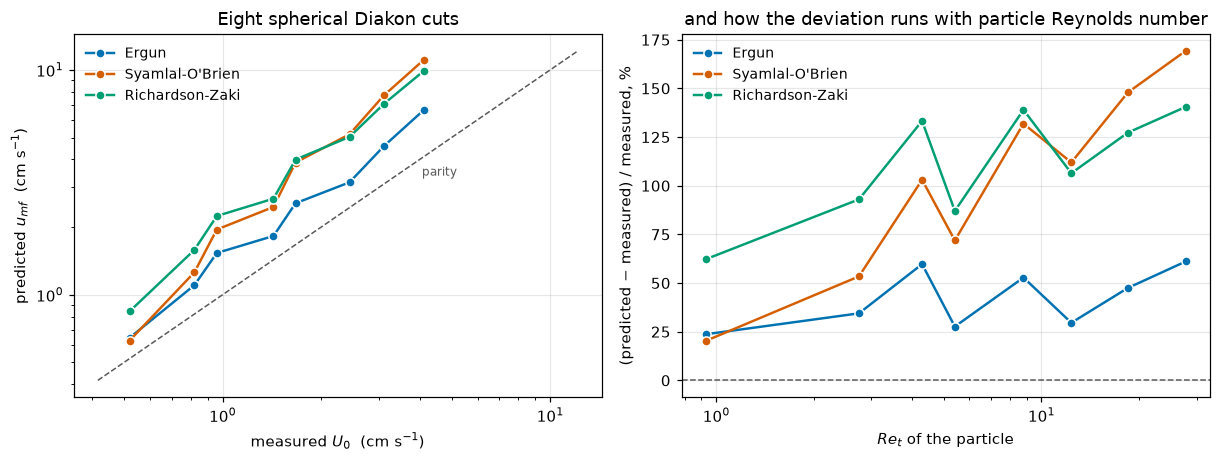

mean bias in % at each voidage reading, eight Diakon rows
                           Ergun  Syamlal-O'Brien  Richardson-Zaki
settled eps_0, per row     42.06           101.22           111.09
reported eps_MB, per row   58.43           118.86           134.93
0.383 for every row       -25.09            23.61            12.35
0.42 for every row          4.82            59.56            56.80
0.50 for every row        103.21           166.63           195.24


**Result, and what it does and does not rank.** All three closures overpredict every one of
the eight measured velocities at the settled voidage (8, 8 and 8 of 8 rows):
Ergun by **+42.1 %** on average (standard error 5.3 %), Syamlal-O'Brien by **+101.2 %** (17.7 %),
Richardson-Zaki by **+111.1 %** (10.1 %).

**What this dataset cannot settle is whether any closure is *right*.** The absolute bias is
controlled almost entirely by a voidage Geldart never measured directly: moving it from the derived
range of 0.441 to 0.498 to a textbook 0.42 takes Ergun from +42.1 % to +4.8 %. What it does support is
narrower, and it is read at every voidage tried (the table above: the settled and the reported
voidage, 0.383, 0.42 and 0.50). **Ergun has the smallest absolute bias at 4 of the five**, each by at least 3.98
standard errors of the paired difference over the eight rows. At 0.383 (the voidage Wen and Yu's
eq. (2) forces on a sphere, `A1.6`) Richardson-Zaki's absolute bias is smaller by 12.7 points
(standard error 16.9), so no closure is least biased there. Syamlal-O'Brien and Richardson-Zaki
are separated by more than two standard errors of their paired difference at only 1 of the
five, so no order of those two is claimed.

The cleanest way to see what is stable is to invert the question: the voidage each closure would
need in order to be unbiased on these eight rows.

| closure | voidage that erases its bias |
|---|---|
| Ergun | **0.4147** |
| Richardson-Zaki | 0.3708 |
| Syamlal-O'Brien | 0.3538 |

3 of the three closures need a voidage below the lowest settled voidage in the rows (0.441):
absorbing the bias into the voidage would need every voidage Geldart reports to be too high, and
by least for Ergun (a change of 0.043 from the mean settled voidage of 0.458, against
0.087 for Richardson-Zaki and 0.104 for Syamlal-O'Brien). **That is the ranking this page
supports**: not that Ergun is validated (it is
+42.1 % biased at the voidage the dataset's own columns imply, `A1.6` finds +58 % at Geldart's
reported $\epsilon_{MB}$, and an empirical $u_{mf}$ correlation with no drag law in it is
-25.2 % on these rows), but that it is the closure nearest to the data in this one sense, the change of voidage that would erase its bias.

**And the gap between the two families, stated as the algebra it is, not as a measurement.** The
Syamlal-O'Brien / Ergun ratio runs from **0.97 to 1.68**, and its largest value is on the cut of
263 µm: **1.6812** there against 1.6717 on the last cut of 318 µm, so it is **not
monotone in size or in $Re$**: it turns over before the last cut.

The Syamlal-O'Brien / Richardson-Zaki ratio stays inside **0.74 to 1.12**, and **that one
contains no measurement at all.** $u_{mf}^{SO} = \epsilon\,V_{rm}v_t$ and
$u_{mf}^{RZ} = \epsilon^{n_0(Re_t)}v_t$, so the terminal velocity **cancels identically** out of
their quotient, which is $\epsilon V_{rm}(\epsilon,Re_t)/\epsilon^{n_0(Re_t)}$, a function of
$(\epsilon_0, Re_t)$ alone (verified below to a relative 2e-16, the bound
`check4_vt_cancels_out_of_SO_over_RZ`). It is **Check 3's implied-index comparison re-evaluated at
Geldart's eight $(\epsilon_0, Re_t)$ pairs**, in different symbols, and it would read exactly the
same if Geldart had never run the experiment. It cannot detect an error in either terminal
velocity, in the shared eq. (16), or in Geldart's $U_0$ column. The S-O'/Ergun ratio is
predicted/predicted in the same sense; Geldart's $U_0$ enters only the per-cent columns. **Neither
ratio is measurement-facing evidence, and neither is offered as any.** What the measurement does
carry is the three bias columns above.

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(11.2, 4.3))
for c, k in zip(CLOSURES, ["ergun", "so", "rz"]):
    ax[0].plot(res["U_0 meas"], res[c], "o-", ms=6, lw=1.6, color=COL[k], mec="white", mew=1.0, label=c)
lo, hi = float(res["U_0 meas"].min()) * 0.8, float(res[CLOSURES].to_numpy().max()) * 1.1
ax[0].plot([lo, hi], [lo, hi], "--", color="0.35", lw=1)
ax[0].text(hi / 3, hi / 3.6, "parity", fontsize=8, color="0.35")
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("measured $U_0$  (cm s$^{-1}$)"); ax[0].set_ylabel("predicted $u_{mf}$  (cm s$^{-1}$)")
ax[0].set_title("Eight spherical Diakon cuts")
ax[0].legend(frameon=False, fontsize=9)
for c, k in zip(CLOSURES, ["ergun", "so", "rz"]):
    ax[1].plot(res["Re_t"], res[c + " %"], "o-", ms=6, lw=1.6, color=COL[k], mec="white", mew=1.0, label=c)
ax[1].axhline(0, color="0.35", lw=1, ls="--")
ax[1].set_xscale("log"); ax[1].set_xlabel("$Re_t$ of the particle")
ax[1].set_ylabel("(predicted $-$ measured) / measured, %")
ax[1].set_title("and how the deviation runs with particle Reynolds number")
ax[1].legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

ALT = pd.DataFrame({name: b for name, b in C4["_alt"].items()}).T
print("mean bias in % at each voidage reading, eight Diakon rows")
print(ALT.round(2).to_string())
say("""**Result, and what it does and does not rank.** All three closures overpredict every one of
the eight measured velocities at the settled voidage (@@o1@@, @@o2@@ and @@o3@@ of @@n@@ rows):
Ergun by **@@e@@ %** on average (standard error @@se@@ %), Syamlal-O'Brien by **@@s@@ %** (@@ss@@ %),
Richardson-Zaki by **@@r@@ %** (@@rs@@ %).

**What this dataset cannot settle is whether any closure is *right*.** The absolute bias is
controlled almost entirely by a voidage Geldart never measured directly: moving it from the derived
range of @@elo@@ to @@ehi@@ to a textbook 0.42 takes Ergun from @@e@@ % to @@e42@@ %. What it does support is
narrower, and it is read at every voidage tried (the table above: the settled and the reported
voidage, 0.383, 0.42 and 0.50). **Ergun has the smallest absolute bias at @@nleast@@ of the five**, each by at least @@zlead@@
standard errors of the paired difference over the eight rows. At 0.383 (the voidage Wen and Yu's
eq. (2) forces on a sphere, `A1.6`) Richardson-Zaki's absolute bias is smaller by @@rzlead@@ points
(standard error @@rzse@@), so no closure is least biased there. Syamlal-O'Brien and Richardson-Zaki
are separated by more than two standard errors of their paired difference at only @@nres@@ of the
five, so no order of those two is claimed.

The cleanest way to see what is stable is to invert the question: the voidage each closure would
need in order to be unbiased on these eight rows.

| closure | voidage that erases its bias |
|---|---|
| Ergun | **@@i1@@** |
| Richardson-Zaki | @@i3@@ |
| Syamlal-O'Brien | @@i2@@ |

@@ncl@@ of the three closures need a voidage below the lowest settled voidage in the rows (@@elo@@):
absorbing the bias into the voidage would need every voidage Geldart reports to be too high, and
by least for Ergun (a change of @@ergsmall@@ from the mean settled voidage of @@emean@@, against
@@c3@@ for Richardson-Zaki and @@c2@@ for Syamlal-O'Brien). **That is the ranking this page
supports**: not that Ergun is validated (it is
@@e@@ % biased at the voidage the dataset's own columns imply, `A1.6` finds @@emb@@ % at Geldart's
reported $\\epsilon_{MB}$, and an empirical $u_{mf}$ correlation with no drag law in it is
@@wy@@ % on these rows), but that it is the closure nearest to the data in this one sense, the change of voidage that would erase its bias.

**And the gap between the two families, stated as the algebra it is, not as a measurement.** The
Syamlal-O'Brien / Ergun ratio runs from **@@rmin@@ to @@rmax@@**, and its largest value is on the cut of
@@dmax@@ µm: **@@rmax4@@** there against @@rlast@@ on the last cut of @@dlast@@ µm, so it is **not
monotone in size or in $Re$**: it turns over before the last cut.

The Syamlal-O'Brien / Richardson-Zaki ratio stays inside **@@smin@@ to @@smax@@**, and **that one
contains no measurement at all.** $u_{mf}^{SO} = \\epsilon\\,V_{rm}v_t$ and
$u_{mf}^{RZ} = \\epsilon^{n_0(Re_t)}v_t$, so the terminal velocity **cancels identically** out of
their quotient, which is $\\epsilon V_{rm}(\\epsilon,Re_t)/\\epsilon^{n_0(Re_t)}$, a function of
$(\\epsilon_0, Re_t)$ alone (verified below to a relative @@cancel@@, the bound
`check4_vt_cancels_out_of_SO_over_RZ`). It is **Check 3's implied-index comparison re-evaluated at
Geldart's eight $(\\epsilon_0, Re_t)$ pairs**, in different symbols, and it would read exactly the
same if Geldart had never run the experiment. It cannot detect an error in either terminal
velocity, in the shared eq. (16), or in Geldart's $U_0$ column. The S-O'/Ergun ratio is
predicted/predicted in the same sense; Geldart's $U_0$ enters only the per-cent columns. **Neither
ratio is measurement-facing evidence, and neither is offered as any.** What the measurement does
carry is the three bias columns above.""",
    o1=C4["check4_rows_overpredicted_ergun"], o2=C4["check4_rows_overpredicted_syamlal_obrien"],
    o3=C4["check4_rows_overpredicted_richardson_zaki"], n=len(res),
    e=f"{C4['check4_ergun_bias_pct']:+.1f}", se=f"{C4['check4_ergun_bias_se_pct']:.1f}",
    s=f"{C4['check4_syamlal_obrien_bias_pct']:+.1f}", ss=f"{C4['check4_syamlal_obrien_bias_se_pct']:.1f}",
    r=f"{C4['check4_richardson_zaki_bias_pct']:+.1f}", rs=f"{C4['check4_richardson_zaki_bias_se_pct']:.1f}",
    elo=f"{dia.eps_0.min():.3f}", ehi=f"{dia.eps_0.max():.3f}", e42=f"{C4['check4_ergun_bias_pct_at_eps042']:+.1f}",
    nleast=C4["check4_ergun_least_abs_bias_voidages"], zlead=f"{C4['check4_ergun_lead_min_over_se']:.2f}",
    rzlead=f"{C4['check4_rz_lead_pts_eps0383']:.1f}", rzse=f"{C4['check4_rz_lead_se_pts_eps0383']:.1f}",
    nres=C4["check4_so_rz_order_resolved_voidages"],
    i1=f"{C4['check4_eps_erasing_ergun_bias']:.4f}", i2=f"{C4['check4_eps_erasing_syamlal_obrien_bias']:.4f}",
    i3=f"{C4['check4_eps_erasing_richardson_zaki_bias']:.4f}",
    ncl=C4["check4_closures_needing_voidage_below_table"],
    ergsmall=f"{abs(C4['check4_eps_erasing_ergun_bias'] - dia.eps_0.mean()):.3f}", emean=f"{dia.eps_0.mean():.3f}",
    c3=f"{abs(C4['check4_eps_erasing_richardson_zaki_bias'] - dia.eps_0.mean()):.3f}",
    c2=f"{abs(C4['check4_eps_erasing_syamlal_obrien_bias'] - dia.eps_0.mean()):.3f}",
    emb=f"{C4['check4_ergun_bias_pct_at_epsMB']:+.0f}", wy=f"{DEV_WY:+.1f}",
    rmin=f"{C4['ratio_SO_over_Ergun_min_diakon']:.2f}", rmax=f"{C4['ratio_SO_over_Ergun_max_diakon']:.2f}",
    dmax=f"{C4['ratio_SO_over_Ergun_max_row_d_sv_um']:.0f}", rmax4=f"{C4['ratio_SO_over_Ergun_max_diakon']:.4f}",
    rlast=f"{C4['ratio_SO_over_Ergun_last_cut_diakon']:.4f}", dlast=f"{C4['ratio_SO_over_Ergun_last_row_d_sv_um']:.0f}",
    smin=f"{C4['ratio_SO_over_RZ_min_diakon']:.2f}", smax=f"{C4['ratio_SO_over_RZ_max_diakon']:.2f}",
    cancel=f"{C4['check4_vt_cancels_out_of_SO_over_RZ']:.0e}")

#### The break table for Check 4

Each row injects one defect through the call that makes the prediction (a unit, a gas
property, a voidage, a closure constant, a table), and the claims of Check 4 are recomputed.

In [23]:
C4_NAMES = [n for n in C4 if not n.startswith("_")]
EF4_NAMES = list(EF4)
DEFECTS4 = [("d_sv taken as mm, not um -> cm (x10)", dict(dscale=1e-3)),
            ("mu a decimal place out (1.8e-5 poise)", dict(gel=dict(GEL, mu=1.8e-5))),
            ("rho_f a decimal place out (1.2e-2)", dict(gel=dict(GEL, rho=1.2e-2))),
            ("headline at eps_mf = 0.383 for every row", dict(eps_main=0.383)),
            ("headline at eps_mf = 0.42, the textbook value A1.6 uses", dict(eps_main=0.42)),
            ("headline at eps_mf = eps_MB, not the settled eps_0", dict(eps_main="eps_MB")),
            ("headline at eps_mf = 0.50 for every row", dict(eps_main=0.50)),
            ("A exponent 4.14 -> 4.65", dict(p=dict(P0, aexp=4.65))),
            ("C_D slope 4.8 -> 4.0", dict(p=dict(P0, cd1=4.0))),
            ("C_D offset 0.63 -> 0.44", dict(p=dict(P0, cd0=0.44))),
            ("Ergun on A1.1's refitted constants", dict(p=dict(P0, k1=K1_REFIT, k2=K2_REFIT))),
            ("Table VI: the n_0 column read one row low", dict(tab=rz.assign(n_0=rz.n_0.shift(1).fillna(rz.n_0.iloc[0])))),
            ("no-velocity route of the ratio built with the A exponent 4.65", dict(p_vt_other=dict(P0, aexp=4.65)))]
TAB4 = pd.DataFrame([dict(reading="as read", **mean_bias(res))]
                    + [dict(reading=n, **mean_bias(geldart_predict(
                        dia, **({"eps_all": kw["eps_main"]} if isinstance(kw.get("eps_main"), float) else
                                {"eps_col": kw["eps_main"]} if "eps_main" in kw else {"eps_col": "eps_0"}),
                        **{k: v for k, v in kw.items() if k in ("p", "gel", "dscale", "tab")})))
                       for n, kw in DEFECTS4 if "p_vt_other" not in kw])
print("mean bias in per cent, eight Diakon rows")
print(TAB4.to_string(index=False, float_format=lambda v: f"{v:+10.2f}"))
for row, kw in DEFECTS4:
    brk_helper(row, lambda **k: {n: v for n, v in check4_claims(**k).items() if not n.startswith("_")},
               C4_NAMES, **kw)
for row, kw in [("effects measured with the A exponent 4.65", dict(p=dict(P0, aexp=4.65))),
                ("effects measured with the gas viscosity a decimal place out", dict(gel=dict(GEL, mu=1.8e-5))),
                ("effects measured on Table VI read one row low",
                 dict(tab=rz.assign(n_0=rz.n_0.shift(1).fillna(rz.n_0.iloc[0])))),
                ("effects measured on the eight rows without the coarsest cut", dict(sub=dia.iloc[:-1]))]:
    brk_helper(row, effects4, EF4_NAMES, **kw)
say("""**The check has power, and the table says over what.** A unit slip moves the
Syamlal-O'Brien bias by **@@unit@@** points. Replacing the derived per-row voidage
(@@elo@@ to @@ehi@@) by a flat 0.50 moves it by @@d50@@ points, and by a flat 0.383 by @@d383@@, the
**largest real uncertainty on this comparison**, which is why the voidage is derived from
Geldart's own two columns rather than assumed, and why every alternative choice is reported rather
than one. It moves under the constants **Check 3 is blind to at every voidage**: the Dalla Valle
slope is worth @@dv@@ points here.

**Joint sufficiency.** With the Check 3 table swept over voidage, every printed constant of the
closure is exercised by Check 3 or by Check 4 **except the switch voidage**, whose effect is
bounded by the @@jb@@ % continuity measured in Results 4 and cannot exceed it for any switch displaced
inside the region where the two branches nearly coincide.

Two rows are worth reading as controls. The Ergun column does not move at all when a
Syamlal-O'Brien constant is perturbed (less than @@derb@@ points under the Dalla Valle slope, here @@der@@; the structural
bound `check4_dalla_valle_slope_points_ergun`) because the two closures share no code. **The
Richardson-Zaki column is a different matter: it moves @@drz@@ points under the same
perturbation**, because it takes its terminal velocity from the same eq. (16) curve by
construction. It is therefore *not* independent of Syamlal-O'Brien, and the invariance control
above should not be read as a general independence claim. The assumed gas density, the one input on
this page that Geldart does not print, is worth @@rho@@ points for a decade, so nothing here rests
on it. Ergun's own constants are worth less still: `A1.1`'s refit moves the Ergun bias by @@ref@@
points, against a gap to Syamlal-O'Brien of @@gap@@ points, so **the disagreement between the two
routes is @@ratio@@ times larger than what the uncertainty in Ergun's own constants is worth.**""",
    unit=f"{EF4['check4_unit_slip_points_so']:.0f}", elo=f"{dia.eps_0.min():.3f}", ehi=f"{dia.eps_0.max():.3f}",
    d50=f"{EF4['check4_flat_eps050_points_so']:.0f}", d383=f"{EF4['check4_flat_eps0383_points_so']:.0f}",
    dv=f"{EF4['check4_dalla_valle_slope_points_so']:.0f}", jb=f"{SWC['B_branch_jump_pct_at_switch']:+.3f}",
    der=f"{EF4['check4_dalla_valle_slope_points_ergun']:.0e}", derb="1e-9", drz=f"{EF4['check4_dalla_valle_slope_points_rz']:.0f}",
    rho=f"{EF4['check4_rho_f_decade_points_so']:.0f}", ref=f"{EF4['check4_ergun_refit_points']:.2f}",
    gap=f"{EF4['check4_route_gap_points']:.0f}", ratio=f"{EF4['check4_route_gap_over_refit']:.0f}")

mean bias in per cent, eight Diakon rows
                                                reading      Ergun  Syamlal-O'Brien  Richardson-Zaki
                                                as read     +42.06          +101.22          +111.09
                   d_sv taken as mm, not um -> cm (x10)   +5054.04         +5130.61         +5913.09
                  mu a decimal place out (1.8e-5 poise)    +892.25         +1090.39         +1138.98
                     rho_f a decimal place out (1.2e-2)     +31.64           +94.20           +85.80
               headline at eps_mf = 0.383 for every row     -25.09           +23.61           +12.35
headline at eps_mf = 0.42, the textbook value A1.6 uses      +4.82           +59.56           +56.80
     headline at eps_mf = eps_MB, not the settled eps_0     +58.43          +118.86          +134.93
                headline at eps_mf = 0.50 for every row    +103.21          +166.63          +195.24
                                A exponent 4.14 ->

**The check has power, and the table says over what.** A unit slip moves the
Syamlal-O'Brien bias by **5029** points. Replacing the derived per-row voidage
(0.441 to 0.498) by a flat 0.50 moves it by 65 points, and by a flat 0.383 by 78, the
**largest real uncertainty on this comparison**, which is why the voidage is derived from
Geldart's own two columns rather than assumed, and why every alternative choice is reported rather
than one. It moves under the constants **Check 3 is blind to at every voidage**: the Dalla Valle
slope is worth 63 points here.

**Joint sufficiency.** With the Check 3 table swept over voidage, every printed constant of the
closure is exercised by Check 3 or by Check 4 **except the switch voidage**, whose effect is
bounded by the +0.049 % continuity measured in Results 4 and cannot exceed it for any switch displaced
inside the region where the two branches nearly coincide.

Two rows are worth reading as controls. The Ergun column does not move at all when a
Syamlal-O'Brien constant is perturbed (less than 1e-9 points under the Dalla Valle slope, here 0e+00; the structural
bound `check4_dalla_valle_slope_points_ergun`) because the two closures share no code. **The
Richardson-Zaki column is a different matter: it moves 61 points under the same
perturbation**, because it takes its terminal velocity from the same eq. (16) curve by
construction. It is therefore *not* independent of Syamlal-O'Brien, and the invariance control
above should not be read as a general independence claim. The assumed gas density, the one input on
this page that Geldart does not print, is worth 7 points for a decade, so nothing here rests
on it. Ergun's own constants are worth less still: `A1.1`'s refit moves the Ergun bias by 1.74
points, against a gap to Syamlal-O'Brien of 59 points, so **the disagreement between the two
routes is 34 times larger than what the uncertainty in Ergun's own constants is worth.**

In [24]:
CTX = C4["_ctx"]
print(f"For completeness: all {len(CTX)} rows with a measured U_0, of which {len(CTX) - len(res)} have no sphericity")
print(pd.DataFrame([(c, CTX[c + " %"].mean(), CTX[c + " %"].abs().mean()) for c in CLOSURES],
                   columns=["closure", "bias %", "MAD %"]).round(2).to_string(index=False))
print("\nThe two cracking catalysts are porous, cohesive and printed with an approximate")
print("density, and their eps_0 runs far above Diakon's; the numbers above are context.")
_lo, _hi = float(rz.Re.min()), float(rz.Re.max())
print(f"\nTable VI covers Re {_lo:g} to {_hi:g}, and n_table6 HOLDS THE INDEX CONSTANT outside it.")
print(f"Of the {len(CTX)} context rows, {C4['check4_context_rows_clipped']} fall outside it "
      f"({', '.join(f'{v:.3f}' for v in sorted(CTX.Re_t[(CTX.Re_t < _lo) | (CTX.Re_t > _hi)]))}), so their "
      f"Richardson-Zaki prediction uses an extrapolated index.")
print(f"Of the {len(res)} Diakon rows the page takes its result on, {C4['check4_diakon_rows_clipped']} are "
      f"clipped: their Re_t runs {res.Re_t.min():.3f} to {res.Re_t.max():.3f}.")
print("The headline is unaffected; the context table is not, and that is why it is context.")

For completeness: all 21 rows with a measured U_0, of which 13 have no sphericity
        closure  bias %  MAD %
          Ergun  152.47 155.65
Syamlal-O'Brien  180.78 184.38
Richardson-Zaki  253.05 253.47

The two cracking catalysts are porous, cohesive and printed with an approximate
density, and their eps_0 runs far above Diakon's; the numbers above are context.

Table VI covers Re 0.39 to 489, and n_table6 HOLDS THE INDEX CONSTANT outside it.
Of the 21 context rows, 4 fall outside it (0.031, 0.114, 0.253, 0.304), so their Richardson-Zaki prediction uses an extrapolated index.
Of the 8 Diakon rows the page takes its result on, 0 are clipped: their Re_t runs 0.927 to 27.828.
The headline is unaffected; the context table is not, and that is why it is context.


In [25]:
def check5(tab=rz):
    """Table VI against its own two logarithm columns: the worst absolute residual of each."""
    return {"check5_tableVI_logRe_residual": float(np.max(np.abs(np.log10(tab.Re) - tab.log_Re))),
            "check5_tableVI_logn0_residual": float(np.max(np.abs(np.log10(tab.n_0) - tab.log_n0)))}


def slip_claims(i_n0=4, v_n0=41.7, i_re=10, v_re=1.82):
    """The residual when one printed digit is mis-read in each column (4.17 read as 41.7; 18.2 as 1.82)."""
    bad_n0, bad_re = rz.copy(), rz.copy()
    bad_n0.loc[i_n0, "n_0"] = v_n0
    bad_re.loc[i_re, "Re"] = v_re
    return {"check5_slip_residual_n0": check5(bad_n0)["check5_tableVI_logn0_residual"],
            "check5_slip_residual_Re": check5(bad_re)["check5_tableVI_logRe_residual"]}


C5, SL5 = check5(), slip_claims()
for name, v in C5.items():
    claims.bound(name, v, max=2e-3, basis="chosen",
                 note="the table prints Re, n_0 and their logarithms to a few digits; a one-digit slip "
                      "moves the residual to order one, so 2e-3 separates the two")
for name, v in SL5.items():
    claims.value(name, v, rtol=1e-3, note="residual with one printed digit mis-read")
print(f"worst |log10(Re) - printed log Re| = {C5['check5_tableVI_logRe_residual']:.2e}, "
      f"worst |log10(n_0) - printed log n_0| = {C5['check5_tableVI_logn0_residual']:.2e}")
say("""### Check 5: Table VI against its own logarithm columns

Richardson and Zaki print $\\log_{10}Re$ and $\\log_{10}n_0$ beside $Re$ and $n_0$.
The columns are redundant, so recomputing them tests this page's transcription of all
@@n@@ rows at once, and it is a check the *paper* pays for, in the sense of `docs/handoff.md`.

| | |
|---|---|
| worst absolute residual on the $\\log_{10}Re$ column | **@@a@@** (bound @@tol@@) |
| worst absolute residual on the $\\log_{10}n_0$ column | **@@b@@** (bound @@tol@@) |
| the same, with 4.17 mis-read as 41.7 | **@@c@@** |
| the same, with 18.2 mis-read as 1.82 | **@@d@@** |

Both residuals sit at the printed rounding, and a single-digit slip in either column moves
them by an order-unity amount. **This is also how one cell was read at all**: the
$\\log n_0$ entry on the $Re = @@re@@$ row is printed with a damaged digit, and the recomputed
logarithm of that row's $n_0$ leaves one two-decimal reading.""",
    n=len(rz), a=f"{C5['check5_tableVI_logRe_residual']:.1e}", b=f"{C5['check5_tableVI_logn0_residual']:.1e}",
    tol="2e-3", c=f"{SL5['check5_slip_residual_n0']:.2f}", d=f"{SL5['check5_slip_residual_Re']:.2f}",
    re=f"{rz.Re.iloc[4]:g}")
brk("n_0 of the fifth row read 41.7 instead of 4.17", "check5_tableVI_logn0_residual",
    SL5["check5_slip_residual_n0"])
brk("Re of the eleventh row read 1.82 instead of 18.2", "check5_tableVI_logRe_residual",
    SL5["check5_slip_residual_Re"])
brk("n_0 of the eighth row read 37.6 instead of 3.76", "check5_tableVI_logn0_residual",
    slip_claims(i_n0=7, v_n0=37.6)["check5_slip_residual_n0"])
brk("Re of the third row read 7.6 instead of 0.76", "check5_tableVI_logRe_residual",
    slip_claims(i_re=2, v_re=7.6)["check5_slip_residual_Re"])
brk_all("transposed digits instead of a slipped decimal point (4.17 as 4.71, 18.2 as 12.8)",
        slip_claims(v_n0=4.71, v_re=12.8))
brk("log Re column read one row low", "check5_tableVI_logRe_residual",
    check5(rz.assign(log_Re=rz.log_Re.shift(1).fillna(0.0)))["check5_tableVI_logRe_residual"])
brk("log n_0 column read one row low", "check5_tableVI_logn0_residual",
    check5(rz.assign(log_n0=rz.log_n0.shift(1).fillna(0.0)))["check5_tableVI_logn0_residual"])

worst |log10(Re) - printed log Re| = 8.04e-04, worst |log10(n_0) - printed log n_0| = 5.40e-04


### Check 5: Table VI against its own logarithm columns

Richardson and Zaki print $\log_{10}Re$ and $\log_{10}n_0$ beside $Re$ and $n_0$.
The columns are redundant, so recomputing them tests this page's transcription of all
18 rows at once, and it is a check the *paper* pays for, in the sense of `docs/handoff.md`.

| | |
|---|---|
| worst absolute residual on the $\log_{10}Re$ column | **8.0e-04** (bound 2e-3) |
| worst absolute residual on the $\log_{10}n_0$ column | **5.4e-04** (bound 2e-3) |
| the same, with 4.17 mis-read as 41.7 | **1.00** |
| the same, with 18.2 mis-read as 1.82 | **1.00** |

Both residuals sit at the printed rounding, and a single-digit slip in either column moves
them by an order-unity amount. **This is also how one cell was read at all**: the
$\log n_0$ entry on the $Re = 2.02$ row is printed with a damaged digit, and the recomputed
logarithm of that row's $n_0$ leaves one two-decimal reading.

True

In [26]:
say("""### Blind spots: what this page does **not** claim

- **Nothing about Gidaspow's closure or about Wen-Yu drag.** Neither *drag law*
  is in the document on disk. The $\\epsilon = 0.8$ discontinuity that a comparison of
  blended closures would be for is not computed here and is not asserted; the
  only switch measured on this page is Garside and Al-Dibouni's at @@sw@@, and it
  turns out to be continuous. (The report does cite Gidaspow extensively and
  adopts a Ding & Gidaspow expression elsewhere; what it does not print is a
  Gidaspow drag closure or a blend rule.)
- **The $B$ switch voidage is the one printed constant no check on this
  page settles**, when it is displaced by only a little. The Check 3 sweep
  catches it when the mis-read switch crosses an evaluation voidage, but a small
  displacement is bounded by the @@jb@@ % continuity of eq. (14) at the switch and
  cannot be worth more than that. It is settled by the page image, and by the
  continuity measurement in Results 4, not by any comparison against data.
- **Which of the two readings of $V_{rm}$ the report meant.** The whole of Check 3
  is one unit of index away from its alternative, and that alternative reverses
  the sign of the result. Both are printed; the page adopts the one eq. (11)
  implements and says so, and Garside & Al-Dibouni (1977), which would settle it,
  is not on disk.
- **Neither of the two ratios in Check 4 is measurement-facing.** $v_t$ cancels
  identically out of Syamlal-O'Brien / Richardson-Zaki, so that ratio is Check 3
  restated at Geldart's eight $(\\epsilon_0, Re_t)$ pairs; Geldart's $U_0$ enters only the
  per-cent columns. They are reported as algebra, not as evidence.
- **The Richardson-Zaki column is not independent of Syamlal-O'Brien.** Both take
  their terminal velocity from the same eq. (16), and the break table measures
  what that is worth: the Dalla Valle slope moves both, and Ergun neither.
- **`n_table6` holds Table VI's index constant outside its Reynolds range.** @@nclip@@ of the
  @@nctx@@ context rows sit outside it; @@nd@@ of the eight Diakon rows the result is taken on does.
- **The inertial half of every closure is essentially untested against
  measurement.** Every Geldart row is a group A powder with a single-particle $Re_t$ of at most
  @@ret@@ and a bed $Re_{mf}$ (on the measured slip) of at most @@rem@@. Table VI reaches
  $Re = @@remax@@$, but it constrains eqs. (12)-(14) only: Check 3 is exactly blind to
  the single-sphere curve.
- **No claim that Ergun is the reference.** The `A1.6` reconciliation above is
  the reason. On this dataset every closure overpredicts at the settled voidage, and which of the
  three readings `A1.6` leaves open is correct is not settled here either.
- **The non-Diakon rows are reported but carry no sphericity**, and
  Syamlal-O'Brien has no shape factor to give them, so the whole-table numbers
  printed above are context and are not the page's result.
- **Nothing on this page is digitised.** Both shipped datasets are transcribed
  tables; the one digitised dataset it loads is `A1.1`'s, and it is used only to
  bound Ergun's own constants. Its markers are not all of Ergun's measurements,
  and the refit inherits that page's stated recall limitation. It is used here only as a
  sensitivity, where a few scattered misses cannot matter.""",
    sw=f"{P0['bsw']:g}", jb=f"{SWC['B_branch_jump_pct_at_switch']:+.3f}",
    nclip=C4["check4_context_rows_clipped"], nctx=len(CTX), nd=C4["check4_diakon_rows_clipped"],
    ret=f"{C4['check4_Re_t_max_diakon']:.1f}", rem=f"{C4['check4_Re_mf_max_diakon']:.1f}",
    remax=f"{rz.Re.max():g}")

### Blind spots: what this page does **not** claim

- **Nothing about Gidaspow's closure or about Wen-Yu drag.** Neither *drag law*
  is in the document on disk. The $\epsilon = 0.8$ discontinuity that a comparison of
  blended closures would be for is not computed here and is not asserted; the
  only switch measured on this page is Garside and Al-Dibouni's at 0.85, and it
  turns out to be continuous. (The report does cite Gidaspow extensively and
  adopts a Ding & Gidaspow expression elsewhere; what it does not print is a
  Gidaspow drag closure or a blend rule.)
- **The $B$ switch voidage is the one printed constant no check on this
  page settles**, when it is displaced by only a little. The Check 3 sweep
  catches it when the mis-read switch crosses an evaluation voidage, but a small
  displacement is bounded by the +0.049 % continuity of eq. (14) at the switch and
  cannot be worth more than that. It is settled by the page image, and by the
  continuity measurement in Results 4, not by any comparison against data.
- **Which of the two readings of $V_{rm}$ the report meant.** The whole of Check 3
  is one unit of index away from its alternative, and that alternative reverses
  the sign of the result. Both are printed; the page adopts the one eq. (11)
  implements and says so, and Garside & Al-Dibouni (1977), which would settle it,
  is not on disk.
- **Neither of the two ratios in Check 4 is measurement-facing.** $v_t$ cancels
  identically out of Syamlal-O'Brien / Richardson-Zaki, so that ratio is Check 3
  restated at Geldart's eight $(\epsilon_0, Re_t)$ pairs; Geldart's $U_0$ enters only the
  per-cent columns. They are reported as algebra, not as evidence.
- **The Richardson-Zaki column is not independent of Syamlal-O'Brien.** Both take
  their terminal velocity from the same eq. (16), and the break table measures
  what that is worth: the Dalla Valle slope moves both, and Ergun neither.
- **`n_table6` holds Table VI's index constant outside its Reynolds range.** 4 of the
  21 context rows sit outside it; 0 of the eight Diakon rows the result is taken on does.
- **The inertial half of every closure is essentially untested against
  measurement.** Every Geldart row is a group A powder with a single-particle $Re_t$ of at most
  27.8 and a bed $Re_{mf}$ (on the measured slip) of at most 2.0. Table VI reaches
  $Re = 489$, but it constrains eqs. (12)-(14) only: Check 3 is exactly blind to
  the single-sphere curve.
- **No claim that Ergun is the reference.** The `A1.6` reconciliation above is
  the reason. On this dataset every closure overpredicts at the settled voidage, and which of the
  three readings `A1.6` leaves open is correct is not settled here either.
- **The non-Diakon rows are reported but carry no sphericity**, and
  Syamlal-O'Brien has no shape factor to give them, so the whole-table numbers
  printed above are context and are not the page's result.
- **Nothing on this page is digitised.** Both shipped datasets are transcribed
  tables; the one digitised dataset it loads is `A1.1`'s, and it is used only to
  bound Ergun's own constants. Its markers are not all of Ergun's measurements,
  and the refit inherits that page's stated recall limitation. It is used here only as a
  sensitivity, where a few scattered misses cannot matter.

## What pymrm adds

**To the closures themselves, nothing, and this page does not pretend otherwise.** No
operator is assembled, no Newton solve is run, and the closures, the limits and the
comparisons are NumPy and SciPy. What pymrm contributes is `pymrm.checks.find_roots`, and only
that. Every crossing, threshold and extremum on the page is a root of a scalar function on its
physical range, and `find_roots` scans the whole range and refines every sign change, so
a defect that leaves no root, or two, raises instead of returning a number; the break tables
rely on that. The roots are the terminal velocity of a sphere, the slip ratio at a force
balance, the two voidages at which the closures cross in the viscous limit and the one at which
they cross in the inertial limit, the minimum of the viscous-limit ratio (a root of its
analytic derivative), the Reynolds number at which the ratio of the two closures has its minimum
(a root of the analytic derivative of the ratio, found on 16 decades of $Re_m$), the voidage above
which that minimum stops being the lowest point, the Reynolds number above which the Ergun form
overshoots an isolated sphere, the voidage at which every row of Table VI lies below the implied
index, and the voidage that erases each closure's bias.

What the page adds as against reading the report:

- **The two families are put on one axis.** The report names them in one
  paragraph and then implements one. Written as drag coefficients they can be
  divided, and the quotient is a function of $(\epsilon_g, Re_m)$ that behaves
  much worse in the middle than at either end.
- **$V_{rm}$ is identified as a slip-velocity ratio and proved to be one, and
  the report's own prose is shown to contradict that.** The report never says
  what $V_{rm}$ is a ratio of, eq. (11) forces one answer and the sentence
  introducing $V_{rm}$ implies the other, and the two are one factor of
  $\epsilon_g$, one whole unit of index, apart. Both readings are printed with
  their numbers, because the sign of Check 3's result depends on which is right,
  and the document that would settle it is not on disk. Getting the factor from
  the momentum equations rather than by analogy is the reason that check means
  anything at all.
- **The substitution the report makes is costed, conditionally.** Eq. (12) exists
  because the Richardson-Zaki correlation is implicit, and nobody, including the
  report, says what that convenience costs. Under the reading eq. (11)
  implements it is a systematically larger index growing with voidage, whose
  viscous end is a one-line comparison of the exponent of eq. (13) plus one against the
  tabulated index.
- **Three closures meet a measurement none of them saw**, and the useful result
  is the shape of what it settles: not that any is right, since the absolute bias is
  a statement about an unmeasured voidage, but that Ergun is nearest to the data in the
  one sense the page can state, the change of voidage that would erase its bias, and that
  the order of the other two is not stable.
- **Two published pages are audited for free.** Four of `A1.6`'s numbers on this
  dataset are recomputed here by independent code and all reproduce, including
  the one that argues against this page's own first conclusion, and `A1.1`'s
  refit is reproduced from its own marker file.
- **The break table of Check 3 is swept over voidage**, so that the constants of the
  dilute branch of eq. (14) are exercised at all; the one constant it still cannot see is
  bounded rather than asserted.

## Reuse

### Lifting the closure

`F_syamlal_obrien(eps_g, v_slip, d_p, rho_g, mu_g)` and
`F_ergun(...)` are vectorised over $(\epsilon_g, v_{\text{slip}})$ and take every
constant from a dictionary, so they drop into a two-fluid residual unchanged. In
pymrm terms $F_{gm}$ is a **pointwise coefficient on a phase-coupled layout**,
`(n_z, n_phase)`, and the momentum equations it couples are `S7`/`S10`, not
`S3`. Three things to carry across:

1. **$Re_m$ is built on the slip velocity, not the terminal velocity** (eq. 15).
   Eq. (12) is therefore implicit whenever the slip velocity is what you are
   solving for; `V_rm_at_balance` shows the one-dimensional root find, and in a
   full model it is simply part of the residual.
2. **The $\epsilon_g$ in the force balance is on the mixture buoyancy.**
   $F v_{\text{slip}} = \epsilon_s\epsilon_g(\rho_s-\rho_g)g$, not
   $\epsilon_s(\rho_s-\rho_g)g$. Dropping it scales the drag by
   $1/\epsilon_g$, and what that does to the balance is measured in Check 2's
   break table.
3. **Neither closure has a sphericity.** Ergun's can be given one by writing
   $d_p \to \phi_s d_p$, and then the balance in $d_{sv}$ is exactly
   $\phi_s$-free; Syamlal-O'Brien has nowhere to put one, and the report says
   there is no accepted way to add it.

In [27]:
say("""### Choosing between them

The comparison on this page supports a narrow recommendation and no more:

- **In the two asymptotic limits at a packed-bed voidage the two sit within tens of per cent of
  each other**: at $\\epsilon_g = 0.44$ they differ by @@gv@@ % in the viscous limit and @@gi@@ % in the
  inertial one. These gaps are far larger than the uncertainty in Ergun's own constants (@@ref@@
  points of bias against @@gap@@ for the gap between the closures on Geldart's rows), and small
  enough to live with.
- **In the transition regime at packed-bed voidage they differ by nearly a factor of two** (the
  factor is @@fac@@ at 0.44), and that is where a fluidised powder sits. Which is right is not settled
  by anything on this page; that they differ, and by how much, is.
- **In dilute flow the packed-bed form is not usable at all** without a blend, and the numbers in
  Results 3 say how badly (@@p1@@ % of the isolated-sphere drag at $Re = 1$). Syamlal-O'Brien needs no
  blend.
- **Against a measured $u_{mf}$ all three overpredict at the voidage this dataset's own columns
  imply**, and an empirical $u_{mf}$ correlation with no drag law in it (@@wy@@ %) beats every one of
  them. If a minimum-fluidisation velocity is what you want,
  [`A1.6`](../A1.6-wen-yu-minimum-fluidisation/) is the page, and read its caveats, because they
  bound this page too.
- **On those rows Ergun has the smallest absolute bias at @@nl@@ of the five voidages tried, and needs
  the smallest change of voidage to be unbiased.** Do not read it as validation: the absolute bias is
  controlled by a voidage nobody measured, and moving it from the derived value to a textbook 0.42 takes
  Ergun from @@e0@@ % to @@e42@@ %, `A1.6`'s number recomputed here. The inversion in Check 4: Ergun
  needs $\\epsilon_{mf} = @@i1@@$ to be unbiased on these rows, Richardson-Zaki @@i3@@ and
  Syamlal-O'Brien @@i2@@, all below the lowest voidage Geldart reports.
- **Do not lift either Check 4 ratio as measured corroboration.** The terminal velocity cancels
  identically out of Syamlal-O'Brien / Richardson-Zaki, so the @@smin@@ to @@smax@@ band would read the
  same if the experiment had never been done. The measurement is in the bias columns, not in the
  ratios.""",
    gv=f"{DIP['limit_gap_viscous_pct_eps044']:.0f}", gi=f"{DIP['limit_gap_inertial_pct_eps044']:.0f}",
    ref=f"{EF4['check4_ergun_refit_points']:.2f}", gap=f"{EF4['check4_route_gap_points']:.0f}",
    fac=f"{DIP['disagreement_factor_eps044']:.2f}", p1=f"{DIL['ergun_isolated_Re1_pct']:.1f}",
    wy=f"{DEV_WY:+.1f}", nl=C4["check4_ergun_least_abs_bias_voidages"],
    e0=f"{C4['check4_ergun_bias_pct']:+.0f}", e42=f"{C4['check4_ergun_bias_pct_at_eps042']:+.1f}",
    i1=f"{C4['check4_eps_erasing_ergun_bias']:.3f}", i2=f"{C4['check4_eps_erasing_syamlal_obrien_bias']:.3f}",
    i3=f"{C4['check4_eps_erasing_richardson_zaki_bias']:.3f}",
    smin=f"{C4['ratio_SO_over_RZ_min_diakon']:.2f}", smax=f"{C4['ratio_SO_over_RZ_max_diakon']:.2f}")

### Choosing between them

The comparison on this page supports a narrow recommendation and no more:

- **In the two asymptotic limits at a packed-bed voidage the two sit within tens of per cent of
  each other**: at $\epsilon_g = 0.44$ they differ by 19 % in the viscous limit and 4 % in the
  inertial one. These gaps are far larger than the uncertainty in Ergun's own constants (1.74
  points of bias against 59 for the gap between the closures on Geldart's rows), and small
  enough to live with.
- **In the transition regime at packed-bed voidage they differ by nearly a factor of two** (the
  factor is 1.73 at 0.44), and that is where a fluidised powder sits. Which is right is not settled
  by anything on this page; that they differ, and by how much, is.
- **In dilute flow the packed-bed form is not usable at all** without a blend, and the numbers in
  Results 3 say how badly (7.9 % of the isolated-sphere drag at $Re = 1$). Syamlal-O'Brien needs no
  blend.
- **Against a measured $u_{mf}$ all three overpredict at the voidage this dataset's own columns
  imply**, and an empirical $u_{mf}$ correlation with no drag law in it (-25.2 %) beats every one of
  them. If a minimum-fluidisation velocity is what you want,
  [`A1.6`](../A1.6-wen-yu-minimum-fluidisation/) is the page, and read its caveats, because they
  bound this page too.
- **On those rows Ergun has the smallest absolute bias at 4 of the five voidages tried, and needs
  the smallest change of voidage to be unbiased.** Do not read it as validation: the absolute bias is
  controlled by a voidage nobody measured, and moving it from the derived value to a textbook 0.42 takes
  Ergun from +42 % to +4.8 %, `A1.6`'s number recomputed here. The inversion in Check 4: Ergun
  needs $\epsilon_{mf} = 0.415$ to be unbiased on these rows, Richardson-Zaki 0.371 and
  Syamlal-O'Brien 0.354, all below the lowest voidage Geldart reports.
- **Do not lift either Check 4 ratio as measured corroboration.** The terminal velocity cancels
  identically out of Syamlal-O'Brien / Richardson-Zaki, so the 0.74 to 1.12 band would read the
  same if the experiment had never been done. The measurement is in the bias columns, not in the
  ratios.

### What would complete the case

The catalogue asks for **Gidaspow / Syamlal-O'Brien / Wen-Yu** and this page
delivers one of the three plus two substitutes. Two documents would close it, and
neither can be replaced by memory:

- **Gidaspow, D. (1994), *Multiphase Flow and Fluidization*, Academic Press**,
  for the blend rule and the voidage at which it switches. Everything else needed
  to evaluate it is already on this page: the Ergun branch is built here, and the
  jump at the switch is a two-line computation once the rule is printed.
- **Wen, C. Y. and Yu, Y. H. (1966), *Mechanics of fluidization*, Chem. Eng.
  Progr. Symposium Series No. 62, 62, 100-111**, for the drag correlation. Note
  this is a **different paper** from the `A.I.Ch.E. Journal` communication on
  disk, which `A1.6` is built from and which contains no drag law; the Symposium
  Series paper is that communication's own reference 23.

### Related

[`A1.1`](../A1.1-ergun-pressure-drop/) (the packed-bed branch, and the source of
every Ergun constant here), [`A1.6`](../A1.6-wen-yu-minimum-fluidisation/) (the
$u_{mf}$ correlation, and the caveats that bound Check 4),
[`A1.7`](../A1.7-geldart-classification/) (the measured dataset and the derived
voidage), `A1.5` (Richardson-Zaki in its own right: the paper is on disk and
this page uses one of its tables), [`E1.2`](../E1.2-davidson-bubble/) and
[`E2.1`](../E2.1-kunii-levenspiel-bubbling-bed/) (fluidised-bed models that
consume $u_{mf}$ rather than a drag law).

In [28]:
# Claims: prints every registered number, writes agreement.json for CI, and
# raises when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for A1.8:
  refit_vs_A11_k1_gap                                     = (here 0.0e+00)   bound  bound <= 1e-09 [chosen]
  refit_vs_A11_k2_gap                                     = (here 0.0e+00)   bound  bound <= 1e-09 [chosen]
  ergun_refit_k1_shift_pct                                = 1.291            value  rtol 1e-06
  ergun_refit_k2_shift_pct                                = -3.0454          value  rtol 1e-06
  ergun_markers_rows                                      = 244              exact  exact
  geldart_rows                                            = 22               exact  exact
  geldart_rows_with_U0                                    = 21               exact  exact
  geldart_diakon_rows                                     = 8                exact  exact
  eps0_all_min                                            = 0.44144          value  rtol 1e-06
  eps0_all_max                                            = 0.57045          value  rtol 1e-06
  eps0_diakon_min          